In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier, BaggingClassifier, GradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

In [2]:
TARGET = "Golongan UKT"                                    # kolom yang ditebak
NUM_COLS = ["Jumlah Tanggungan dalam Keluarga", "Pengeluaran Bulanan Keluarga", "Daya Listrik (Watt)", "Luas Tanah Rumah (m2)", "Luas Bangunan Rumah (m2)", "NJOP per Meter", "Rerata Pengeluaran Listrik & Air per Bulan", "Total Hutang", "Cicilan Hutang per Bulan",
            "Jumlah (Perkiraan Harga Pasar) Kendaraan yang Dimiliki"]   # kolom angka (kendaraan: dulu terlewat)
CAT_COLS = ["Pendapatan Keluarga", "Pekerjaan Orang Tua/Wali", "Pendidikan Orang Tua/Wali", "Status Kepesertaan Program Bantuan Pemerintah", "Riwayat Beasiswa atau Bantuan Pendidikan", "Ayah Hidup?", "Ibu Hidup?", "Status Kepemilikan Tempat Tinggal", "Bahan Atap Rumah", "Bahan Tembok Rumah", "Bahan Lantai Rumah", "Program Studi", "Jalur Masuk"]            # kolom kategori (teks)
SEED = 42

In [3]:
"""Pipeline EDA dari Laya EDA. Jalankan dari atas ke bawah; setiap `# %%` adalah satu langkah.

Aturan: split dulu, lalu statistik (median, batas outlier, daftar kategori) dihitung dari train SAJA
dan dipakai ke valid dan test; baris hanya dibuang dari train (valid dan test tidak pernah dibuang)."""
# %% baca data
TRAIN_CSV = 'data/train.csv'
TEST_CSV = ''   # kosongkan bila tidak ada file test
LABEL = 'Golongan UKT'
train = pd.read_csv(TRAIN_CSV)
test = pd.read_csv(TEST_CSV) if TEST_CSV else train.iloc[:0].drop(columns=[LABEL], errors="ignore")
print("train", train.shape, "test", test.shape)


# %% split data
# split acak, 20% ke valid, stratified (random_state=42); statistik langkah sesudah ini dari train saja
from sklearn.model_selection import train_test_split
BAGIAN_VALID = 0.2
train, valid = train_test_split(train, test_size=BAGIAN_VALID, random_state=42, stratify=train[LABEL])
train, valid = train.sort_index().copy(), valid.sort_index().copy()   # kembalikan urutan baris asli
print("train", train.shape, "valid", valid.shape)


# %% langkah 1: Rapikan teks + penanda kosong · Bahan Atap Rumah, Bahan Lantai Rumah, Bahan Tembok Rumah…
KOLOM_TEKS = ['Bahan Atap Rumah',
 'Bahan Lantai Rumah',
 'Bahan Tembok Rumah',
 'Riwayat Beasiswa atau Bantuan Pendidikan']
PENANDA_KOSONG = ['', '-', '--', '?', 'n/a', 'na', 'nan', 'none', 'null', 'tidak tahu']
for df in (train, valid, test):
    for kolom in KOLOM_TEKS:
        teks = df[kolom].astype(str).str.strip().str.replace(r"\s+", " ", regex=True)
        df[kolom] = teks.where(df[kolom].notna() & ~teks.str.lower().isin(PENANDA_KOSONG))


# %% langkah 2: Nilai penjaga → kosong · Pengeluaran Bulanan Keluarga, Jumlah (Perkiraan Harga Pasar) Kendaraan yang Dimiliki, Luas Tanah Rumah (m2)…
KOLOM_PENJAGA = ['Pengeluaran Bulanan Keluarga',
 'Jumlah (Perkiraan Harga Pasar) Kendaraan yang Dimiliki',
 'Luas Tanah Rumah (m2)',
 'NJOP per Meter',
 'Rerata Pengeluaran Listrik & Air per Bulan',
 'Total Hutang',
 'Cicilan Hutang per Bulan']
BATAS_PENJAGA = 2_000_000_000  # 2.147.483.647 (2^31 - 1) dan variannya
for df in (train, valid, test):
    df[KOLOM_PENJAGA] = df[KOLOM_PENJAGA].mask(df[KOLOM_PENJAGA] >= BATAS_PENJAGA)


# %% langkah 3: Isi nilai tetap · Status Kepesertaan Program Bantuan Pemerintah
ISI_TETAP = {'Status Kepesertaan Program Bantuan Pemerintah': 'Tidak'}
for df in (train, valid, test):
    df.fillna(ISI_TETAP, inplace=True)


# %% langkah 4: Rapikan teks + penanda kosong · Pendapatan Keluarga, Pekerjaan Orang Tua/Wali, Pendidikan Orang Tua/Wali…
KOLOM_TEKS = ['Pendapatan Keluarga',
 'Pekerjaan Orang Tua/Wali',
 'Pendidikan Orang Tua/Wali',
 'Kepemilikan Aset',
 'Lokasi Tempat Tinggal',
 'Status Kepesertaan Program Bantuan Pemerintah',
 'Riwayat Beasiswa atau Bantuan Pendidikan',
 'Ayah Hidup?',
 'Ibu Hidup?',
 'Status Kepemilikan Tempat Tinggal',
 'Bahan Atap Rumah',
 'Bahan Tembok Rumah',
 'Bahan Lantai Rumah',
 'Program Studi',
 'Kota',
 'Jalur Masuk']
PENANDA_KOSONG = ['', '-', '--', '?', 'nan', 'null', 'none', 'n/a', 'na', 'tidak tahu']
for df in (train, valid, test):
    for kolom in KOLOM_TEKS:
        teks = df[kolom].astype(str).str.strip().str.replace(r"\s+", " ", regex=True)
        df[kolom] = teks.where(df[kolom].notna() & ~teks.str.lower().isin(PENANDA_KOSONG))


# %% langkah 5: Buang kolom · id
KOLOM_DIBUANG = ['id']
train = train.drop(columns=KOLOM_DIBUANG)
valid = valid.drop(columns=KOLOM_DIBUANG)
test = test.drop(columns=KOLOM_DIBUANG, errors="ignore")


# %% langkah 6: Buang baris banyak kosong (train)
MAKS_KOSONG_PER_BARIS = 13
sebelum = len(train)
train = train[train.isna().sum(axis=1) <= MAKS_KOSONG_PER_BARIS].copy()
print("baris terlalu banyak kosong dibuang:", sebelum - len(train))


# %% langkah 7: Buang baris banyak kosong (train)
MAKS_KOSONG_PER_BARIS = 13
sebelum = len(train)
train = train[train.isna().sum(axis=1) <= MAKS_KOSONG_PER_BARIS].copy()
print("baris terlalu banyak kosong dibuang:", sebelum - len(train))


# %% langkah 8: Buang baris banyak kosong (train)
MAKS_KOSONG_PER_BARIS = 13
sebelum = len(train)
train = train[train.isna().sum(axis=1) <= MAKS_KOSONG_PER_BARIS].copy()
print("baris terlalu banyak kosong dibuang:", sebelum - len(train))


# %% langkah 9: Buang kolom · Kota
KOLOM_DIBUANG = ['Kota']
train = train.drop(columns=KOLOM_DIBUANG)
valid = valid.drop(columns=KOLOM_DIBUANG)
test = test.drop(columns=KOLOM_DIBUANG, errors="ignore")


# %% langkah 10: Buang kolom · Kepemilikan Aset, Lokasi Tempat Tinggal
KOLOM_DIBUANG = ['Kepemilikan Aset', 'Lokasi Tempat Tinggal']
train = train.drop(columns=KOLOM_DIBUANG)
valid = valid.drop(columns=KOLOM_DIBUANG)
test = test.drop(columns=KOLOM_DIBUANG, errors="ignore")


# %% langkah 11: Satukan ejaan (peta nilai) · Pendidikan Orang Tua/Wali (5 nilai)
PETA_PENDIDIKAN_ORANG_TUA_WAL = {'SMA': 'SLTA', 'SLTP': 'SMP', 'S- 2': 'S-2', 'D.1': 'D-1', 'S- 3': 'S-3'}
for df in (train, valid, test):
    ganti = df['Pendidikan Orang Tua/Wali'].isin(PETA_PENDIDIKAN_ORANG_TUA_WAL.keys())
    df.loc[ganti, 'Pendidikan Orang Tua/Wali'] = df.loc[ganti, 'Pendidikan Orang Tua/Wali'].map(PETA_PENDIDIKAN_ORANG_TUA_WAL)


# %% langkah 12: Satukan ejaan (peta nilai) · Riwayat Beasiswa atau Bantuan Pendidikan (1 nilai)
PETA_RIWAYAT_BEASISWA_ATAU_BA = {'KIPK': 'kipk'}
for df in (train, valid, test):
    ganti = df['Riwayat Beasiswa atau Bantuan Pendidikan'].isin(PETA_RIWAYAT_BEASISWA_ATAU_BA.keys())
    df.loc[ganti, 'Riwayat Beasiswa atau Bantuan Pendidikan'] = df.loc[ganti, 'Riwayat Beasiswa atau Bantuan Pendidikan'].map(PETA_RIWAYAT_BEASISWA_ATAU_BA)


# %% langkah 13: Satukan ejaan (peta nilai) · Bahan Atap Rumah (755 nilai)
PETA_BAHAN_ATAP_RUMAH = {'genteng': 'Genteng',
 'genting': 'Genting',
 'GENTENG': 'Genteng',
 'genting tanah liat': 'Genting tanah liat',
 'GENTING': 'Genting',
 'seng': 'Seng',
 'asbes': 'Asbes',
 'genteng tanah liat': 'Genteng tanah liat',
 'Genting Tanah Liat': 'Genting tanah liat',
 'ASBES': 'Asbes',
 'Genteng Tanah Liat': 'Genteng tanah liat',
 'SENG': 'Seng',
 'GENTING TANAH LIAT': 'Genting tanah liat',
 'tanah liat': 'Tanah liat',
 'GENTENG TANAH LIAT': 'Genteng tanah liat',
 'Tanah Liat': 'Tanah liat',
 'kayu': 'Kayu',
 'genting tanah': 'Genting tanah',
 'genteng tanah': 'Genteng tanah',
 'TANAH LIAT': 'Tanah liat',
 'genteng dan asbes': 'Genteng dan asbes',
 'Genting Tanah liat': 'Genting tanah liat',
 'Baja Ringan': 'Baja ringan',
 'Genteng beton': 'Genteng Beton',
 'Genteng Tanah': 'Genteng tanah',
 'genting dan asbes': 'Genting dan asbes',
 'Genting Tanah': 'Genting tanah',
 'baja ringan': 'Baja ringan',
 'Genteng dan Asbes': 'Genteng dan asbes',
 'Genting Beton': 'Genting beton',
 'Genting dan Asbes': 'Genting dan asbes',
 'KAYU': 'Kayu',
 'genteng beton': 'Genteng Beton',
 'Asbes/seng': 'Asbes/Seng',
 'Genteng Tanah liat': 'Genteng tanah liat',
 'genting dari tanah liat': 'Genting dari tanah liat',
 'beton': 'Beton',
 'Esbes': 'esbes',
 'galvalum': 'Galvalum',
 'asbes/seng': 'Asbes/Seng',
 'GENTENG TANAH': 'Genteng tanah',
 'spandek': 'Spandek',
 'GENTING TANAH': 'Genting tanah',
 'Asbes dan genteng': 'Genteng dan asbes',
 'BAJA RINGAN': 'Baja ringan',
 'GENTENG BETON': 'Genteng Beton',
 'genteng dan seng': 'Genteng dan seng',
 'genting tanah liat dan asbes': 'Genting tanah liat dan asbes',
 'genteng dari tanah liat': 'Genteng dari tanah liat',
 'Asbes dan genting': 'Genting dan asbes',
 'asbes dan genteng': 'Genteng dan asbes',
 'kayu dan genteng': 'Kayu dan genteng',
 'GENTENG DAN ASBES': 'Genteng dan asbes',
 'asbes dan genting': 'Genting dan asbes',
 'Genteng dan Seng': 'Genteng dan seng',
 'genting dan seng': 'Genting dan seng',
 'genting beton': 'Genting beton',
 'GALVALUM': 'Galvalum',
 'Genting dan Seng': 'Genting dan seng',
 'Asbes dan Genteng': 'Genteng dan asbes',
 'tanah': 'Tanah',
 'gendeng': 'Gendeng',
 'seng dan genteng': 'Genteng dan seng',
 'Genting (tanah liat)': 'Genting tanah liat',
 'Kayu dan Genting': 'kayu dan genting',
 'GENTING DAN ASBES': 'Genting dan asbes',
 'multiroof': 'Multiroof',
 'Kayu dan genting': 'kayu dan genting',
 'ESBES': 'esbes',
 'Cor': 'cor',
 'Asbes dan Genting': 'Genting dan asbes',
 'Asbes dan seng': 'asbes dan seng',
 'plafon': 'Plafon',
 'GentIng': 'Genting',
 'Genting, tanah liat': 'Genting tanah liat',
 'Kayu dan Genteng': 'Kayu dan genteng',
 'Genteng biasa': 'genteng biasa',
 'genting tanah liat dan seng': 'Genting tanah liat dan seng',
 'Genting (Tanah Liat)': 'Genting tanah liat',
 'Seng dan asbes': 'asbes dan seng',
 'SPANDEK': 'Spandek',
 'genteng metal': 'Genteng metal',
 'Genteng Press': 'genteng press',
 'seng dan asbes': 'asbes dan seng',
 'semen': 'Semen',
 'GENDENG': 'Gendeng',
 'ASBES/SENG': 'Asbes/Seng',
 'GENTING DARI TANAH LIAT': 'Genting dari tanah liat',
 'BETON': 'Beton',
 'Genting Tanah LIat': 'Genting tanah liat',
 'Asbes dan Seng': 'asbes dan seng',
 'Seng dan genting': 'Genting dan seng',
 'Asbes dan genting tanah liat': 'Genting tanah liat dan asbes',
 'Seng dan Asbes': 'asbes dan seng',
 'KAYU DAN GENTING': 'kayu dan genting',
 'TERNIT': 'Ternit',
 'Genteng (tanah liat)': 'Genteng tanah liat',
 'Genting tanah liat.': 'Genting tanah liat',
 'Genteng tanah liat.': 'Genteng tanah liat',
 'Genting dari Tanah Liat': 'Genting dari tanah liat',
 'bambu': 'Bambu',
 'spandex': 'Spandex',
 'Genteng merah': 'genteng merah',
 'Atap Tanah Liat': 'Atap tanah liat',
 'Eternit': 'eternit',
 'genteng asbes': 'Genteng, Asbes',
 'Atap seng': 'atap seng',
 'KAYU DAN GENTENG': 'Kayu dan genteng',
 'Genteng dari Tanah Liat': 'Genteng dari tanah liat',
 'genteng dan kayu': 'Kayu dan genteng',
 'genting/tanah liat': 'Genting tanah liat',
 'Genteng Metal': 'Genteng metal',
 'Tanah liat (genting)': 'Genting tanah liat',
 'Genting/Tanah liat': 'Genting tanah liat',
 'Genteng dan Kayu': 'Kayu dan genteng',
 'Genteng Berbahan Tanah Liat': 'Genteng berbahan tanah liat',
 'genteng tanah liat dan asbes': 'Genteng tanah liat dan asbes',
 'Seng dan Genteng': 'Genteng dan seng',
 'asbes dan genting tanah liat': 'Genting tanah liat dan asbes',
 'BAMBU': 'Bambu',
 'atap genteng': 'Genteng atap',
 'Atap genteng tanah liat': 'Atap Genteng Tanah Liat',
 'Genting/tanah liat': 'Genting tanah liat',
 'genting dari tanah': 'Genting dari tanah',
 'Tanah liat/genting': 'Genting tanah liat',
 'GENTENG DARI TANAH LIAT': 'Genteng dari tanah liat',
 'Asbes/ seng': 'Asbes/Seng',
 'kenteng': 'Kenteng',
 'Genting / Tanah liat': 'Genting tanah liat',
 'genteng (tanah liat)': 'Genteng tanah liat',
 'PLAFON': 'Plafon',
 'geting': 'Geting',
 'Genteng Merah': 'genteng merah',
 'Genteng tanah liat dan Asbes': 'Genteng tanah liat dan asbes',
 'genteng/asbes': 'Genteng, Asbes',
 'Genteng/tanah liat': 'Genteng tanah liat',
 'atap genteng tanah liat': 'Atap Genteng Tanah Liat',
 'cor coran': 'Cor-coran',
 'ETERNIT': 'eternit',
 'GENTENG(TANAH LIAT)': 'Genteng tanah liat',
 'ASBES DAN SENG': 'asbes dan seng',
 'COR': 'cor',
 'Genting Tanah Liat dan Asbes': 'Genting tanah liat dan asbes',
 'genteng keramik': 'Genteng Keramik',
 'Asbes dan Genteng Tanah Liat': 'Genteng tanah liat dan asbes',
 'Genteng, seng': 'Genteng seng',
 'Genteng, Seng': 'Genteng seng',
 'Genteng (Tanah Liat)': 'Genteng tanah liat',
 'Seng/Asbes': 'Asbes/Seng',
 'genting dan kayu': 'kayu dan genting',
 'Genteng keramik': 'Genteng Keramik',
 'Genteng.': 'Genteng',
 'Genteng(tanah liat)': 'Genteng tanah liat',
 'metal': 'Metal',
 'seng asbes': 'Asbes/Seng',
 'genting biasa': 'Genting biasa',
 'genteng, seng': 'Genteng seng',
 'GENTING BETON': 'Genting beton',
 'ternit': 'Ternit',
 'kayu dan genteng tanah liat': 'Kayu dan genteng tanah liat',
 'SEMEN': 'Semen',
 'Genteng dan kayu': 'Kayu dan genteng',
 'Bambu dan genting': 'Bambu dan Genting',
 'Genteng semen': 'Genteng Semen',
 'seng dan genting': 'Genting dan seng',
 'Genting dan kayu': 'kayu dan genting',
 'Genting bata': 'Genting Bata',
 'Asbes & Genteng': 'Genteng, Asbes',
 'kayu genteng': 'Kayu + Genteng',
 'Genteng (Tanah liat)': 'Genteng tanah liat',
 'Atap Seng': 'atap seng',
 'genting (tanah liat)': 'Genting tanah liat',
 'Genting(Tanah Liat)': 'Genting tanah liat',
 'dak': 'Dak',
 'Genting sintetis': 'genting sintetis',
 'Genteng Tanah Liat dan Seng': 'Genteng tanah liat dan seng',
 'Genting dan bambu': 'Bambu dan Genting',
 'Asbes/Genteng': 'Genteng, Asbes',
 'Genteng & Seng': 'Genteng seng',
 'genteng, tanah liat': 'Genteng tanah liat',
 'GENTENG BIASA': 'genteng biasa',
 'Genting.': 'Genting',
 'genting tanah liat dan kayu': 'Kayu dan genting tanah liat',
 'GENTENG DAN SENG': 'Genteng dan seng',
 'Genting tanah liat dan Asbes': 'Genting tanah liat dan asbes',
 'Genteng Bata': 'genteng bata',
 'Seng galvalum': 'seng galvalum',
 'GENTING DAN GALVALUM': 'Genting dan galvalum',
 'GENTING (TANAH LIAT)': 'Genting tanah liat',
 'genteng+asbes': 'Genteng, Asbes',
 'Asbes dan Galvalum': 'Galvalum dan asbes',
 'Genteng Beton dan Asbes': 'Asbes dan genteng beton',
 'Genting Sintesis': 'Genting sintesis',
 'GENTENG MERAH': 'genteng merah',
 'Genteng Tanah LIat': 'Genteng tanah liat',
 'Asbes dan Genting tanah liat': 'Genting tanah liat dan asbes',
 'genting/ tanah liat': 'Genting tanah liat',
 'Genteng Metal Pasir': 'genteng metal pasir',
 'Genteng + Asbes': 'Genteng, Asbes',
 'Asbes dan kayu': 'Kayu dan asbes',
 'Seng/asbes': 'Asbes/Seng',
 'Asbes dan galvalum': 'Galvalum dan asbes',
 'SENG DAN ASBES': 'asbes dan seng',
 'TANAH LIAT(GENTING)': 'Genting tanah liat',
 'Genteng tanah dan Asbes': 'Genteng tanah dan asbes',
 'Galfalum': 'galfalum',
 'genteng,seng': 'Genteng seng',
 'GENTING TANAH LIAT DAN ASBES': 'Genting tanah liat dan asbes',
 'seng dan genting tanah liat': 'Genting tanah liat dan seng',
 'GENTING/TANAH LIAT': 'Genting tanah liat',
 'Genting tanah lihat': 'genting tanah lihat',
 'baja ringan dan genteng': 'Baja Ringan dan Genteng',
 'genteng/tanah liat': 'Genteng tanah liat',
 'kayu dan genting tanah liat': 'Kayu dan genting tanah liat',
 'MULTIROOF': 'Multiroof',
 'Genteng sintesis': 'genteng sintesis',
 'Genteng/Tanah liat': 'Genteng tanah liat',
 'Genteng,asbes': 'Genteng, Asbes',
 'GENTING DAN SENG': 'Genting dan seng',
 'Seng dan genteng': 'Genteng dan seng',
 'Genteng press': 'genteng press',
 'genting(tanah liat)': 'Genting tanah liat',
 'beton/dak': 'Dak beton',
 'GENTING & ASBES': 'Genting & Asbes',
 'Genting, kayu': 'Genting kayu',
 'atap tanah liat': 'Atap tanah liat',
 'GENTENG dan ASBES': 'Genteng dan asbes',
 'Genteng Pres': 'Genteng pres',
 'TRIPLEK': 'Triplek',
 'Genting, Asbes': 'Genting & Asbes',
 'Genting Sintetis': 'genting sintetis',
 'Atap Genteng': 'Genteng atap',
 'atap genting tanah liat': 'Atap genting tanah liat',
 'Genteng Tanah Liat dan Asbes': 'Genteng tanah liat dan asbes',
 'Genteng sintetis': 'Genteng Sintetis',
 'ASBES & GENTENG': 'Genteng, Asbes',
 'genteng tanah liat dan seng': 'Genteng tanah liat dan seng',
 'Asbes & Genting': 'Genting & Asbes',
 'genteng ( tanah liat )': 'Genteng tanah liat',
 'Genting dan Kayu': 'kayu dan genting',
 'Genting & Seng': 'Genting, seng',
 'KENTENG': 'Kenteng',
 'Tanah Liat (Genteng)': 'Genteng tanah liat',
 'Genting tanah liat dan seng.': 'Genting tanah liat dan seng',
 'Asbes, Genteng': 'Genteng, Asbes',
 'Genteng baja ringan': 'genteng baja ringan',
 'Genteng tanah Liat': 'Genteng tanah liat',
 'Genteng, tanah liat': 'Genteng tanah liat',
 'genteng batu bata': 'Genteng Batu Bata',
 'GENTING BATU BATA': 'Genting batu bata',
 'Genteng Biasa': 'genteng biasa',
 'Genteng, asbes': 'Genteng, Asbes',
 'genteng tanah dan asbes': 'Genteng tanah dan asbes',
 'genting tanah liat dan bambu': 'Genting tanah liat dan bambu',
 'Atap Asbes': 'Atap asbes',
 'Genting dan Galvalum': 'Genting dan galvalum',
 'ASBES DAN GENTENG': 'Genteng dan asbes',
 'genting sintesis': 'Genting sintesis',
 'GENTENG KERAMIK': 'Genteng Keramik',
 'Genting (Tanah liat)': 'Genting tanah liat',
 'Seng dan Genting': 'Genting dan seng',
 'ATAP TANAH LIAT': 'Atap tanah liat',
 'Asbes / seng': 'Asbes/Seng',
 'GENTING DAN KAYU': 'kayu dan genting',
 'genting,seng': 'Genting, seng',
 'Genteng atau tanah liat': 'genteng atau tanah liat',
 'tanah liat genteng': 'Genteng tanah liat',
 'Genteng tanah liat dan esbes': 'genteng tanah liat dan esbes',
 'Genting Tanah liat dan Asbes': 'Genting tanah liat dan asbes',
 'Multi roof': 'Multi Roof',
 'kayu/genteng': 'Kayu + Genteng',
 'Genting dari tanah liat.': 'Genting dari tanah liat',
 'GENTING DARI TANAH': 'Genting dari tanah',
 'GETENG': 'Geteng',
 'Atap genteng': 'Genteng atap',
 'multi roof': 'Multi Roof',
 'genteng, kayu': 'Kayu + Genteng',
 'Seng/Spandek': 'seng spandek',
 'Genting semen': 'Genting Semen',
 'genting/asbes': 'Genting & Asbes',
 'Asbes, genteng, seng': 'Asbes, seng, genteng',
 'Asbes/seng, genteng': 'Asbes, seng, genteng',
 'Genting + Asbes': 'Genting & Asbes',
 'Genteng dan esbes': 'Genteng dan Esbes',
 'Genteng Bata Merah': 'Genteng bata merah',
 'Genting tanah liat dan Seng': 'Genting tanah liat dan seng',
 'genteng, asbes, seng': 'Asbes, seng, genteng',
 'Genting,tanah liat': 'Genting tanah liat',
 'Asbes, dan genting': 'Genting dan asbes',
 'Seng/ Galvalum': 'seng galvalum',
 'GentIng Tanah Liat': 'Genting tanah liat',
 'genteng Keramik': 'Genteng Keramik',
 'Campuran': 'campuran',
 'GENTING ( tanah liat )': 'Genting tanah liat',
 'Seng,Genteng': 'Genteng seng',
 'dak cor': 'Dak cor',
 'genting yang terbuat dari tanah liat': 'Genting yang terbuat dari tanah liat',
 'Bambu Genting': 'Genting Bambu',
 'Beton dan Asbes': 'Beton dan asbes',
 'GENTING TANAH DAN ASBES': 'Genting tanah dan asbes',
 'Seng/genteng': 'Genteng seng',
 'Tanah Liat Genting': 'Genting tanah liat',
 'Kayu,Genting': 'Genting kayu',
 'genting bahan tanah liat': 'Genting bahan tanah liat',
 'genteng, asbes': 'Genteng, Asbes',
 'genting tanah liat, asbes, dan seng': 'Genting tanah liat, asbes, dan seng.',
 'Genting Batu Bata': 'Genting batu bata',
 'tanah liat (Genteng)': 'Genteng tanah liat',
 'Genteng bata': 'genteng bata',
 'Genteng & Asbes': 'Genteng, Asbes',
 'Multiroof/Seng': 'seng multiroof',
 'Genteng & esbes': 'Genteng,Esbes',
 'GENTING SEBAGIAN SENG': 'sebagian genting, sebagian seng',
 'Galvalum-seng': 'seng galvalum',
 'asbes dan cor': 'cor dan asbes',
 'seng dan genteng tanah liat': 'Genteng tanah liat dan seng',
 'genting kayu': 'Genting kayu',
 'genting tanah dan asbes': 'Genting tanah dan asbes',
 'Baja ringan / genteng': 'genteng baja ringan',
 'Seng Multiroof': 'seng multiroof',
 'ASBES DAN GENTING': 'Genting dan asbes',
 'genting dan baja ringan': 'Genting dan baja ringan',
 'Seng, genteng': 'Genteng seng',
 'Genting, Tanah Liat': 'Genting tanah liat',
 'GentIng tanah liat': 'Genting tanah liat',
 'Seng galfalum': 'seng/galfalum',
 'genting tanah liat biasa': 'Genting tanah liat biasa',
 'genting (tanah)': 'Genting tanah',
 'TANAH LIAT/ GENTING': 'Genting tanah liat',
 'asbes,genting': 'Genting & Asbes',
 'kayu dan seng': 'KAYU DAN SENG',
 'Genting Bahan Tanah Liat': 'Genting bahan tanah liat',
 'Spandek/Seng': 'seng spandek',
 'genteng , plafon': 'Genteng plafon',
 'genting asbes': 'Genting & Asbes',
 'Dak semen': 'Semen / Dak',
 'esbes dan genting': 'GENTING dan ESBES',
 'MULTIROOF/SENG': 'seng multiroof',
 'Genting(tanah liat)': 'Genting tanah liat',
 'Tanah liat genting': 'Genting tanah liat',
 'genting&bambu': 'Genting Bambu',
 'Tanah LIat': 'Tanah liat',
 'Genting Asbes': 'Genting & Asbes',
 'gentIng': 'Genting',
 'Genting keramik': 'Genting Keramik',
 'GENTING SOKA': 'genting soka',
 'Kayu,genteng': 'Kayu + Genteng',
 'genting tanah liat, dan asbes': 'Genting tanah liat dan asbes',
 'ASBES+GENTING': 'Genting & Asbes',
 'genting tanah liat & seng': 'Genting tanah liat, seng',
 'Genting Dari Tanah Liat': 'Genting dari tanah liat',
 'Internit': 'internit',
 'Kayu kalimantan': 'Kayu Kalimantan',
 'seng atau asbes': 'asbes atau seng',
 'Genting tanah liat. Dan asbes': 'Genting tanah liat dan asbes',
 'tanah liat/genteng': 'Genteng tanah liat',
 'Tanah liat dan Asbes': 'Asbes dan tanah liat',
 'genteng/atap tanah liat': 'Atap Genteng Tanah Liat',
 'Tanah liat / Genting': 'Genting tanah liat',
 'Genting tanah liat,': 'Genting tanah liat',
 'Tanah liat Genting': 'Genting tanah liat',
 'Tanah Liat ( Genteng )': 'Genteng tanah liat',
 'Asbes & genteng': 'Genteng, Asbes',
 'Genting & asbes': 'Genting & Asbes',
 'Galvalum dan genting': 'Genting dan galvalum',
 'Rangka baja ringan': 'Rangka Baja Ringan',
 'Bambu, Genting': 'Genting Bambu',
 'beton dan asbes': 'Beton dan asbes',
 'KAYU GENTENG': 'Kayu + Genteng',
 'plafon asbes': 'plafon/asbes',
 'Asbes, Genting': 'Genting & Asbes',
 'Genteng, Asbes dan Seng': 'Genteng, seng, dan asbes',
 'Kayu, Genteng': 'Kayu + Genteng',
 'Atap tanah': 'atap tanah',
 'genteng merah/tanah liat': 'Genteng merah tanah liat',
 'ASBES dan GENTENG': 'Genteng dan asbes',
 'Geteng Tanah Liat': 'Geteng Tanah liat',
 'Asbes+Genteng': 'Genteng, Asbes',
 'Tanah liat dan asbes': 'Asbes dan tanah liat',
 'Asbes / Seng': 'Asbes/Seng',
 'Genteng Dan Asbes': 'Genteng dan asbes',
 'Genteng dan beton': 'Genteng dan Beton',
 'Tanah Liat (genting)': 'Genting tanah liat',
 'Tanah/genteng': 'Genteng tanah',
 'Genting (tanah)': 'Genting tanah',
 'Tanah Liat/Genting': 'Genting tanah liat',
 'Genting Tanah Liat Biasa': 'Genting tanah liat biasa',
 'Genting, Bambu.': 'Genting Bambu',
 'Kayu, genting,': 'Genting kayu',
 'DAK BETON': 'Dak beton',
 'kayu,genting': 'Genting kayu',
 'Dak Semen': 'Semen / Dak',
 'tanah liat/genting': 'Genting tanah liat',
 'Genteng tanah liat dan bambu': 'Bambu dan genteng tanah liat',
 'Asbes dan genteng tanah liat': 'Genteng tanah liat dan asbes',
 'Tanah liat (Genteng)': 'Genteng tanah liat',
 'genting + asbes': 'Genting & Asbes',
 'Genting glazur': 'Genting Glazur',
 'beton, asbes': 'asbes, beton',
 'seng,genteng,asbes': 'Asbes, seng, genteng',
 'geteng': 'Geteng',
 'genteng sintetis': 'Genteng Sintetis',
 'Genteng/ Tanah Liat': 'Genteng tanah liat',
 'Geneng': 'GENENG',
 'geteng tanah liat': 'Geteng Tanah liat',
 'genting dan esbes.': 'GENTING dan ESBES',
 'GENTENG ASBES': 'Genteng, Asbes',
 'Asbes atau seng': 'asbes atau seng',
 'GENTING ASBES': 'Genting & Asbes',
 'Genteng/ tanah liat': 'Genteng tanah liat',
 'Kayu dan Genting tanah liat': 'Kayu dan genting tanah liat',
 'dak beton': 'Dak beton',
 'genteng dan baja ringan': 'Baja Ringan dan Genteng',
 'Gendeng Tanah Liat': 'Gendeng tanah liat',
 'Genting Biasa': 'Genting biasa',
 'Tanah liat genting asbes': 'genting tanah liat, asbes',
 'Gipsum': 'gipsum',
 'Kayu dan seng': 'KAYU DAN SENG',
 'kayu, genteng': 'Kayu + Genteng',
 'GENTNG TANAH LIAT': 'Gentng tanah liat',
 'Genting Tanah Liat dan sebagian Asbes': 'Genting tanah liat dan sebagian asbes',
 'Sebagian genting dan sebagian asbes': 'Genting dan sebagian asbes',
 'genteng tanah liat, dan seng': 'Genteng tanah liat dan seng',
 'Genting/Tanah Liat': 'Genting tanah liat',
 'Genting/Seng': 'Genting, seng',
 'Genteng tanah liat dan Seng': 'Genteng tanah liat dan seng',
 'ASBES,GENTING': 'Genting & Asbes',
 'Asbes/genteng tanah liat': 'Genteng tanah liat & asbes',
 'Beton Plester': 'beton/plester',
 'Genting tanah liat, asbes': 'genting tanah liat, asbes',
 'GENTING tanah liat': 'Genting tanah liat',
 'Genting soka': 'genting soka',
 'Genteng asbes': 'Genteng, Asbes',
 'genting/tanah': 'Genting tanah',
 'asbes dan genteng beton': 'Asbes dan genteng beton',
 'Genteng beton dan asbes': 'Asbes dan genteng beton',
 'GENTENG,ASBES': 'Genteng, Asbes',
 'ASBES, GENTENG': 'Genteng, Asbes',
 'Genting dari Tanah': 'Genting dari tanah',
 'semen beton': 'Semen/beton',
 'SENG DAN TANAH LIAT': 'Tanah liat dan seng',
 'SENG,GENTENG,ASBES': 'Asbes, seng, genteng',
 'Genting, asbes': 'Genting & Asbes',
 'Tanah liat ( Genteng )': 'Genteng tanah liat',
 'Genteng & asbes': 'Genteng, Asbes',
 'GENTING DAN ESBES': 'GENTING dan ESBES',
 'Genting dan esbes': 'GENTING dan ESBES',
 'Genteng, seng, kayu': 'Kayu, Genteng, Seng',
 'Atap Spandek': 'atap spandek',
 'Genteng Tanah liat dan kayu': 'Kayu dan genteng tanah liat',
 'tanah liat / genteng': 'Genteng tanah liat',
 'GENTING GLAZUR': 'Genting Glazur',
 'Geting Tanah Liat': 'geting tanah liat',
 'genteng dan plafon': 'Genteng dan plafon',
 'seng, asbes': 'Asbes/Seng',
 'gentIng tanah liat': 'Genting tanah liat',
 'genteng,seng,asbes': 'Asbes, seng, genteng',
 'Tanah liat, asbes': 'Asbes, tanah liat',
 'Atap beton': 'atap beton',
 'GENTHENG': 'Gentheng',
 'Genting tanah liat dan kayu': 'Kayu dan genting tanah liat',
 'GENTENG & ASBES': 'Genteng, Asbes',
 'Baja': 'baja',
 'Genteng Baja Ringan': 'genteng baja ringan',
 'Genting tanah liat, Asbes': 'genting tanah liat, asbes',
 'multiruf': 'Multiruf',
 'SENG DAN GENTENG': 'Genteng dan seng',
 'GENTENG BAJA RINGAN': 'genteng baja ringan',
 'Genteng metal pasir': 'genteng metal pasir',
 'Genting Tanah Liat dan Seng': 'Genting tanah liat dan seng',
 'genting atau asbes': 'Asbes atau genting',
 'GENTING TANAH LIAT DAN BAMBU': 'Genting tanah liat dan bambu',
 'Genting Pres': 'genting pres',
 'Kayu dan bambu': 'Bambu dan kayu',
 'Multyroof': 'multyroof',
 'kayu, genteng tanah liat': 'Kayu / Genteng tanah liat',
 'Seng (galvalum)': 'seng galvalum',
 'Genting, Tanah liat': 'Genting tanah liat',
 'tanah liat (genteng)': 'Genteng tanah liat',
 'Ternit dan Genting': 'Genting dan ternit',
 'Gentig': 'gentig',
 'GENTENG/ASBES': 'Genteng, Asbes',
 'Genteng galfalum': 'GENTENG&GALFALUM',
 'Asbes + Genteng': 'Genteng, Asbes',
 'genting tanahliat': 'GENTING TANAHLIAT',
 'TIDAK ADA': 'Tidak Ada',
 'Tanah liat/genteng': 'Genteng tanah liat',
 'GENTiNG': 'Genting',
 'Genteng tanah liat, asbes': 'Genteng tanah liat & asbes',
 'GENTING/GENTENG TANAH LIAT': 'Genteng/Genting Tanah Liat',
 'Genteng dan Bambu': 'genteng dan bambu',
 'kayu asbes': 'Asbes, kayu',
 'Geting tanah liat': 'geting tanah liat',
 'GENTING dan ASBES': 'Genting dan asbes',
 'genteng pres': 'Genteng pres',
 'Cor / Genteng': 'Genteng Cor',
 'asbes, seng, genteng tanah liat': 'Asbes/seng/Genteng tanah liat',
 'Genteng/tanah Liat': 'Genteng tanah liat',
 'GENTENG BATU': 'genteng batu',
 'Tanah Liat ( Genting )': 'Genting tanah liat',
 'seng multirup': 'Seng Multirup',
 'genting,tanah liat': 'Genting tanah liat',
 'Asbes / genting tanah liat': 'genting tanah liat, asbes',
 'Tanah liat(Genteng)': 'Genteng tanah liat',
 'genteng + asbes': 'Genteng, Asbes',
 'GENTENG Tanah liat': 'Genteng tanah liat',
 'asbes genteng': 'Genteng, Asbes',
 'kernit': 'Kernit',
 'Kayu dan genteng tanah': 'Genteng tanah dan kayu',
 'GENTENG + ASBES': 'Genteng, Asbes',
 'rangka baja': 'Rangka Baja',
 'ATAP GENTING TANAH LIAT': 'Atap genting tanah liat',
 'genteng,asbes,seng': 'Asbes, seng, genteng',
 'Genting Tanah Liat.': 'Genting tanah liat',
 'Genteng, asbes, dan seng': 'Genteng, seng, dan asbes',
 'seng spandex': 'Seng Spandex',
 'genteng/tanah': 'Genteng tanah',
 'BAMBU DAN SENG': 'bambu dan seng',
 'seng, asbes, genteng': 'Asbes, seng, genteng',
 'Galvalum dan genteng': 'Genteng dan galvalum',
 'Genting Kayu': 'Genting kayu',
 'Genteng/baja ringan': 'genteng baja ringan',
 'KAYU JATI': 'kayu jati',
 'seng biasa': 'Seng biasa',
 'Kayu, genteng': 'Kayu + Genteng',
 'asbes, genteng': 'Genteng, Asbes',
 'Cor - Coran': 'Cor-coran',
 'GENTENG TANAH LIAT, DAN ASBES': 'Genteng tanah liat dan asbes',
 'Atap seng dan genting tanah liat': 'genting tanah liat dan atap seng',
 'Beton / genteng': 'Genteng Beton',
 'Genting Metal': 'Genting metal',
 'Genteng/seng': 'Genteng seng',
 'BAMBU DAN KAYU': 'Bambu dan kayu',
 'GENTING SINTESIS': 'Genting sintesis',
 'asbes / genteng': 'Genteng, Asbes',
 'GENTENG MERAH DAN ASBES': 'asbes dan genteng merah',
 'Semen (Dak)': 'Semen / Dak',
 'Genting merah': 'GENTING MERAH',
 'genting press': 'Genting press',
 'seng (galvalum)': 'seng galvalum',
 'Seng, Asbes': 'Asbes/Seng',
 'TAHAN LIAT': 'tahan liat',
 'GENTENG SEMEN': 'Genteng Semen',
 'Batu Bata': 'batu bata',
 'Genting/Bambu': 'Genting Bambu',
 'genteng kramik': 'Genteng kramik',
 'Kayu, Genting Tanah Liat': 'Kayu, genting tanah liat',
 'seng,asbes': 'Asbes/Seng',
 'Genting, kayu, asbes': 'kayu, genting, asbes',
 'asbes dan genteng tanah': 'Genteng tanah dan asbes',
 'genting sebagian asbes': 'Asbes, Sebagian Genting',
 'GENTING BATA': 'Genting Bata',
 'Seng spandek': 'seng spandek',
 'genting tanah liat.': 'Genting tanah liat',
 'genting dan sebagian asbes': 'Genting dan sebagian asbes',
 'Genting, Kayu, Bambu': 'Kayu + bambu, genting',
 'genteng berbahan tanah liat': 'Genteng berbahan tanah liat',
 'Genting(tanah liat dan asbes': 'Genting tanah liat dan asbes',
 'genteng,kayu,bambu': 'KAYU,BAMBU,GENTENG',
 'tanah liat/ genting': 'Genting tanah liat',
 'Genteng/keramik': 'Genteng Keramik',
 'Tanah liat /genteng': 'Genteng tanah liat',
 'Asbes, Seng Galvalum': 'galvalum, asbes, seng',
 'genting kualitas rendah': 'Genting kualitas rendah',
 'Seng, Genteng': 'Genteng seng',
 'genteng tanah liat, seng, asbes': 'Asbes/seng/Genteng tanah liat',
 'Seng gelombang': 'seng gelombang',
 'asbes Dan genteng': 'Genteng dan asbes',
 'Genting,asbes': 'Genting & Asbes',
 'seng metal': 'Seng Metal',
 'genteng Tanah liat': 'Genteng tanah liat',
 'Cor Beton': 'Cor beton',
 'genteng dan beton': 'Genteng dan Beton',
 'genteng cor': 'Genteng Cor',
 'Tanah liat.': 'Tanah liat',
 'Sebagian genting tanah liat dan asbes': 'Genting tanah liat dan sebagian asbes',
 'ASBAS': 'Asbas',
 'SENG SPANDEK': 'seng spandek',
 'genteng kayu': 'Kayu + Genteng',
 'Asbes, seng': 'Asbes/Seng',
 'spandek galvalum': 'spandek / galvalum',
 'genteng jatiwangi': 'Genteng jatiwangi',
 'GENTENG TANAH LIAT DAN SENG': 'Genteng tanah liat dan seng',
 'Genting Dan Asbes': 'Genting dan asbes',
 'Genteng Mantili': 'genteng mantili',
 'Genteng(Tanah liat)': 'Genteng tanah liat',
 'asbes dan gendeng': 'Gendeng dan Asbes',
 'Genting dan Beton': 'Beton dan genting',
 'Tanah Liat/Genteng': 'Genteng tanah liat',
 'Seng Galvalum': 'seng galvalum',
 'asbes dan beton': 'Beton dan asbes',
 'Baja ringan dan genteng': 'Baja Ringan dan Genteng',
 'Genteng dan bambu': 'genteng dan bambu',
 'Atap Genting Tanah Liat': 'Atap genting tanah liat',
 'Genting tanah liat, rangka atap kayu': 'Rangka atap kayu genting tanah liat',
 'genting, asbes': 'Genting & Asbes',
 'atap genteng tanah': 'Atap Genteng Tanah',
 'ASBES-SENG': 'Asbes/Seng',
 'Atap Baja Ringan': 'Atap baja ringan',
 'ATAP GENTENG (TANAH LIAT)': 'Atap Genteng Tanah Liat',
 'ESBES DAN GENTENG': 'Genteng dan Esbes',
 'Atap Tanah liat': 'Atap tanah liat',
 'Genteng, beton': 'Genteng Beton',
 'Kayu kelapa': 'kayu kelapa',
 'Genteng sederhana': 'genteng sederhana',
 'Genting Merah': 'GENTING MERAH',
 'KAYU dan GENTING': 'kayu dan genting',
 'Baja ringan , genteng': 'genteng baja ringan',
 'Genteng + Seng': 'Genteng seng',
 'GENTENG TANAH LIAT & ASBES': 'Genteng tanah liat & asbes',
 'GENTENG TANAH LIHAT': 'genteng tanah lihat',
 'asbes, genteng, seng': 'Asbes, seng, genteng',
 'Genting Tanah Liat/Asbes': 'genting tanah liat, asbes',
 'Tanah genting': 'Genting tanah',
 'Beton cor': 'Cor beton',
 'Genteng Tanah dan Asbes': 'Genteng tanah dan asbes',
 'genting merah': 'GENTING MERAH',
 'KAYU dan GENTENG': 'Kayu dan genteng',
 'asbes/genteng tanah liat': 'Genteng tanah liat & asbes',
 'Batu bata': 'batu bata',
 'ATAP GENTENG TANAH LIAT': 'Atap Genteng Tanah Liat',
 'alumunium': 'Alumunium',
 'galvalum spandek': 'spandek / galvalum',
 'Genteng, asbes, seng': 'Asbes, seng, genteng',
 'Genting + asbes': 'Genting & Asbes',
 'Plafon.': 'Plafon',
 'Tanah / Genting': 'Genting tanah',
 'bambu dan kayu': 'Bambu dan kayu',
 'Seng metal': 'Seng Metal',
 'Kayu/Genteng': 'Kayu + Genteng',
 'Genteng,Asbes,Seng': 'Asbes, seng, genteng',
 'Asbes dan Genteng cor': 'Genteng cor dan asbes',
 'GENTING, SENG, ASBES': 'Asbes, seng, genting',
 'Genting, seng, dan asbes': 'Genting dan Asbes (Seng)',
 'Genteng dan baja ringan': 'Baja Ringan dan Genteng',
 'genteng Tanah': 'Genteng tanah',
 'plafon, genteng': 'Genteng plafon',
 'genteng semen': 'Genteng Semen',
 'GENTENG SEDERHANA': 'genteng sederhana',
 'Genteng cor': 'Genteng Cor',
 'Genteng , tanah liat': 'Genteng tanah liat',
 'genteng, asbes, dan galvalum': 'asbes,genteng,dan galvalum',
 'Genteng Plentong': 'Genteng plentong',
 'Asbes, Cor,': 'Asbes + Cor',
 'genting semen': 'Genting Semen',
 'ATAP BETON': 'atap beton',
 'rangka baja ringan': 'Rangka Baja Ringan',
 'Genting asbes': 'Genting & Asbes',
 'Genting Tanah LIat dan Asbes': 'Genting tanah liat dan asbes',
 'Tanah liat (genteng)': 'Genteng tanah liat',
 'genteng/Tanah liat': 'Genteng tanah liat',
 'Kayu/atap genteng': 'Kayu & atap genteng',
 'TANAH LIAT/GENTING': 'Genting tanah liat',
 'Kayu dan Genting tanah': 'KAYU DAN GENTING TANAH',
 'Tanah (genteng)': 'Genteng tanah',
 'Genting Tanah Liat dan seng': 'Genting tanah liat dan seng',
 'zeng': 'Zeng',
 'coran': 'Coran',
 'Seng dan genteng tanah liat': 'Genteng tanah liat dan seng',
 'Seng,Asbes,Genteng': 'Asbes, seng, genteng',
 'ALUMINIUM': 'Aluminium',
 'GENTENG PRES': 'Genteng pres',
 'Bambu, kayu dan genteng (tanah liat)': 'kayu,bambu dan genteng tanah liat',
 'GENTENG DAN KAYU': 'Kayu dan genteng',
 'Seng dan genting tanah liat': 'Genting tanah liat dan seng',
 'seng/genting': 'Genting, seng',
 'Genteng Biasa (Tanah Liat)': 'Tanah liat (genteng biasa)',
 'GENTENG METAL': 'Genteng metal',
 'SENG DAN MULTI ROOF': 'Multi Roof dan Seng',
 'keramik': 'Keramik',
 'genting, dari tanah liat': 'Genting dari tanah liat',
 'Genting, dan Seng': 'Genting dan seng',
 'Seng baja ringan': 'Seng Baja Ringan',
 'Genting/kayu': 'Genting kayu',
 'Genting,asbes dan seng': 'Genting dan Asbes (Seng)',
 'Genting tanah liat dan esbes': 'genting tanah liat dan esbes',
 'tanah liat (genting)': 'Genting tanah liat',
 'Genteng batu bata': 'Genteng Batu Bata',
 'Galfalum & Genteng': 'GENTENG&GALFALUM',
 'Geting tanah': 'geting tanah',
 'Genteng dan sebagian asbes': 'Sebagian genteng dan sebagian asbes',
 'kayu, genting': 'Genting kayu',
 'Asbes/Seng/Genting': 'Asbes, seng, genting',
 'ZINK': 'Zink',
 'Genting liat': 'genting liat',
 'Genteng dan ternit': 'ternit dan genteng',
 'SENG/ASBES': 'Asbes/Seng',
 'genting, tanah liat': 'Genting tanah liat',
 'TANAH': 'Tanah',
 'Genting,Asbes': 'Genting & Asbes',
 'Seng & Asbes': 'Asbes/Seng',
 'ASBES/ SENG': 'Asbes/Seng',
 'Genting atau tanah liat': 'Tanah liat atau genting',
 'Genting tanah liat/seng': 'Genting tanah liat, seng',
 'Genting(Tanah liat)': 'Genting tanah liat',
 'asbes gelombang kecil': 'Asbes gelombang kecil',
 'Genting pres': 'genting pres',
 'BAJA RINGAN + GENTENG': 'genteng baja ringan',
 'Genteng tanah liat & baja ringan': 'genteng tanah liat, baja ringan',
 'Kayu & Genting': 'Genting kayu',
 'Seng/Genting': 'Genting, seng',
 'Gypsum': 'gypsum',
 'Sebagian genteng dan asbes': 'Sebagian genteng dan sebagian asbes',
 'Genting/Galvalum': 'galvalum & genting',
 'Seng multirup': 'Seng Multirup',
 'Tidak ada': 'Tidak Ada',
 'GENTING TAHAN LIAT': 'Genting tahan liat',
 'Genting tanahliat': 'GENTING TANAHLIAT',
 'Genteng, kayu, bambu': 'KAYU,BAMBU,GENTENG',
 'tanah liat dan asbes': 'Asbes dan tanah liat',
 'genting Tanah liat': 'Genting tanah liat',
 'Multirup': 'multirup',
 'genting/gendeng': 'gendeng/genting',
 'Genting tanah liat merah': 'Genting merah ( tanah liat )',
 'kayu dan bambu': 'Bambu dan kayu',
 'Cor- coran': 'Cor-coran',
 'Asbes Genteng': 'Genteng, Asbes',
 'Genteng sebagian asbes': 'Genteng, sebagian asbes',
 'GENTENG, ASBES': 'Genteng, Asbes',
 'Genteng Kayu': 'Kayu + Genteng',
 'genteng dan esbes': 'Genteng dan Esbes',
 'kayu dan triplek': 'Kayu dan triplek',
 'asbes, genting dan beton': 'GENTING, ASBES, DAN BETON',
 'GENTENG KAYU': 'Kayu + Genteng',
 'Baja ringan, genteng': 'genteng baja ringan',
 'plafon triplek': 'Plafon,triplek',
 'tanah (genting)': 'Genting tanah',
 'Kayu Genteng': 'Kayu + Genteng',
 'Genteng Tanah Liat.': 'Genteng tanah liat',
 'genteng {tanah liat)': 'Genteng tanah liat',
 'seng aluminium': 'Seng (aluminium)',
 'seng/baja ringan': 'Seng Baja Ringan',
 'genteng plentong': 'Genteng plentong',
 'Seng Asbes': 'Asbes/Seng',
 'genting, dan seng': 'Genting dan seng',
 'Genting beton dan asbes': 'GENTING, ASBES, DAN BETON',
 'SPANDEX': 'Spandex',
 'Asbes dan Genting Tanah': 'Genting tanah dan asbes',
 'tanah liat (genteng) dan kayu': 'Kayu dan genteng tanah liat',
 'GENTENG PRESS': 'genteng press',
 'Seng multiroof': 'seng multiroof',
 'genteng seng': 'Genteng seng',
 'GENTENG Tanah Liat': 'Genteng tanah liat',
 'Tanah liat/genting dan seng': 'Genting tanah liat dan seng',
 'Genting berbahan tanah liat': 'genting berbahan tanah liat',
 'Genting, asbes, dan seng': 'Genting dan Asbes (Seng)',
 'GENTiNG TANAH LIAT': 'Genting tanah liat',
 'Galvalum dan Genting': 'Genting dan galvalum',
 'tidak ada': 'Tidak Ada',
 'Genting Tanah liat.': 'Genting tanah liat',
 'Genteng biasa/Genteng tanah liat': 'Tanah liat (genteng biasa)',
 'Genting dan asbes.': 'Genting dan asbes',
 'SENG GELOMBANG': 'seng gelombang',
 'Cor,genteng dan asbes': 'Genteng cor dan asbes',
 'Genteng tanah liat dan kayu': 'Kayu dan genteng tanah liat'}
for df in (train, valid, test):
    ganti = df['Bahan Atap Rumah'].isin(PETA_BAHAN_ATAP_RUMAH.keys())
    df.loc[ganti, 'Bahan Atap Rumah'] = df.loc[ganti, 'Bahan Atap Rumah'].map(PETA_BAHAN_ATAP_RUMAH)


# %% langkah 14: Satukan ejaan (peta nilai) · Bahan Tembok Rumah (1581 nilai)
PETA_BAHAN_TEMBOK_RUMAH = {'batu bata': 'Batu bata',
 'Batu Bata': 'Batu bata',
 'BATU BATA': 'Batu bata',
 'bata': 'Bata',
 'semen': 'Semen',
 'batako': 'Batako',
 'kayu': 'Kayu',
 'bata merah': 'Bata merah',
 'Bata Merah': 'Bata merah',
 'BATA': 'Bata',
 'SEMEN': 'Semen',
 'BATAKO': 'Batako',
 'batu bata merah': 'Batu bata merah',
 'BATA MERAH': 'Bata merah',
 'plester': 'Plester',
 'KAYU': 'Kayu',
 'batu bata dan semen': 'Batu bata dan semen',
 'tembok': 'Tembok',
 'Batu Bata Merah': 'Batu bata merah',
 'semen/beton': 'Semen/Beton',
 'Semen/beton': 'Semen/Beton',
 'beton': 'Beton',
 'Semen dan batu bata': 'Batu bata dan semen',
 'TEMBOK': 'Tembok',
 'papan': 'Papan',
 'bata dan semen': 'Bata dan semen',
 'Batu-bata': 'Batu bata',
 'BATU BATA MERAH': 'Batu bata merah',
 'Batu Bata / Bata Merah': 'Batu bata merah',
 'batubata': 'Batubata',
 'semen dan batu bata': 'Batu bata dan semen',
 'hebel': 'Hebel',
 'SEMEN/BETON': 'Semen/Beton',
 'papan kayu': 'Papan kayu',
 'dinding': 'Dinding',
 'BETON': 'Beton',
 'PLESTER': 'Plester',
 'Batu Bata dan Semen': 'Batu bata dan semen',
 'Bata dan Semen': 'Bata dan semen',
 'BATU BATA DAN SEMEN': 'Batu bata dan semen',
 'Batu gamping': 'Batu Gamping',
 'Bata semen': 'Semen bata',
 'BATUBATA': 'Batubata',
 'tembok bata': 'Tembok bata',
 'PAPAN': 'Papan',
 'Batu bata semen': 'Batu bata, semen',
 'Semen dan bata': 'Bata dan semen',
 'bata ringan': 'Bata ringan',
 'Batu Bata/Bata Merah': 'Batu bata merah',
 'Papan Kayu': 'Papan kayu',
 'Tembok Bata': 'Tembok bata',
 'batu bata dan kayu': 'Batu bata dan kayu',
 'Bata Ringan': 'Bata ringan',
 'batu-bata': 'Batu bata',
 'batu gamping': 'Batu Gamping',
 'batu': 'Batu',
 'Batu bata dan Semen': 'Batu bata dan semen',
 'plaster': 'Plaster',
 'semen bata': 'Semen bata',
 'batu bata semen': 'Batu bata, semen',
 'batu bata, semen': 'Batu bata, semen',
 'Batu Bata/ Bata Merah': 'Batu bata merah',
 'kayu dan batu bata': 'Batu bata dan kayu',
 'batu bata plester': 'Batu bata plester',
 'herbel': 'Herbel',
 'Semen dan Batu Bata': 'Batu bata dan semen',
 'semen dan pasir': 'pasir dan semen',
 'tembok semen': 'Tembok semen',
 'bata semen': 'Semen bata',
 'tembok batu bata': 'Tembok batu bata',
 'Semi permanen': 'semi permanen',
 'Semen dan pasir': 'pasir dan semen',
 'batu bata dan batako': 'Batu bata dan batako',
 'DINDING': 'Dinding',
 'HERBEL': 'Herbel',
 'Batu bata/bata merah': 'Batu bata merah',
 'HEBEL': 'Hebel',
 'kayu dan tembok': 'Kayu dan tembok',
 'batu bata/bata merah': 'Batu bata merah',
 'SEMEN DAN BATU BATA': 'Batu bata dan semen',
 'semen dan bata': 'Bata dan semen',
 'Semen Bata': 'Semen bata',
 'semen batu bata': 'Batu bata, semen',
 'kayu dan bata': 'Bata dan kayu',
 'Semen Plester': 'Semen plester',
 'dinding bata': 'Dinding bata',
 'Batu Bata, Semen': 'Batu bata, semen',
 'Bata putih': 'bata putih',
 'BATA DAN SEMEN': 'Bata dan semen',
 'Kayu dan batu bata': 'Batu bata dan kayu',
 'Kayu dan bata': 'Bata dan kayu',
 'Bata Semen': 'Semen bata',
 'Dinding Plester': 'dinding plester',
 'bata plester': 'Bata plester',
 'Tembok Plester': 'Tembok plester',
 'BATU GAMPING': 'Batu Gamping',
 'Bata, semen': 'Semen bata',
 'Tembok dan kayu': 'Kayu dan tembok',
 'bata dan kayu': 'Bata dan kayu',
 'Batu bata / bata merah': 'Batu bata merah',
 'batu bata, pasir, semen': 'Batu bata, pasir, semen',
 'Pasir dan semen': 'pasir dan semen',
 'Batu Bata dan semen': 'Batu bata dan semen',
 'BATA RINGAN': 'Bata ringan',
 'triplek': 'Triplek',
 'Semen dan Bata': 'Bata dan semen',
 'Semen batu bata': 'Batu bata, semen',
 'Plester semen': 'Semen plester',
 'Batu Bata dan Batako': 'Batu bata dan batako',
 'dinding batu bata': 'Dinding batu bata',
 'Batu bata / Bata merah': 'Batu bata merah',
 'DINDING BATA': 'Dinding bata',
 'Bata Putih': 'bata putih',
 'Semen dan Batu bata': 'Batu bata dan semen',
 'Semen, batu bata': 'Batu bata, semen',
 'Dinding plester': 'dinding plester',
 'Bata tanah liat': 'bata tanah liat',
 'BATU BATA SEMEN': 'Batu bata, semen',
 'Bata Plester': 'Bata plester',
 'batu bata / bata merah': 'Batu bata merah',
 'Batu bata, semen, pasir': 'Batu bata, pasir, semen',
 'Batu Bata Plester': 'Batu bata plester',
 'Semen beton': 'Semen/Beton',
 'Diplester dan dicat': 'diplester dan dicat',
 'BATA PLESTER': 'Bata plester',
 'Batu bata/semen': 'Batu bata, semen',
 'Semen dan Kayu': 'Semen dan kayu',
 'Dinding Batu Bata': 'Dinding batu bata',
 'Bata dan Kayu': 'Bata dan kayu',
 'BATA SEMEN': 'Semen bata',
 'Semen/ Beton': 'Semen/Beton',
 'Batu-Bata': 'Batu bata',
 'Dinding Bata Merah': 'dinding bata merah',
 'Dinding bata merah': 'dinding bata merah',
 'batu bata,semen': 'Batu bata, semen',
 'Semen/Batu bata': 'Batu bata, semen',
 'Kayu dan semen': 'Semen dan kayu',
 'Kayu/papan': 'Papan kayu',
 'Batako dan semen': 'batako dan semen',
 'Semen / Beton': 'Semen/Beton',
 'Semen Batu Bata': 'Batu bata, semen',
 'Dinding Bata': 'Dinding bata',
 'batu bata putih': 'Batu bata putih',
 'Semen pasir': 'semen pasir',
 'tembok dan kayu': 'Kayu dan tembok',
 'Kayu papan': 'Papan kayu',
 'Batako Plester': 'batako plester',
 'bata, semen': 'Semen bata',
 'Semi Permanen': 'semi permanen',
 'TEMBOK BATU BATA': 'Tembok batu bata',
 'Tembok Batu Bata': 'Tembok batu bata',
 'semen plester': 'Semen plester',
 'Kayu dan Bata': 'Bata dan kayu',
 'PAPAN KAYU': 'Papan kayu',
 'semen beton': 'Semen/Beton',
 'semen, batu bata': 'Batu bata, semen',
 'Semen / beton': 'Semen/Beton',
 'TEMBOK SEMEN': 'Tembok semen',
 'Batu Bata merah': 'Batu bata merah',
 'plester semen': 'Semen plester',
 'DINDING PLESTER': 'dinding plester',
 'PLASTER': 'Plaster',
 'kayu dan semen': 'Semen dan kayu',
 'batu bata/semen': 'Batu bata, semen',
 'Semen, pasir, batu bata': 'Batu bata, pasir, semen',
 'SEMI PERMANEN': 'semi permanen',
 'BATU': 'Batu',
 'Semen/batu bata': 'Batu bata, semen',
 'Batu Bata / Batu Merah': 'Batu bata merah',
 'BATU BATA DAN KAYU': 'Batu bata dan kayu',
 'Tembok Semen': 'Tembok semen',
 'Batu Bata Semen': 'Batu bata, semen',
 'Pasir semen': 'semen pasir',
 'Semen Beton': 'Semen/Beton',
 'Semen,batu bata': 'Batu bata, semen',
 'Batu bata, pasir, dan semen': 'Batu bata, pasir dan semen',
 'Batu bata, semen, dan pasir': 'Batu bata, pasir dan semen',
 'TEMBOK BATA': 'Tembok bata',
 'bata hebel': 'Bata Hebel',
 'Batu bata/ bata merah': 'Batu bata merah',
 'Batu bata/ Bata merah': 'Batu bata merah',
 'semen,batu bata': 'Batu bata, semen',
 'batu bata dan triplek': 'Batu bata dan triplek',
 'Batu merah': 'batu merah',
 'Papan dan batu bata': 'batu bata dan papan',
 'Batu batako': 'Batu Batako',
 'BATU BATA PLESTER': 'Batu bata plester',
 'Semen/bata': 'Semen bata',
 'Kayu dan Semen': 'Semen dan kayu',
 'Semen/Bata': 'Semen bata',
 'Kayu/Papan': 'Papan kayu',
 'SEMEN BATU BATA': 'Batu bata, semen',
 'Batu Bata dan Kayu': 'Batu bata dan kayu',
 'dinding semen': 'Dinding semen',
 'Semen Pasir': 'semen pasir',
 'batu batako': 'Batu Batako',
 'Papan/kayu': 'Papan kayu',
 'BATU BATA DAN BATAKO': 'Batu bata dan batako',
 'bata merah dan semen': 'Bata merah dan semen',
 'batu batu': 'Batu',
 'Batu bata/Bata merah': 'Batu bata merah',
 'tembok plester': 'Tembok plester',
 'Semen dan Pasir': 'pasir dan semen',
 'Batu Merah': 'batu merah',
 'Batu bata, Pasir, Semen': 'Batu bata, pasir, semen',
 'semen, bata': 'Semen bata',
 'kayu papan': 'Papan kayu',
 'semen/ beton': 'Semen/Beton',
 'Pasir, batu bata, semen': 'Batu bata, pasir, semen',
 'Tembok dan Kayu': 'Kayu dan tembok',
 'batu bata, semen, pasir': 'Batu bata, pasir, semen',
 'Dinding kayu': 'dinding kayu',
 'semen/batu bata': 'Batu bata, semen',
 'kayu dan bambu': 'Kayu dan bambu',
 'semen dan kayu': 'Semen dan kayu',
 'Semen, Batu Bata': 'Batu bata, semen',
 'semen dan batako': 'batako dan semen',
 'Batako dan batu bata': 'Batu bata dan batako',
 'BATU BATAKO': 'Batu Batako',
 'Kayu dan beton': 'Beton dan kayu',
 'Pasir dan Semen': 'pasir dan semen',
 'Papan dan Tembok': 'Tembok dan papan',
 'Pasir, semen, batu bata': 'Batu bata, pasir, semen',
 'Batako Semen': 'Semen/Batako',
 'batu bata merah dan semen': 'Batu bata merah dan semen',
 'BATU BATA/SEMEN': 'Batu bata, semen',
 'Bata & Semen': 'Semen bata',
 'bilik': 'Bilik',
 'PLESTERAN': 'Plesteran',
 'batu bata diplester': 'Batu bata diplester',
 'Papan dan tembok': 'Tembok dan papan',
 'Bata dan triplek': 'bata dan triplek',
 'DINDING SEMEN': 'Dinding semen',
 'batu bata,semen,pasir': 'Batu bata, pasir, semen',
 'batu bata/ bata merah': 'Batu bata merah',
 'Bata hebel': 'Bata Hebel',
 'Batako dan Batu Bata': 'Batu bata dan batako',
 'Batu bata & Semen': 'Batu bata, semen',
 'DINDING BATU BATA': 'Dinding batu bata',
 'Semen/Batu Bata': 'Batu bata, semen',
 'kalsiboard': 'Kalsiboard',
 'batu bata tanah liat': 'Batu bata tanah liat',
 'campuran': 'Campuran',
 'Batako dan bata merah': 'Bata merah dan batako',
 'bilik kayu': 'Bilik kayu',
 'Papan/Kayu': 'Papan kayu',
 'Kayu dan Tembok': 'Kayu dan tembok',
 'Semen, batu bata, pasir': 'Batu bata, pasir, semen',
 'BATA DAN KAYU': 'Bata dan kayu',
 'Batu Bata & Semen': 'Batu bata, semen',
 'batu bata dan plester': 'Batu bata dan plester',
 'Batu batu': 'Batu',
 'tembok dan papan': 'Tembok dan papan',
 'batako dan kayu': 'kayu dan batako',
 'KAYU DAN TEMBOK': 'Kayu dan tembok',
 'semen dan batubata': 'batubata dan semen',
 'batako dan batu bata': 'Batu bata dan batako',
 'Batu bata.': 'Batu bata',
 'Bata, pasir, semen': 'Bata, semen, pasir',
 'Batu Bata/Batu Merah': 'Batu bata merah',
 'kayu/papan': 'Papan kayu',
 'Batu bata dan Kayu': 'Batu bata dan kayu',
 'batu - bata': 'Batu bata',
 'bata merah diplester': 'Bata merah diplester',
 'Batu bata Merah': 'Batu bata merah',
 'papan dan batu bata': 'batu bata dan papan',
 'bataco': 'Bataco',
 'Semen & Bata': 'Semen bata',
 'tanah liat': 'Tanah liat',
 'permanen': 'Permanen',
 'Semen dan bata merah': 'Bata merah dan semen',
 'bata dan batako': 'Bata dan Batako',
 'batako putih': 'Batako putih',
 'BATU BATA, SEMEN': 'Batu bata, semen',
 'Batako dan kayu': 'kayu dan batako',
 'batu bata, pasir dan semen': 'Batu bata, pasir dan semen',
 'Dinding Semen': 'Dinding semen',
 'batako semen': 'Semen/Batako',
 'pasir': 'Pasir',
 'Batu bata,semen dan pasir': 'Batu bata, pasir dan semen',
 'Batu-bata dan semen': 'Batu bata dan semen',
 'batu bata + semen': 'Batu bata, semen',
 'Batu Batu': 'Batu',
 'PERMANEN': 'Permanen',
 'Semen, bata': 'Semen bata',
 'tembok bata merah': 'Tembok bata merah',
 'KAYU PAPAN': 'Papan kayu',
 'Batu Bata, Pasir, Semen': 'Batu bata, pasir, semen',
 'Batu bata,pasir,semen': 'Batu bata, pasir, semen',
 'Bata dan Papan': 'Bata dan papan',
 'batu bata dan hebel': 'Batu bata dan hebel',
 'Batu Bata Tanah Liat': 'Batu bata tanah liat',
 'Batu bata dan Batako': 'Batu bata dan batako',
 'plester dan di cat': 'Plester dan di cat',
 'Batu bata, plester': 'Batu bata plester',
 'Semen dan batako': 'batako dan semen',
 'Batu Bata Merah dan Semen': 'Batu bata merah dan semen',
 'Kayu Jati': 'kayu jati',
 'Batu Bata, Semen, Pasir': 'Batu bata, pasir, semen',
 'Batu Bata plester': 'Batu bata plester',
 'Semen batako': 'Semen/Batako',
 'batu bata, pasir, dan semen': 'Batu bata, pasir dan semen',
 'semen,pasir': 'semen pasir',
 'Batu bata, semen, cat': 'batu bata, semen, cat',
 'Batu bata, diplester': 'Batu bata diplester',
 'Semen & Batu Bata': 'Batu bata, semen',
 'BATU BATA,PASIR,SEMEN': 'Batu bata, pasir, semen',
 'Semen/ beton': 'Semen/Beton',
 'Pasir Semen': 'semen pasir',
 'Batu Bata tanah liat': 'Batu bata tanah liat',
 'Kayu jati': 'kayu jati',
 'BETON DAN KAYU': 'Beton dan kayu',
 'Batu bata, kayu': 'Batu bata, Kayu',
 'SEMEN DAN PASIR': 'pasir dan semen',
 'Semen/Plester': 'Semen plester',
 'Plester dan Cat': 'Plester dan cat',
 'Batu Bata, Plester': 'Batu bata plester',
 'beton dan kayu': 'Beton dan kayu',
 'pasir semen': 'semen pasir',
 'Pasir, semen': 'semen pasir',
 'batu bata plesteran': 'BATU BATA PLESTERAN',
 'Batu Bata/Semen': 'Batu bata, semen',
 'SEMEN BATA': 'Semen bata',
 'Kayu dan bata merah': 'bata merah dan kayu',
 'Batu-bata merah': 'Batu bata merah',
 'Kayu dan Batu bata': 'Batu bata dan kayu',
 'batako diplester': 'Batako diplester',
 'Batubata dan semen': 'batubata dan semen',
 'Semen/Tembok': 'Tembok semen',
 'Batako/semen': 'Semen/Batako',
 'BATA DAN PAPAN': 'Bata dan papan',
 'Batako semen': 'Semen/Batako',
 'SEMEN/BATU BATA': 'Batu bata, semen',
 'Batu bata/batu merah': 'Batu bata merah',
 'bambu': 'Bambu',
 'Tembok Bata Merah': 'Tembok bata merah',
 'Kayu dan Batu Bata': 'Batu bata dan kayu',
 'Tanah Liat': 'Tanah liat',
 'bata/semen': 'Semen bata',
 'Bata Ringan / Hebel': 'bata ringan/hebel',
 'batu bata / batu merah': 'Batu bata merah',
 'asbes': 'Asbes',
 'Batako, Semen': 'Semen/Batako',
 'Batu bata,semen': 'Batu bata, semen',
 'Tembok beton': 'tembok beton',
 'Batako plester': 'batako plester',
 'triplek dan batu bata': 'Batu bata dan triplek',
 'batu bata dan papan kayu': 'Batu bata dan papan kayu',
 'Batu bara': 'batu bara',
 'TRIPLEK': 'Triplek',
 'Papan / kayu': 'Papan kayu',
 'BATU BATA, PASIR, SEMEN': 'Batu bata, pasir, semen',
 'BATU KUMBUNG': 'batu kumbung',
 'Pasir, Bata, Semen': 'Bata, semen, pasir',
 'Batu bata pasir semen': 'Batu bata, pasir, semen',
 'Bata Plaster': 'Bata plaster',
 'papan atau kayu': 'Papan atau kayu',
 'Batu bata, Semen': 'Batu bata, semen',
 'batako dan papan': 'Batako dan papan',
 'Bata merah dan Semen': 'Bata merah dan semen',
 'Bilik/kayu': 'Bilik kayu',
 'Batu bata plesteran': 'BATU BATA PLESTERAN',
 'KAYU DAN BATA': 'Bata dan kayu',
 'semen/bata': 'Semen bata',
 'BATU-BATA': 'Batu bata',
 'BATU BATA DAN PAPAN': 'batu bata dan papan',
 'Dinding tembok': 'Tembok dinding',
 'BAMBU': 'Bambu',
 'Plester Semen': 'Semen plester',
 'TEMBOK DAN KAYU': 'Kayu dan tembok',
 'BATAKO DAN BATU BATA': 'Batu bata dan batako',
 'semen, pasir dan batu bata': 'Batu bata, pasir dan semen',
 'Pasir, semen, dan batu bata': 'Batu bata, pasir dan semen',
 'Plester di cat': 'plester di cat',
 'PASIR': 'Pasir',
 'Batu Bata dan diplester': 'Batu bata dan diplester',
 'semen dan triplek': 'Semen dan triplek',
 'Batu bata dan papan': 'batu bata dan papan',
 'Bambu dan Kayu': 'Kayu dan bambu',
 'plesteran': 'Plesteran',
 'batu bata,pasir,dan semen': 'Batu bata, pasir dan semen',
 'Semen/ batu bata': 'Batu bata, semen',
 'Kayu dan Plester': 'kayu dan plester',
 'Bata merah plester': 'bata merah plester',
 'plester dan kayu': 'kayu dan plester',
 'Papan kayu dan batu bata': 'Batu bata dan papan kayu',
 'Batu bata dan Bambu': 'Batu bata dan bambu',
 'semen / beton': 'Semen/Beton',
 'SEMEN DAN KAYU': 'Semen dan kayu',
 'semen batako': 'Semen/Batako',
 'Batu bata/ semen': 'Batu bata, semen',
 'Batu batu dan semen': 'Batu dan semen',
 'Batu bata dan Papan': 'batu bata dan papan',
 'Bata merah, plester': 'bata merah plester',
 'Batu bata/ Batu Merah': 'Batu bata merah',
 'Batu Bata dan kayu': 'Batu bata dan kayu',
 'semen,bata': 'Semen bata',
 'plester dan cat': 'Plester dan cat',
 'Batu Bata/semen': 'Batu bata, semen',
 'BATU BATA/ SEMEN': 'Batu bata, semen',
 'BATU BATA PUTIH': 'Batu bata putih',
 'Kayu dan plester': 'kayu dan plester',
 'Bata dan Triplek': 'bata dan triplek',
 'SEMEN PASIR BATA': 'Bata, semen, pasir',
 'PAPAN/KAYU': 'Papan kayu',
 'Diplester': 'diplester',
 'SEMEN BETON': 'Semen/Beton',
 'Kayu Papan': 'Papan kayu',
 'Batu kumbung': 'batu kumbung',
 'Kayu dan batako': 'kayu dan batako',
 'Batu bata,pasir dan semen': 'Batu bata, pasir dan semen',
 'batu bata,pasir,semen': 'Batu bata, pasir, semen',
 'semen & batu bata': 'Batu bata, semen',
 'BATU BATA / BATA MERAH': 'Batu bata merah',
 'Batu bata,semen,pasir': 'Batu bata, pasir, semen',
 'Semen Batu bata': 'Batu bata, semen',
 'Bata,semen': 'Semen bata',
 'SEMEN/ BETON': 'Semen/Beton',
 'Tembok (semen)': 'Tembok semen',
 'Batako Putih': 'Batako putih',
 'Batu Bata/Tembok': 'Tembok batu bata',
 'semen/bata merah': 'Semen bata merah',
 'SEMEN dan BATU BATA': 'Batu bata dan semen',
 'Batu Bata Plaster': 'Batu bata plaster',
 'Bata/semen': 'Semen bata',
 'kayu dan beton': 'Beton dan kayu',
 'BATAKO PUTIH': 'Batako putih',
 'Semen/batako': 'Semen/Batako',
 'batako,semen': 'Semen/Batako',
 'Batu bata dan Herbel': 'Batu bata dan herbel',
 'Kayu dan Bata Merah': 'bata merah dan kayu',
 'Tembok Batu bata': 'Tembok batu bata',
 'batu bata/plester': 'Batu bata plester',
 'beton/semen': 'Semen/Beton',
 'bata,semen': 'Semen bata',
 'Semen dan Bata Merah': 'Bata merah dan semen',
 'Batu bata dan semen.': 'Batu bata dan semen',
 'Semen, Bata': 'Semen bata',
 'bata,pasir,semen': 'Bata, semen, pasir',
 'Kayu dan Seng': 'Kayu dan seng',
 'BATU MERAH': 'batu merah',
 'harbel': 'Harbel',
 'Bata merah dan kayu': 'bata merah dan kayu',
 'Batu bata disemen': 'batu bata disemen',
 'Dinding batako': 'dinding batako',
 'PASIR DAN SEMEN': 'pasir dan semen',
 'semen, batu bata, pasir': 'Batu bata, pasir, semen',
 'Batu bata, Semen, pasir': 'Batu bata, pasir, semen',
 'BATU BATA DAN PAPAN KAYU': 'Batu bata dan papan kayu',
 'semen plaster': 'Semen plaster',
 'Semen dan Papan': 'Semen dan papan',
 'Beton/semen': 'Semen/Beton',
 'PAPAN DAN TEMBOK': 'Tembok dan papan',
 'batu bata, kayu': 'Batu bata, Kayu',
 'Batu Bata diplester': 'Batu bata diplester',
 'BATA MERAH DAN SEMEN': 'Bata merah dan semen',
 'Bata dan batako': 'Bata dan Batako',
 'pasangan batu bata': 'Pasangan Batu Bata',
 'plester dan dicat rapi': 'Plester dan dicat rapi',
 'Batu bata & semen': 'Batu bata, semen',
 'Tembok Diplester': 'Tembok diplester',
 'BATA SEMEN PASIR': 'Bata, semen, pasir',
 'Beton/Semen': 'Semen/Beton',
 'pagar kayu': 'Pagar kayu',
 'Bata dan papan kayu': 'Bata dan kayu papan',
 'bata,semen,pasir': 'Bata, semen, pasir',
 'bata merah dan batako': 'Bata merah dan batako',
 'tembok batako': 'Tembok batako',
 'bata, pasir, semen': 'Bata, semen, pasir',
 'Batako dan Kayu': 'kayu dan batako',
 'BATU BATA,SEMEN': 'Batu bata, semen',
 'LAINNYA': 'Lainnya',
 'Kayu/bilik': 'Bilik kayu',
 'Batu bata merah, semen': 'semen/batu bata merah',
 'kayu bilik': 'Bilik kayu',
 'Semen Plaster': 'Semen plaster',
 'Semen, Pasir': 'semen pasir',
 'SEMEN BATAKO': 'Semen/Batako',
 'batu bata dan pasir': 'Batu bata dan pasir',
 'Batu bata,pasir,dan semen': 'Batu bata, pasir dan semen',
 'Tembok permanen': 'Tembok Permanen',
 'Bata Merah/Batu Bata': 'Batu bata merah',
 'semen/Beton': 'Semen/Beton',
 'Semen, batu bata, dan pasir': 'Batu bata, pasir dan semen',
 'Tanah': 'tanah',
 'Batubata dan Semen': 'batubata dan semen',
 'Pasangan Bata': 'PASANGAN BATA',
 'PASIR SEMEN': 'semen pasir',
 'Kayu dan Bambu': 'Kayu dan bambu',
 'Semen dan Batako': 'batako dan semen',
 'Dinding Plaster': 'dinding plaster',
 'BATAKO DAN KAYU': 'kayu dan batako',
 'BATU BATA MERAH DAN SEMEN': 'Batu bata merah dan semen',
 'Plester batu bata': 'Batu bata plester',
 'SEMEN PASIR': 'semen pasir',
 'Plaster semen': 'Semen plaster',
 'TEMBOK PERMANEN': 'Tembok Permanen',
 'Dinding plaster': 'dinding plaster',
 'Beton.': 'Beton',
 'Batu bata, Plester': 'Batu bata plester',
 'Batako dan Batu bata': 'Batu bata dan batako',
 'BATU BATA & SEMEN': 'Batu bata, semen',
 'TEMBOK PLESTER': 'Tembok plester',
 'BATU BARA': 'batu bara',
 'bata dan papan kayu': 'Bata dan kayu papan',
 'Pasangan batu bata': 'Pasangan Batu Bata',
 'Tembok dan Triplek': 'Tembok dan triplek',
 'Batu-bata, semen dan pasir': 'Batu bata, pasir dan semen',
 'Batu bata/batu bata merah': 'Batu bata merah',
 'BETON/SEMEN': 'Semen/Beton',
 'Batu bata diplester dan dicat': 'Batu bata, diplester, dan dicat',
 'grc': 'GRC',
 'DIPLESTER DAN DICAT': 'diplester dan dicat',
 'Pasir, semen, bata merah': 'Bata Merah, Pasir, Semen',
 'batu bata (tembok)': 'Tembok batu bata',
 'Bata Herbel': 'BATA HERBEL',
 'bata,diplester': 'Bata diplester',
 'Batu bata/Bata Merah/Semen': 'semen/batu bata merah',
 'Bata merah, Pasir, Semen': 'Bata Merah, Pasir, Semen',
 'PLESTER DAN KAYU': 'kayu dan plester',
 'Papan kayu dan Batu bata': 'Batu bata dan papan kayu',
 'Batu bata dan bata hebel': 'Batu bata dan hebel',
 'BATU BATA PASIR DAN SEMEN': 'Batu bata, pasir dan semen',
 'hebel / bata ringan': 'bata ringan/hebel',
 'Batu Bata, Semen, dan Pasir': 'Batu bata, pasir dan semen',
 'batu bata & kayu': 'Batu bata, Kayu',
 'Pasir, Batu Bata, Semen': 'Batu bata, pasir, semen',
 'plywood': 'Plywood',
 'Pasir, Batu bata, dan Semen': 'Batu bata, pasir dan semen',
 'Semen,Pasir,dan Bata Merah': 'bata merah, semen, dan pasir',
 'BATA MERAH,SEMEN,PASIR': 'Bata Merah, Pasir, Semen',
 'batu bata diplester dan dicat': 'Batu bata, diplester, dan dicat',
 'Bata & Kayu': 'Bata, Kayu',
 'bata bata': 'Bata',
 'DINDING BATA MERAH': 'dinding bata merah',
 'Kayu Dan bambu': 'Kayu dan bambu',
 'Bata, Semen, Pasir': 'Bata, semen, pasir',
 'Bata merah & semen': 'Semen bata merah',
 'PAPAN DAN BATU BATA': 'batu bata dan papan',
 'semen , batu bata, pasir': 'Batu bata, pasir, semen',
 'semen dan bata merah': 'Bata merah dan semen',
 'Batu Bata, kayu': 'Batu bata, Kayu',
 'semen + batu bata': 'Batu bata, semen',
 'semen, pasir, batu bata': 'Batu bata, pasir, semen',
 'Semen / Batu Bata': 'Batu bata, semen',
 'BATA/TEMBOK': 'Tembok bata',
 'Bata+Plaster': 'Bata plaster',
 'Batu bata/Batu merah': 'Batu bata merah',
 'Batu Bata / Kayu': 'Batu bata, Kayu',
 'Batu bata (Dinding)': 'Dinding batu bata',
 'Dinding/plester': 'dinding plester',
 'TEMBOK /BATU BATA': 'Tembok batu bata',
 'BILIK BAMBU': 'Bilik bambu',
 'Bata pasir semen': 'Bata, semen, pasir',
 'Plester di Cat': 'plester di cat',
 'Semen & bata': 'Semen bata',
 'Batu Bara': 'batu bara',
 'batu-bata dan semen': 'Batu bata dan semen',
 'pasir,semen,bata merah': 'Bata Merah, Pasir, Semen',
 'BATU BATU BATA': 'Batu bata',
 'Batu bata,Batako': 'Batu bata, batako',
 'batu bata merah,pasir,semen': 'Pasir, semen,batu bata merah',
 'batu bata,semen dan kayu': 'Batu bata semen dan kayu',
 'bata merah dan plester': 'Bata merah dan plester',
 'Bata Merah Diplester': 'Bata merah diplester',
 'Batu bata atau batu merah': 'Batu bata atau bata merah',
 'Batako di Plester': 'Batako di plester',
 'kayu (bilik)': 'Bilik kayu',
 'BATU BATA DI PLESTER': 'batu bata di plester',
 'Batu Bata/ Triplek': 'Batu Bata, Triplek',
 'PASIR DAN BATU BATA': 'Batu bata dan pasir',
 'pasir, semen, batako': 'Batako, pasir, semen',
 'SEMEN DAN BATA': 'Bata dan semen',
 'Pc': 'PC',
 'Setengah tembok setengah papan': 'setengah tembok, setengah papan',
 'plester dan batu bata': 'Batu bata dan plester',
 'Batako + bata merah': 'batako/bata merah',
 'Bata MERAH': 'Bata merah',
 'KAYU DAN BATAKO': 'kayu dan batako',
 'Batu bata / batu bata merah': 'Batu bata merah',
 'Batu bata dan kalsibot': 'Batu Bata dan Kalsibot',
 'Herbel/batako': 'batako/herbel',
 'bata+semen': 'Semen bata',
 'Tembok/bata': 'Tembok bata',
 'Semen/ Batu Bata': 'Batu bata, semen',
 'Batu bata,semen,dan pasir': 'Batu bata, pasir dan semen',
 'Semen Bata Merah': 'Semen bata merah',
 'SEMEN BATA PASIR': 'Bata, semen, pasir',
 'bata merah, semen': 'Semen bata merah',
 'Bata Merah, Semen': 'Semen bata merah',
 'BATA, SEMEN': 'Semen bata',
 'Kayu (bukan kayu jati)': 'Kayu bukan jati',
 'tembok bata, semen': 'tembok bata semen',
 'Hebel/Bata': 'Bata Hebel',
 'BATU BATA DAN KALSIBOT': 'Batu Bata dan Kalsibot',
 'Batu bata/Bata Merah': 'Batu bata merah',
 'Batako & bata merah': 'batako/bata merah',
 'hebel dan batu bata': 'Batu bata dan hebel',
 'DINDING / PLASTER': 'dinding plaster',
 'BATAKO,PLESTER': 'batako plester',
 'Pasir dan batu bata': 'Batu bata dan pasir',
 'pasir bata merah semen': 'Bata Merah, Pasir, Semen',
 'semen/ batu bata': 'Batu bata, semen',
 'Batu-Bata,Semen,Pasir': 'Batu bata, pasir, semen',
 'SEMEN / BATAKO': 'Semen/Batako',
 'Semen & bata merah': 'Semen bata merah',
 'Semen + batu bata': 'Batu bata, semen',
 'pasir,Batu bata,semen': 'Batu bata, pasir, semen',
 'batu,batako': 'Batu Batako',
 'Plaster dan kayu': 'kayu dan plaster',
 'Batu kapur': 'Batu Kapur',
 'Batu bata dan grc': 'Batu Bata dan GRC',
 'batu bata atau bata merah': 'Batu bata atau bata merah',
 'BATA MERAH .SEMEN.PASIR': 'Bata Merah, Pasir, Semen',
 'herbel bata ringan': 'herbel (bata ringan)',
 'pasir, batu bata, semen': 'Batu bata, pasir, semen',
 'Batu bata+Semen': 'Batu bata, semen',
 'Semen, Batu Bata, Pasir': 'Batu bata, pasir, semen',
 'Batu bata, semen, plester': 'batu bata plester semen',
 'Tembok Dan Kayu': 'Kayu dan tembok',
 'dinding bata dan kayu': 'Dinding bata dan kayu',
 'Tembok batubata': 'tembok batubata',
 'Batu, bata, semen': 'Batu bata, semen',
 'kayu / papan kayu': 'Papan kayu',
 'BILIK KAYU': 'Bilik kayu',
 'Beton/tembok': 'tembok beton',
 'BATAKO DAN BATA MERAH': 'Bata merah dan batako',
 'PASIR, SEMEN, BATA': 'Bata, semen, pasir',
 'Semen, Batako': 'Semen/Batako',
 'batu kali': 'Batu kali',
 'Papan dan Batu Bata': 'batu bata dan papan',
 'batu merah(bata)': 'Batu bata merah',
 'batu bata/batako': 'Batu bata, batako',
 'Semen, Pasir, Batu Bata': 'Batu bata, pasir, semen',
 'Batu Bata dilapisi Semen': 'Batu bata dilapisi semen',
 'Batu bata dan kayu triplek': 'Batu bata dan triplek kayu',
 'Bata Merah, semen': 'Semen bata merah',
 'pasir,batu bata': 'Batu bata pasir',
 'semi tembok': 'Semi Tembok',
 'Diplester dan Dicat Rapi': 'Diplester dan dicat rapi',
 'Bata merah + semen': 'Semen bata merah',
 'SEMEN / BETON': 'Semen/Beton',
 'Bata, kayu': 'Bata, Kayu',
 'Batu bata merah, semen, pasir': 'Pasir, semen,batu bata merah',
 'batu bata, dan semen': 'Batu bata dan semen',
 'Bata merah/ tembok': 'Tembok bata merah',
 'bata dan asbes': 'BATA DAN ASBES',
 'bata merah & semen': 'Semen bata merah',
 'batu-bata merah': 'Batu bata merah',
 'Bata ringan putih/hebel': 'Hebel/bata putih/bata ringan',
 'SETENGAH KAYU SETENGAH TEMBOK': 'TEMBOK SETENGAH KAYU',
 'papan / kayu': 'Papan kayu',
 'pasir, semen': 'semen pasir',
 'Pasir,Batu Bata,Semen': 'Batu bata, pasir, semen',
 'Plester tembok': 'Tembok plester',
 'semen, plester': 'Semen plester',
 'plester/bata': 'Bata plester',
 'Semen, Pasir,dan Batu Bata': 'Batu bata, pasir dan semen',
 'Baru Bata': 'Baru bata',
 'Semen, pasir, batu bata, besi': 'Batu bata, semen, pasir, besi',
 'semen , batu bata': 'Batu bata, semen',
 'BATU BATA DAN PASIR': 'Batu bata dan pasir',
 'Semen, pasir': 'semen pasir',
 'Pasir,Bata,Semen': 'Bata, semen, pasir',
 'kayu bambu': 'kayu(bambu)',
 'Batu Bata / Bata Putih': 'Batu bata putih',
 'Bata , Pasir , Semen': 'Bata, semen, pasir',
 'Batu bata / Plester': 'Batu bata plester',
 'Plaster/Semen': 'Semen plaster',
 'Tembok\\semen': 'Tembok semen',
 'Semen batu-bata': 'Batu bata, semen',
 'Pasir Semen Bata merah': 'Bata Merah, Pasir, Semen',
 'pasir,semen,bata': 'Bata, semen, pasir',
 'Semen, Pasir, dan, Batu bata': 'Batu bata, pasir dan semen',
 'plester (semen)': 'Semen plester',
 'Papan dan semen': 'Semen dan papan',
 'Bata Merah dan Batako': 'Bata merah dan batako',
 'Batu bata, Semen, cat': 'batu bata, semen, cat',
 'bata merah semen pasir': 'Bata Merah, Pasir, Semen',
 'Kayu-kayu': 'Kayu',
 'pasir,bata dan semen': 'bata , semen dan pasir',
 'batu bata, plaster': 'Batu bata plaster',
 'batu merah atau batu bata': 'Batu bata atau bata merah',
 'Anyaman bambu dan kayu': 'Kayu dan anyaman bambu',
 'Bata ringan hebel': 'bata ringan/hebel',
 'BATA PLESTER DICAT': 'Bata plester dicat',
 'Batu bata lapis semen': 'Batu Bata lapis semen',
 'batako, plester': 'batako plester',
 'Kayu triplek': 'triplek kayu',
 'Bata merah, kayu': 'Bata merah, Kayu',
 'Plester + cat': 'Plester Cat',
 'semen, bata, pasir': 'Bata, semen, pasir',
 'Bata merah, Semen pasir': 'Bata Merah, Pasir, Semen',
 'Semi-Permanen': 'semi permanen',
 'Batu-bata diplester': 'Batu bata diplester',
 'BATA RINGAN (HEBEL)': 'bata ringan/hebel',
 'bata merah, pasir dan semen': 'bata merah, semen, dan pasir',
 'Papan /kayu': 'Papan kayu',
 'batu bata dan batako.': 'Batu bata dan batako',
 'Plester dan kayu': 'kayu dan plester',
 'Bata Merah Plester': 'bata merah plester',
 'semen, batu bata dan pasir': 'Batu bata, pasir dan semen',
 'Plester Batu Bata': 'Batu bata plester',
 'batu bata lapis semen': 'Batu Bata lapis semen',
 'batako dan triplek': 'Batako dan triplek',
 'semen, pasir, dan batu bata': 'Batu bata, pasir dan semen',
 'Semen-Batu Bata': 'Batu bata, semen',
 'Triplek Kayu': 'triplek kayu',
 'Bata,papan': 'bata + papan',
 'Semen, Tembok': 'Tembok semen',
 'BATU BATA,SEMEN,PASIR': 'Batu bata, pasir, semen',
 'Plester,cat rapi': 'Plester Cat Rapi',
 'BATU - BATA': 'Batu bata',
 'Semen di cat': 'semen di cat',
 'KALSIBOARD': 'Kalsiboard',
 'Batu bata diplester dan cat': 'batu bata diplester dan cat',
 'Bata dan Herbel': 'Herbel dan Bata',
 'bata merah dan bata ringan': 'Bata merah dan bata ringan',
 'Bata merah dan Kayu': 'bata merah dan kayu',
 'Batu Bata,semen': 'Batu bata, semen',
 'Batako & Semen': 'Semen/Batako',
 'Bata cor': 'bata cor',
 'Bata,semen,pasir': 'Bata, semen, pasir',
 'batu bata,pasir, semen': 'Batu bata, pasir, semen',
 'Batako, papan': 'Batako+papan',
 'diplaster': 'Diplaster',
 'bata herbel': 'BATA HERBEL',
 'Batu bata /bata merah': 'Batu bata merah',
 'Tembok/Bata': 'Tembok bata',
 'semen dan batu batu': 'Batu dan semen',
 'Dinding (Batako)': 'dinding batako',
 'bata merah/ semen': 'Semen bata merah',
 'kayu/ bilik dan tembok': 'Bilik kayu dan tembok',
 'BATA,PASIR,SEMEN': 'Bata, semen, pasir',
 'semen/batubata': 'batubata,semen',
 'Semen, Batu bata, dan Pasir': 'Batu bata, pasir dan semen',
 'Kayu/triplek': 'triplek kayu',
 'PAPAN DAN BATAKO': 'Batako dan papan',
 'bilik bambu': 'Bilik bambu',
 'TEMBOK BATAKO': 'Tembok batako',
 'Batu tela': 'batu tela',
 'batu bata, plester, dan cat': 'Batu bata, plester, dan cat',
 'kayu, tembok': 'Kayu,tembok',
 'SEMEN/TEMBOK': 'Tembok semen',
 'Semen Pasir, bata merah': 'Bata Merah, Pasir, Semen',
 'Batu bata, semen, pasir.': 'Batu bata, pasir, semen',
 'Batu bata (plaster)': 'Batu bata plaster',
 'semen bata merah': 'Semen bata merah',
 'Batu Bata Dilapisi Semen': 'Batu bata dilapisi semen',
 'semen dan papan': 'Semen dan papan',
 'Batubata merah.': 'Batubata merah',
 'Bata, semen, dan pasir': 'bata , semen dan pasir',
 'pasir, semen, dan bata merah': 'bata merah, semen, dan pasir',
 'sebagian tembok dan sebagian Kayu': 'kayu, dan tembok sebagian',
 'Batu Bata dan Semen Plester': 'Semen/plester dan batu bata',
 'Batu bata,diplester dan dicat': 'Batu bata, diplester, dan dicat',
 'Bata Kayu': 'Bata, Kayu',
 'Bata Ringan (herbel)': 'herbel (bata ringan)',
 'semen dan besi': 'Semen dan besi',
 'plester dicat': 'Plester dicat',
 'ASBES': 'Asbes',
 'Dinding Tembok Semen': 'DINDING TEMBOK SEMEN',
 'Batu bata merah, pasir dan semen': 'Pasir,Semen dan Batu Bata merah',
 'Batu,Batu bata dan Semen': 'Batu bata dan semen',
 'SEMEN DI CAT': 'semen di cat',
 'batu bata tanah': 'Batu bata tanah',
 'Bata,semen.': 'Semen bata',
 'Semen atau Batu Bata': 'Semen atau batu bata',
 'Bata merah semen': 'Semen bata merah',
 'dinding / batu bata': 'Dinding batu bata',
 'BATU TELA': 'batu tela',
 'tembok dan triplek': 'Tembok dan triplek',
 'Batu bata/tembok': 'Tembok batu bata',
 'BATAKO PRESS': 'Batako Press',
 'semen, pasir, batako': 'Batako, pasir, semen',
 'Bata,Semen,Pasir': 'Bata, semen, pasir',
 'Bata merah, semen,pasir': 'Bata Merah, Pasir, Semen',
 'BATU BATA & KAYU': 'Batu bata, Kayu',
 'COR': 'Cor',
 'Semen, plester': 'Semen plester',
 'Setengah Tembok, setengah papan': 'setengah tembok, setengah papan',
 'Semen plester cat': 'Semen Plester Cat',
 'Batu semen': 'Batu, semen',
 'plester dan papan': 'Papan dan Plester',
 'BATU BATA TANAH LIAT': 'Batu bata tanah liat',
 'TEMBOK/BATU BATA': 'Tembok batu bata',
 'Batako Dan kayu': 'kayu dan batako',
 'Batu Bata , Semen': 'Batu bata, semen',
 'bata kayu': 'Bata, Kayu',
 'Batu herbel': 'Batu Herbel',
 'semen/': 'Semen',
 'Batu bata, batu bata dan seng': 'Batu bata dan seng',
 'Batu Gamping dan Batu Bata': 'Batu gamping dan batu bata',
 'batu, bata merah, semen': 'semen/batu bata merah',
 'KAYU + BATA': 'Bata, Kayu',
 'Bata dan papan.': 'Bata dan papan',
 'Semen dicat': 'semen dicat',
 'PAPAN, TEMBOK': 'PAPAN + tembok',
 'Beton/ Semen': 'Semen/Beton',
 'Batu Bata,': 'Batu bata',
 'Beton dan papan kayu': 'Papan kayu dan beton',
 'semen/plester': 'Semen plester',
 'semen & cat': 'Semen+cat',
 'Semen, Batu Bata dan Pasir': 'Batu bata, pasir dan semen',
 'Batako ( plester)': 'batako plester',
 'Semi (Kayu Tembok)': 'tembok semi kayu',
 'KAYU DAN ANYAMAN BAMBU': 'Kayu dan anyaman bambu',
 'semen dan batu bata, kayu': 'Batu bata semen dan kayu',
 'batako + kayu': 'batako, kayu',
 'SEMEN dan KAYU': 'Semen dan kayu',
 'Tembok dari batu bata': 'tembok dari batu bata',
 'Batu BAta': 'Batu bata',
 'batu bata dan semen.': 'Batu bata dan semen',
 'tembok,batu bata': 'Tembok batu bata',
 'Semen/Bata Merah': 'Semen bata merah',
 'Bata Merah diplester': 'Bata merah diplester',
 'papan, semen': 'Papan & Semen',
 'Batu bata / batako': 'Batu bata, batako',
 'Batu bata , semen': 'Batu bata, semen',
 'Pasir,batu bata,dan semen': 'Batu bata, pasir dan semen',
 'Batu bata dan batako.': 'Batu bata dan batako',
 'BATU BATA MERAH, PASIR, SEMEN': 'Pasir, semen,batu bata merah',
 'Batu bata, kayu dan triplek': 'Batu bata dan triplek kayu',
 'Batu-bata dan kayu': 'Batu bata dan kayu',
 'KAYU, BATA DAN SEMEN': 'KAYU DAN BATA SEMEN',
 'tidak permanen': 'Tidak permanen',
 'BETON, BATAKO': 'beton/batako',
 'Batu Bata/ Bata merah': 'Batu bata merah',
 'Bata dan hebel': 'Bata dan Hebel',
 'Batu dan Semen': 'Batu dan semen',
 'Dinding tembok batu bata': 'dinding batu bata tembok',
 'Batu Bata / Tembok': 'Tembok batu bata',
 'Pasir , bata , semen': 'Bata, semen, pasir',
 'Dinding/tembok': 'Tembok dinding',
 'dinding tembok batu bata': 'dinding batu bata tembok',
 'dinding Batu Bata': 'Dinding batu bata',
 'Batu dan batu bata': 'BATU DAN BATU BATA',
 'BATU BATA,SEMEN,DAN PASIR': 'Batu bata, pasir dan semen',
 'batu-bata diplester dan dicat': 'Batu bata, diplester, dan dicat',
 'Batu Bata,semen dan pasir': 'Batu bata, pasir dan semen',
 'diplester,': 'diplester',
 'anyaman bambu dan kayu': 'Kayu dan anyaman bambu',
 'Pasir, Semen dan Batu Bata': 'Batu bata, pasir dan semen',
 'Tembok semen batu bata': 'TEMBOK BATU BATA SEMEN',
 'BATU BATA MERAH, SEMEN': 'semen/batu bata merah',
 'Kayu, batu bata': 'Batu bata, Kayu',
 'Bata Ringan/Bata Hebel': 'bata ringan/hebel',
 'Bata, Semen dan Pasir': 'bata , semen dan pasir',
 'Semen, pasir, bata': 'Bata, semen, pasir',
 'BatuBata merah': 'Batubata merah',
 'Plaster/semen': 'Semen plaster',
 'cat dan plester': 'Plester dan cat',
 'Bata merah.': 'Bata merah',
 'plaster/semen': 'Semen plaster',
 'BATU BATU': 'Batu',
 'semen/batako': 'Semen/Batako',
 'TEMBOK DAN PAPAN': 'Tembok dan papan',
 'Bata , papan': 'bata + papan',
 'bata/bata ringan': 'Bata ringan',
 'Batako (Semen)': 'Semen/Batako',
 'BATU HEBEL': 'batu hebel',
 'batu bata dan anyaman bambu': 'Batu bata dan anyaman bambu',
 'semen, bata merah': 'Semen bata merah',
 'batu bata cor': 'Batu bata cor',
 'Batu bata dan Kalsiboard': 'batu bata dan kalsiboard',
 'BATU DAN KAYU': 'Batu dan kayu',
 'Semen, kayu': 'kayu & semen',
 'cat plester': 'Plester Cat',
 'Bata + Semen': 'Semen bata',
 'Plester, di cat': 'plester di cat',
 'Batu bata, semen dan pasir': 'Batu bata, pasir dan semen',
 'BATU BATA/PLESTER': 'Batu bata plester',
 'Batu - bata': 'Batu bata',
 'SEMEN/BATA': 'Semen bata',
 'Batu bata semen pasir': 'Batu bata, pasir, semen',
 'BATAKO/SEMEN': 'Semen/Batako',
 'Bata, Triplek': 'Bata, triplek',
 'Kayu,dinding': 'dinding kayu',
 'Dinding batu bata.': 'Dinding batu bata',
 'kayu dan bata merah': 'bata merah dan kayu',
 'PASIR, BATU, DAN SEMEN': 'Batu, pasir, dan semen',
 'Batu Kumbung': 'batu kumbung',
 'BATU BATA,KAYU': 'Batu bata, Kayu',
 'Semen batu bata dan kayu': 'Batu bata semen dan kayu',
 'Batu bata, semen (plester)': 'batu bata plester semen',
 'Tembok bata semen': 'tembok bata semen',
 'Bata dan herbel': 'Herbel dan Bata',
 'plester/tembok': 'Tembok plester',
 'Pasir, Semen': 'semen pasir',
 'Kayu, Triplek': 'triplek kayu',
 'tembok kayu': 'Kayu,tembok',
 'Kayu dan tembok batu bata': 'Tembok (batu bata) dan kayu',
 'Bata Merah dan Kayu': 'bata merah dan kayu',
 'bata merah pasir semen': 'Bata Merah, Pasir, Semen',
 'batu bata, diplester, dan dicat': 'Batu bata, diplester, dan dicat',
 'Batu dan Batu bata': 'BATU DAN BATU BATA',
 'TEMBOK,PAPAN': 'PAPAN + tembok',
 'Bata, Semen': 'Semen bata',
 'Dinding Batako': 'dinding batako',
 'Batu bata / Semen': 'Batu bata, semen',
 'PASIR/SEMEN': 'semen pasir',
 'batu bata, semen,cat': 'batu bata, semen, cat',
 'Batu Bata + semen + pasir': 'Batu bata, pasir, semen',
 'Setengah beton': 'Setengah Beton',
 'cor': 'Cor',
 'BATU BATA DIPLESTER DAN DICAT': 'Batu bata, diplester, dan dicat',
 'BATA, SEMEN, PASIR': 'Bata, semen, pasir',
 'bata, pasir ,semen': 'Bata, semen, pasir',
 'batu bata dicat plester': 'batu bata plester dicat',
 'pasir,semen,dan batu bata': 'Batu bata, pasir dan semen',
 'Pasir, semen dan batu bata': 'Batu bata, pasir dan semen',
 'anyaman bambu': 'Anyaman bambu',
 'pasir, semen, batu bata': 'Batu bata, pasir, semen',
 'plester dan bata': 'Plester dan bata',
 'Batu Bata dan batako': 'Batu bata dan batako',
 'batu bata, plester, cat': 'BATU BATA, PLESTER, CAT',
 'bata ringan putih': 'Bata ringan/bata putih',
 'batu bata, pasir semen': 'Batu bata, pasir, semen',
 'beton batu bata': 'Beton,batu bata',
 'Kayu dan Batu': 'Batu dan kayu',
 'Kayu (bilik)': 'Bilik kayu',
 'Batu bata (bata merah)': 'Batu bata merah',
 'Batu Bara Merah': 'Batu bara merah',
 'Batako & Bata merah': 'batako/bata merah',
 'Batu bata ,pasir dan semen': 'Batu bata, pasir dan semen',
 'Semen, batu bata,pasir': 'Batu bata, pasir, semen',
 'Batu-bata dan papan': 'batu bata dan papan',
 'SEMEN,PASIR,BATA': 'Bata, semen, pasir',
 'semen, plester, cat': 'Semen Plester Cat',
 'Batu Bata dan Seng': 'Batu bata dan seng',
 'Batu bata dan kayu papan': 'Batu bata dan papan kayu',
 'SEMEN,PASIR,DAN BATU BATA': 'Batu bata, pasir dan semen',
 'Batu batu dan kayu': 'Batu dan kayu',
 'Bata merah, plesteran': 'Plesteran Bata Merah',
 'BATU BATA + SEMEN': 'Batu bata, semen',
 'Semen/Kayu': 'kayu & semen',
 'Pasir semen bata': 'Bata, semen, pasir',
 'Bata Merah - Semen': 'Semen bata merah',
 'Kayu/Batu bata': 'Batu bata, Kayu',
 'plester, batu bata merah': 'BATU BATA MERAH PLESTER',
 'batako press': 'Batako Press',
 'Batu bata / semen': 'Batu bata, semen',
 'Kayu/tembok': 'Kayu,tembok',
 'tembok permanen': 'Tembok Permanen',
 'kayu, bata': 'Bata, Kayu',
 'Batu Bata dan Herbel': 'Batu bata dan herbel',
 'semen / kayu': 'kayu & semen',
 'bata merah, pasir, semen': 'Bata Merah, Pasir, Semen',
 'Batu Bata di plester': 'batu bata di plester',
 'Semen/Beton (Batu Bata)': 'Semen/beton/batu bata',
 'Tembok, kayu': 'Kayu,tembok',
 'Batu bata merah, Semen': 'semen/batu bata merah',
 'bata dan papan': 'Bata dan papan',
 'Kayu, semen': 'kayu & semen',
 'Batako & hebel': 'batako hebel',
 'Tembok biasa': 'tembok biasa',
 'Sebagian papan sebagian tembok': 'sebagian tembok sebagian papan',
 'batu bata + semen + cat': 'batu bata, semen, cat',
 'kayu/triplek': 'triplek kayu',
 'batu bata/herbel': 'Batu bata & Herbel',
 'Batu bata/ Semen': 'Batu bata, semen',
 'pasir,semen, dan batu bata': 'Batu bata, pasir dan semen',
 'Batu bata,plester': 'Batu bata plester',
 'Triplek dan Bata': 'bata dan triplek',
 'Bilik (kayu': 'Bilik kayu',
 'kayu, batu bata': 'Batu bata, Kayu',
 'pasir , batu bata, semen': 'Batu bata, pasir, semen',
 'setengah papan, setengah tembok': 'setengah tembok, setengah papan',
 'Batu Bata dan Gamping': 'Batu gamping dan batu bata',
 'Batu bata( plaster)': 'Batu bata plaster',
 'Semen dan Triplek': 'Semen dan triplek',
 'Batu bata, Triplek': 'Batu Bata, Triplek',
 'Semen, Batu bata, Pasir': 'Batu bata, pasir, semen',
 'Batubata Semen': 'batubata,semen',
 'Anyaman Bambu': 'Anyaman bambu',
 'KAYU DAN BATU BATA': 'Batu bata dan kayu',
 'keramik': 'Keramik',
 'Batu Bata / Bata merah': 'Batu bata merah',
 'Batu bata dan Seng': 'Batu bata dan seng',
 'TEMBOK + KAYU': 'Kayu,tembok',
 'Bata dan semen, kayu': 'KAYU DAN BATA SEMEN',
 'Batu Bata, semen': 'Batu bata, semen',
 'papan dan bata merah': 'bata merah dan papan',
 'dinding tembok': 'Tembok dinding',
 'Batu-bata, semen, cat': 'batu bata, semen, cat',
 'Batu bata semen/Plaster': 'Batu bata Plaster Semen',
 'Semen(batu bata)': 'Batu bata, semen',
 'Tembok / Batu bata': 'Tembok batu bata',
 'Beton batako': 'beton/batako',
 'batu bata dan batu bata ringan': 'batu bata dan bata ringan',
 'BATA MERAH PLESTER': 'bata merah plester',
 'Bata merah/batu bata': 'Batu bata merah',
 'Batu Bata semen dan pasir': 'Batu bata, pasir dan semen',
 'TANAH, BATU BATA': 'Batu bata tanah',
 'Kayu / papan': 'Papan kayu',
 'batu dan semen': 'Batu dan semen',
 'BatuBata': 'Batubata',
 'Bata dan Batu': 'BATU DAN BATU BATA',
 'PLESTER, DAN DICAT': 'Plester dan dicat',
 'Batu bata , di plester dan di cat': 'batu bata plester dan di cat',
 'Batu Bata Putih': 'Batu bata putih',
 'kayu + semen': 'kayu & semen',
 'semen,batu bata merah': 'semen/batu bata merah',
 'Bata Merah / Batu Bata': 'Batu bata merah',
 'Batu Bata , semen': 'Batu bata, semen',
 'Batu bata / Diplester': 'Batu bata diplester',
 'batu bata plaster': 'Batu bata plaster',
 'semen , pasir , batu bata': 'Batu bata, pasir, semen',
 'Plester Bercat': 'PLESTER BERCAT',
 'batu bata , pasir,semen': 'Batu bata, pasir, semen',
 'Bata Merah dan Semen': 'Bata merah dan semen',
 'Batu bata plester semen': 'batu bata plester semen',
 'Bata & semen': 'Semen bata',
 'beton dan papan/kayu': 'Papan kayu dan beton',
 'Batubata Dan Semen': 'batubata dan semen',
 'Batu Bata dan hebel': 'Batu bata dan hebel',
 'SEMEN PLESTER': 'Semen plester',
 'bata ringan,semen, pasir': 'bata ringan,semen,pasir',
 'Batu bata, semen, cat.': 'batu bata, semen, cat',
 'Pasir,Semen,Bata': 'Bata, semen, pasir',
 'Tembok Plester Cat': 'Plester, cat tembok',
 'Dinding kayu / Bilik': 'Dinding kayu (bilik)',
 'batu bata/batu merah': 'Batu bata merah',
 'Dinding dan kayu': 'Kayu dan Dinding',
 'Semen/Beton/Batako': 'Semen/ Beton (Batako)',
 'Batu bata,pasir': 'Batu bata pasir',
 'tembok diplester dan dicat': 'Tembok diplester dan dicat',
 'Batu Bata dan Papan': 'batu bata dan papan',
 'kayu,batako': 'batako, kayu',
 'Bata/plester': 'Bata plester',
 'semen di plester': 'SEMEN DI PLESTER',
 'Batako dan Semen': 'batako dan semen',
 'Batu bata Tanah Liat': 'Batu bata tanah liat',
 'Batako/batu bata': 'Batu bata, batako',
 'Batu bata dan Hebel': 'Batu bata dan hebel',
 'Batubata dan Kayu': 'Batubata dan kayu',
 'Semen, pasir, batu-bata': 'Batu bata, pasir, semen',
 'Batu bata dan plester semen': 'Semen/plester dan batu bata',
 'plester/batu bata': 'Batu bata plester',
 'Batu bata, semen, dan kayu': 'Batu bata semen dan kayu',
 'Batubata semen': 'batubata,semen',
 'Hebel bata ringan putih': 'Hebel/bata putih/bata ringan',
 'batu bata,pasir dan semen': 'Batu bata, pasir dan semen',
 'Batu Bata Merah diplester': 'Batu bata merah, diplester',
 'batu-bata dan batako': 'Batu bata dan batako',
 'BATU-BATA PLESTER': 'Batu bata plester',
 'Kayu (papan)': 'Papan kayu',
 'Batu bata,kayu,dan bambu': 'Bambu, kayu, dan batu bata',
 'semen diplester': 'Semen diplester',
 'Batako dan Bata merah': 'Bata merah dan batako',
 'Cor Beton': 'Cor/beton',
 'Kayu + batu bata': 'Batu bata, Kayu',
 'KAYU atau TRIPLEK': 'Kayu atau triplek',
 'KAYU DAN BAMBU': 'Kayu dan bambu',
 'batu bata,pasir, dan semen': 'Batu bata, pasir dan semen',
 'dinding/tembok batu bata': 'dinding batu bata tembok',
 'semen kapur': 'semen Kapur',
 'Semen, Batu bata': 'Batu bata, semen',
 'BATA DAN PAPAN KAYU': 'Bata dan kayu papan',
 'Bata dan Asbes': 'BATA DAN ASBES',
 'BATU BATA ( tanah liat )': 'Batu bata tanah liat',
 'Batu Bata dan keramik': 'Batu bata dan keramik',
 'Batu bata, semen dan cat tembok': 'batu bata, semen, dan cat tembok',
 'Batu Bata dan Triplek': 'Batu bata dan triplek',
 'Semen Permanen': 'Semen permanen',
 'SEMEN, BATU BATA': 'Batu bata, semen',
 'Bata,Pasir,Semen': 'Bata, semen, pasir',
 'Beton/ semen': 'Semen/Beton',
 'TEMBOK TRIPLEK': 'TEMBOK, TRIPLEK',
 'pasir ,batu bata ,semen.': 'Batu bata, pasir, semen',
 'BATU BATA, SEMEN, PASIR': 'Batu bata, pasir, semen',
 'Bata Merah.': 'Bata merah',
 'seng': 'Seng',
 'Beton / Semen': 'Semen/Beton',
 'Selkon': 'selkon',
 'Batu Bata plesteran': 'BATU BATA PLESTERAN',
 'Batu bata ( tembok )': 'Tembok batu bata',
 'bata semen pasir': 'Bata, semen, pasir',
 'tembok plaster': 'Tembok Plaster',
 'kalsibot': 'Kalsibot',
 'Bata, semen, pasir, kapur': 'Pasir, Kapur, Semen, Bata',
 'BATA & SEMEN': 'Semen bata',
 'bata habel': 'BATA HABEL',
 'Batu bata, pasir semen': 'Batu bata, pasir, semen',
 'Bata, semen, dan kayu': 'KAYU DAN BATA SEMEN',
 'Batu bata + semen': 'Batu bata, semen',
 'Tembok dan Papan/ Semi Permanen': 'tembok dan papan/semi permanen',
 'batako plaster': 'Batako Plaster',
 'Bata Dan semen': 'Bata dan semen',
 'Beton dan Kayu': 'Beton dan kayu',
 'Semen Acian': 'Acian semen',
 'batu bata dan': 'BATU DAN BATU BATA',
 'Batu bata dan plester cat': 'Batu bata, plester, dan cat',
 'Papan,Batu Bata': 'Batu bata, papan',
 'batu bata,batako': 'Batu bata, batako',
 'Cor dan kayu': 'Cor dan Kayu',
 'bata plaster semen': 'bata, semen plaster',
 'Tembok pasir dan semen': 'Pasir dan semen/Tembok',
 'Semen+pasir': 'semen pasir',
 'papan kayu dan tembok': 'Papan kayu dan tembok',
 'tembok, kayu': 'Kayu,tembok',
 'Plester halus': 'plester halus',
 'Bata putih dan semen': 'bata putih dan semen',
 'Semen, pasir dan batu bata': 'Batu bata, pasir dan semen',
 'Batu bata Plester': 'Batu bata plester',
 'Semen Batako': 'Semen/Batako',
 'batu bata semen pasir': 'Batu bata, pasir, semen',
 'Bata merah dan papan': 'bata merah dan papan',
 'tembok batu bata plester': 'Tembok batu bata plester',
 'BATA MERAH DIPLESTER': 'Bata merah diplester',
 'SEMEN , BATA, PASIR': 'Bata, semen, pasir',
 'Batu bata, diplester dan dicat': 'Batu bata, diplester, dan dicat',
 'Semen/Beton (batu bata)': 'Semen/beton/batu bata',
 'beton/ semen': 'Semen/Beton',
 'Bata merah, pasir, semen': 'Bata Merah, Pasir, Semen',
 'Bata , semen, pasir': 'Bata, semen, pasir',
 'Semen-beton': 'Semen/Beton',
 'Pasir,bata,dan semen': 'bata , semen dan pasir',
 'Dinding Tembok': 'Tembok dinding',
 'batu bata, pasir, semen, cat': 'batu bata, semen, pasir, cat',
 'BATU BATA, PASIR,SEMEN': 'Batu bata, pasir, semen',
 'Batu Bata, Semen, Tembok': 'TEMBOK BATU BATA SEMEN',
 'Papan dan Bata': 'Bata dan papan',
 'Batu bata dicat rapi': 'BATU BATA DICAT RAPI',
 'Semen Kayu': 'kayu & semen',
 'Bata-Kayu': 'Bata, Kayu',
 'Batubata/ Semen': 'batubata,semen',
 'Cat, plester, dan batu bata': 'Batu bata, plester, dan cat',
 'Semen/ Bata': 'Semen bata',
 'Cat': 'cat',
 'SEMEN, BATA MERAH': 'Semen bata merah',
 'Batu bata dan Semen/beton': 'Batu Bata dan Semen/Beton',
 'batu bata,pasir': 'Batu bata pasir',
 'PLESTER DAN DI CAT': 'Plester dan di cat',
 'Batako Di Plester': 'Batako di plester',
 'DIPLESTER DAN DICAT RAPI': 'Diplester dan dicat rapi',
 'tembok (batu bata)': 'Tembok batu bata',
 'BatuBata dan Semen': 'batubata dan semen',
 'Kayu dan triplek': 'kayu dan triplek',
 'BATU BATA DAN BATU HEBEL': 'Batu bata dan hebel',
 'BATU BATA / BATU MERAH': 'Batu bata merah',
 'habel': 'Habel',
 'BATU BATA MERAH, PLESTER': 'BATU BATA MERAH PLESTER',
 'TEMBOK BATU-BATA': 'Tembok batu bata',
 'batubata merah': 'Batubata merah',
 'hebel/batako': 'batako hebel',
 'Papan + Tembok': 'PAPAN + tembok',
 'Bata pasir': 'bata pasir',
 'PLASTER DAN KAYU': 'kayu dan plaster',
 'Plester dan Bata': 'Plester dan bata',
 'bata tembok': 'Tembok bata',
 'Batu, batu bata ,dan kayu': 'Batu bata dan kayu',
 'Bata bata dan triplek': 'bata dan triplek',
 'Papan (bilik)': 'bilik/papan',
 'Batu bata semen dll': 'batu bata,semen dll',
 'Bata merah, semen pasir': 'Bata Merah, Pasir, Semen',
 'Pasir, Semen, Batu Bata': 'Batu bata, pasir, semen',
 'tidak plaster': 'Tidak plaster',
 'Semen Bata dan papan': 'Semen bata dan papan',
 'Bata batu': 'Batu bata',
 'Bata & Batako': 'Bata/Batako',
 'bata merah+ semen': 'Semen bata merah',
 'Bata Semen Plester': 'bata plester semen',
 'plester dan dicat': 'Plester dan dicat',
 'Batako / hebel': 'batako hebel',
 'Batu bata dan Papan kayu': 'Batu bata dan papan kayu',
 'SENG': 'Seng',
 'tembok semen dan triplek': 'Tembok semen dan triplek',
 'Kayu(Bambu)': 'kayu(bambu)',
 'bilik kayu dan batu bata': 'batu bata dan bilik kayu',
 'bilik kayu atau papan': 'Bilik kayu atau papan',
 'SEMEN, PASIR, BATA': 'Bata, semen, pasir',
 'semen,batubata': 'batubata,semen',
 'Semen, batu-bata': 'Batu bata, semen',
 'Bata semen/plaster': 'bata, semen plaster',
 'BATA DIPLESTER': 'Bata diplester',
 'BATU BATA, SEMEN, DAN KAYU': 'Batu bata semen dan kayu',
 'SEMEN DAN BATU BATA MERAH': 'Batu bata merah dan semen',
 'Semen , batu bata': 'Batu bata, semen',
 'BATU BATA BIASA': 'Batu bata biasa',
 'Batu bata semen Dan Pasir': 'Batu bata, pasir dan semen',
 'tembok dan semen': 'Tembok dan semen',
 'Dinding Papan': 'dinding papan',
 'batako, diplester': 'Batako diplester',
 'Batu bata merah, Pasir, dan Semen': 'Pasir,Semen dan Batu Bata merah',
 'plasteran': 'Plasteran',
 'BATU BATA dan KAYU': 'Batu bata dan kayu',
 'Bata,Semen': 'Semen bata',
 'Batu,pasir dan semen': 'Batu, pasir, dan semen',
 'Bata semen dan kayu': 'KAYU DAN BATA SEMEN',
 'Semen dan Batu Bata (Plester)': 'Semen/plester dan batu bata',
 'BATa': 'Bata',
 'semen dan batu': 'Batu dan semen',
 'Batu bata dan batu': 'BATU DAN BATU BATA',
 'plesteran batu bata': 'BATU BATA PLESTERAN',
 'Bata-Semen': 'Semen bata',
 'BATA TEMBOK': 'Tembok bata',
 'batu bata+pasir+semen': 'Batu bata, pasir, semen',
 'Batu bata dan Plester': 'Batu bata dan plester',
 'bata semen, dan papan': 'Semen bata dan papan',
 'Pasir,Semen dan Batu bata': 'Batu bata, pasir dan semen',
 'Tembok + kayu': 'Kayu,tembok',
 'bata , semen , batu ,dan kayu': 'Batu bata semen dan kayu',
 'Bata semen pasir': 'Bata, semen, pasir',
 'Bilik & Kayu': 'Bilik kayu',
 'Batako dan papan/kayu': 'Papan kayu dan batako',
 'Batu bata di plester': 'batu bata di plester',
 'Pasangan bata': 'PASANGAN BATA',
 'batu bata ringan': 'Batu bata + bata ringan',
 'Batako + Bata Merah': 'batako/bata merah',
 'Batu bata,semen, pasir': 'Batu bata, pasir, semen',
 'Bata ringan/hebel': 'bata ringan/hebel',
 'Batu bata merah.': 'Batu bata merah',
 'kayu/bilik': 'Bilik kayu',
 'Semen, bata dan pasir': 'bata , semen dan pasir',
 'Bata, pasir& semen': 'Bata, semen, pasir',
 'BATA MERAH,PASIR,SEMEN': 'Bata Merah, Pasir, Semen',
 'bata tanah': 'Bata tanah',
 'semen,bata,pasir.': 'Bata, semen, pasir',
 'Plester dan papan': 'Papan dan Plester',
 'Kayu dan papan': 'kayu dan papan',
 'Semen/bata merah': 'Semen bata merah',
 'Dinding Beton': 'dinding beton',
 'Kalsiboard dan kayu': 'Kayu dan Kalsiboard',
 'Setengah Tembok': 'setengah tembok',
 'Tembok & papan': 'PAPAN + tembok',
 'Semi kayu dan tembok': 'semi tembok dan kayu',
 'Harplek': 'HARPLEK',
 'Batu Semen': 'Batu, semen',
 'tembok/semen': 'Tembok semen',
 'Semen Bata merah': 'Semen bata merah',
 'Semen, Pasir, Batu Bata, Air': 'batu bata, semen, pasir, air',
 'Batu bata, semen/plester': 'batu bata plester semen',
 'batu dan kayu': 'Batu dan kayu',
 'Tembok (Batu Bata)': 'Tembok batu bata',
 'Batako & Habel': 'BATAKO/HABEL',
 'bata, semen dan kayu': 'KAYU DAN BATA SEMEN',
 'batu bata, semen, plaster': 'Batu bata Plaster Semen',
 'Beton Semen': 'Semen/Beton',
 'Batu hebel / bata ringan': 'batu bata ringan hebel',
 'batu bata, semen, pasir, besi': 'Batu bata, semen, pasir, besi',
 'Semen, Batu bata dan pasir': 'Batu bata, pasir dan semen',
 'dinding plesteran': 'plesteran dinding',
 'tembok,bata,kayu': 'Kayu/tembok bata',
 'PLESTER DICAT RAPI': 'Plester Dicat Rapi',
 'Batu bata, semen , pasir': 'Batu bata, pasir, semen',
 'BATA, PASIR DAN SEMEN': 'bata , semen dan pasir',
 'Pasir, semen, dan bata': 'bata , semen dan pasir',
 'Pagar Kayu': 'Pagar kayu',
 'Batako, dan semen': 'batako dan semen',
 'PLESTER/BETON': 'beton/plester',
 'Tembok plaster': 'Tembok Plaster',
 'papan dan tembok': 'Tembok dan papan',
 'BATA MERAH, KAYU': 'Bata merah, Kayu',
 'pasir dan batu bata': 'Batu bata dan pasir',
 'batubata, semen, dan pasir': 'BATUBATA DAN SEMEN PASIR',
 'PLASTERAN': 'Plasteran',
 'PLASTER DAN DICAT': 'Plaster dan dicat',
 'Bilik(Kayu)': 'Bilik kayu',
 'semen dan batu bata merah': 'Batu bata merah dan semen',
 'bata di plester': 'Bata di plester',
 'Bata ringan (Herbel)': 'herbel (bata ringan)',
 'Dinding beton': 'dinding beton',
 'PAGAR/KAYU': 'Pagar kayu',
 'Batako dan bata': 'Bata dan Batako',
 'bata plester cat': 'Bata, plester, cat',
 'batako dan bata merah': 'Bata merah dan batako',
 'Batu bata,Semen,cat': 'batu bata, semen, cat',
 'TANAH': 'tanah',
 'batu Bata': 'Batu bata',
 'Bata merah, semen, dan pasir': 'bata merah, semen, dan pasir',
 'Batu bata,semen, dan pasir': 'Batu bata, pasir dan semen',
 'Tembok/Batako': 'Tembok batako',
 'Batu bata, semen ,pasir': 'Batu bata, pasir, semen',
 'Kayu dan Asbes': 'Asbes dan kayu',
 'dari bata merah': 'Dari Bata Merah',
 'semen / plester': 'Semen plester',
 'Batu batu merah': 'batu merah',
 'Bata, Batako': 'Bata/Batako',
 'Tembok batu bata dan semen': 'TEMBOK SEMEN DAN BATU BATA',
 'papan kayu / bilik': 'Papan Kayu (bilik)',
 'plaster/batu bata': 'Batu bata plaster',
 'Tembok/Beton': 'tembok beton',
 'Tembok, Kayu': 'Kayu,tembok',
 'tanah liat dan semen': 'Semen dan tanah liat',
 'semen, batu bata,pasir': 'Batu bata, pasir, semen',
 'Semen kapur pasir': 'Semen, pasir, kapur',
 'plaster dan cat': 'Plaster dan cat',
 'Batubata, semen': 'batubata,semen',
 'Diplester dan Dicat': 'diplester dan dicat',
 'BATU BATA,PASIR, DAN SEMEN': 'Batu bata, pasir dan semen',
 'Batu Bata dan Papan Kayu': 'Batu bata dan papan kayu',
 'Batu bata, Tanah, Semen': 'Batu bata, semen, tanah',
 'Semen, batako': 'Semen/Batako',
 'Batu bata dan bata ringan': 'batu bata dan bata ringan',
 'Batu bata, semen, tanah.': 'Batu bata, semen, tanah',
 'Bata acian': 'bata acian',
 'Tembok ( batu bata merah )': 'Tembok Batu Bata Merah',
 'SEMEN, PLESTER': 'Semen plester',
 'batako pasir dan semen': 'SEMEN, PASIR DAN BATAKO',
 'Bata dan Sebagian kayu': 'kayu dan sebagian bata',
 'Tembok semen dan kayu': 'tembok semen dan kayu',
 'diplester dan dicat rapi': 'Diplester dan dicat rapi',
 'BATAKO HEBEL': 'batako hebel',
 'KAYU JATI': 'kayu jati',
 'Kayu papan dan batu bata': 'Batu bata dan papan kayu',
 'BATA dan KAYU': 'Bata dan kayu',
 'BATU BATA / BETON': 'Beton,batu bata',
 'sebagian kayu dan sebagian tembok': 'kayu, dan tembok sebagian',
 'BATUBATA SEMEN': 'batubata,semen',
 'semen,batubata,pasir': 'Semen, pasir, batubata',
 'Semen ,Batu bata': 'Batu bata, semen',
 'Pasir,semen,bata': 'Bata, semen, pasir',
 'Batu Bata, Semen, Cat': 'batu bata, semen, cat',
 'PLESTER DAN DICAT': 'Plester dan dicat',
 'Dinding Kayu dan Plester': 'Dinding kayu dan dinding plester',
 'Batu bata dan campuran pasir dan semen': 'BATU BATA + CAMPURAN PASIR DAN SEMEN',
 'Tembok dinding (batu bata)': 'dinding batu bata tembok',
 'Dinding bata merah.': 'dinding bata merah',
 'bata merah, batako': 'batako/bata merah',
 'pagar bambu': 'Pagar bambu',
 'Batako press': 'Batako Press',
 'tembok/batako': 'Tembok batako',
 'Semen dan plester': 'Plester dan Semen',
 'semen batu bata pasir': 'Batu bata, pasir, semen',
 'semen, bata merah, batako': 'Bata merah, batako, Semen',
 'Batu Bata Merah,Semen': 'semen/batu bata merah',
 'Kayu Jati dan Batu Bata': 'Batu bata dan kayu jati',
 'Bata ringan semen': 'Bata Ringan, Semen',
 'Batu bata / tembok': 'Tembok batu bata',
 'ANYAMAN BAMBU': 'Anyaman bambu',
 'Setengah tembok, setengah papan': 'setengah tembok, setengah papan',
 'bata merah,kayu': 'Bata merah, Kayu',
 'Batu Bata dan Batu bata ringan': 'batu bata dan bata ringan',
 'Batu batu, semen': 'Batu, semen',
 'Semen Cor': 'Cor semen',
 'pasir, batu bata, dan semen': 'Batu bata, pasir dan semen',
 'Semen, Batu Bata. Pasir': 'Batu bata, pasir, semen',
 'Batu bata merah, Pasir, Semen': 'Pasir, semen,batu bata merah',
 'pasir semen batako': 'Batako, pasir, semen',
 'batu batu dan semen': 'Batu dan semen',
 'Batu bata merah/semen': 'semen/batu bata merah',
 'tembok , kayu dan triplek': 'TEMBOK , KAYU DAN TRIPLEK',
 'Batu bata/ beton': 'Beton,batu bata',
 'Semen dan batubata': 'batubata dan semen',
 'semen (plaster)': 'Semen plaster',
 'Batu Bata Di Plester': 'batu bata di plester',
 'plester bata merah': 'bata merah plester',
 'Batako, semen': 'Semen/Batako',
 'kayu / papan': 'Papan kayu',
 'Batu & Batu bata': 'Batu bata',
 'Cat plester': 'Plester Cat',
 'Semen/ Batubata': 'batubata,semen',
 'SEMEN,BATUBATA,PASIR': 'Semen, pasir, batubata',
 'Papan / Kayu': 'Papan kayu',
 'Bata merah, Semen': 'Semen bata merah',
 'Semen Dan bata': 'Bata dan semen',
 'Semen bata dan batako': 'Bata semen dan batako',
 'batu bata + papan': 'Batu bata, papan',
 'tembok bata plesteran': 'Tembok bata plesteran',
 'Bata, Pasir, Semen': 'Bata, semen, pasir',
 'Papan/bilik': 'bilik/papan',
 'SEMEN BATA/BETON': 'Semen/beton (bata)',
 'batu bata dan seng': 'Batu bata dan seng',
 'semen dan batu-bata': 'Batu bata dan semen',
 'Batu Bata dan triplek': 'Batu bata dan triplek',
 'Batako, Plester': 'batako plester',
 'batu bata, Pasir , semen': 'Batu bata, pasir, semen',
 'BATA SUSUN': 'Bata susun',
 'BILIK': 'Bilik',
 'Tembok Beton': 'tembok beton',
 'bata / tembok': 'Tembok bata',
 'Plester dicat rapi': 'Plester Dicat Rapi',
 'tembok,papan': 'PAPAN + tembok',
 'Tembok plester cat': 'Plester, cat tembok',
 'Batu Bata+Semen': 'Batu bata, semen',
 'Batako dan Bata': 'Bata dan Batako',
 'tembok batu': 'Tembok batu',
 'Batu tembok': 'Tembok batu',
 'papan kayu (bilik)': 'Papan Kayu (bilik)',
 'bata dilapisi semen': 'Bata dilapisi semen',
 'batu bata sudah diplester': 'Batu Bata sudah diplester',
 'Dinding bata plester': 'Dinding Bata Plester',
 'SEMEN BERCAT': 'semen bercat',
 'kayu atau papan': 'Papan atau kayu',
 'pagar': 'Pagar',
 'Bata Merah, Bata Ringan': 'Bata Merah,Bata Ringan',
 'Semen bata ringan': 'Bata Ringan, Semen',
 'semen/tembok': 'Tembok semen',
 'Semen, dan Bata': 'Bata dan semen',
 'SEMEN /PLESTER': 'Semen plester',
 'Kayu dan Triplek': 'kayu dan triplek',
 'papan (kayu)': 'Papan kayu',
 'pasir,semen': 'semen pasir',
 'Pasir, batu bata': 'Batu bata pasir',
 'bata / batako': 'Bata/Batako',
 'batu-bata,semen': 'Batu bata, semen',
 'Semen, dan batu bata': 'Batu bata dan semen',
 'bata dan plester': 'Plester dan bata',
 'Batu bata, Pasir dan Semen': 'Batu bata, pasir dan semen',
 'batu bata, plester': 'Batu bata plester',
 'Kayu dan Anyaman Bambu': 'Kayu dan anyaman bambu',
 'batu bata merah, semen, pasir': 'Pasir, semen,batu bata merah',
 'KAYU DAN BETON': 'Beton dan kayu',
 'SEMEN,BATU BATA': 'Batu bata, semen',
 'BATU BATA DIPLESTER': 'Batu bata diplester',
 'Semen,Batu Bata,dan Batako': 'Batu bata/batako dan semen',
 'tembok dinding': 'Tembok dinding',
 'Kayu, Dinding': 'dinding kayu',
 'Batako & Batu bata': 'Batu bata, batako',
 'BATA MERAH, PASIR, SEMEN': 'Bata Merah, Pasir, Semen',
 'batu bata & semen': 'Batu bata, semen',
 'Plester semen dan batu bata': 'Semen/plester dan batu bata',
 'Semen , Batu Bata': 'Batu bata, semen',
 'tembok batu bata dan kayu': 'Tembok (batu bata) dan kayu',
 'Batu Bata dan pasir': 'Batu bata dan pasir',
 'Beton/plester': 'beton/plester',
 'Bata dan semen.': 'Bata dan semen',
 'Bata Merah dan kayu': 'bata merah dan kayu',
 'Bata tembok': 'Tembok bata',
 'SEMI PERMANENT': 'Semi Permanent',
 'batu bata dan bilik': 'Batu bata dan bilik',
 'PELASTER': 'pelaster',
 'Bata merah (plester)': 'bata merah plester',
 'Batu Hebel': 'batu hebel',
 'Kayu dan batu bata sebagian': 'sebagian batu bata, dan kayu.',
 'Semen, dan dicat': 'Semen dan dicat',
 'Herbel(Bata Ringan)': 'herbel (bata ringan)',
 'SETENGAH BETON': 'Setengah Beton',
 'Kayu dan asbes': 'Asbes dan kayu',
 'Batu bata, dilapisi semen, dan dicat': 'batu bata dilapisi semen dan dicat',
 'Bata, papan': 'bata + papan',
 'semen,batu bata,pasir': 'Batu bata, pasir, semen',
 'Diplester dan di cat': 'diplester dan di cat',
 'BETON/ BATAKO': 'beton/batako',
 'Batu Bata & Beton': 'Beton,batu bata',
 'Semen/tembok': 'Tembok semen',
 'TEMBOK,PASIR,SEMEN': 'tembok semen pasir',
 'Tembok semen plester': 'TEMBOK PLESTER SEMEN',
 'tembok/beton': 'tembok beton',
 'tembok, semen dan pasir': 'Pasir dan semen/Tembok',
 'kayu bukan jati': 'Kayu bukan jati',
 'BATA MERAH, SEMEN, PASIR': 'Bata Merah, Pasir, Semen',
 'Dinding bata semen': 'Dinding semen, bata',
 'Semi tembok dan kayu': 'semi tembok dan kayu',
 'Bata di plaster': 'BATA DI PLASTER',
 'BATU BATA DAN PLESTER': 'Batu bata dan plester',
 'Semen,Batu bata': 'Batu bata, semen',
 'batu bata, papan kayu': 'batu bata,papan/kayu',
 'semi permanent': 'Semi Permanent',
 'SETENGAH BADAN': 'Setengah Badan',
 'Batu Bata merah Dan semen': 'Batu bata merah dan semen',
 'PLESTER DAN CAT': 'Plester dan cat',
 'Batubata, pasir, semen': 'Semen, pasir, batubata',
 'BATU BATA DAN BAMBU': 'Batu bata dan bambu',
 'Semen,Batu Bata': 'Batu bata, semen',
 'Batu Bata-Kayu': 'Batu bata, Kayu',
 'Bilik Kayu': 'Bilik kayu',
 'semen + bata': 'Semen bata',
 'Batu bata / Bata Merah': 'Batu bata merah',
 'BATA MERAH, SEMEN': 'Semen bata merah',
 'Sebagian Kayu sebagian batu bata dan semen': 'batu bata,semen dan sebagian kayu',
 'Semen / Batako': 'Semen/Batako',
 'batu bata/semen beton': 'Semen/beton/batu bata',
 'Dinding plesteran': 'plesteran dinding',
 'CAMPURAN : KAYU,BATA DAN SEMEN': 'Campuran kayu,bata dan semen',
 'kayu dan dinding': 'Kayu dan Dinding',
 'Semen,batu bata, pasir': 'Batu bata, pasir, semen',
 'Semen dan batu bata merah': 'Batu bata merah dan semen',
 'pasir, bata, semen': 'Bata, semen, pasir',
 'Pasir, Semen, Bata': 'Bata, semen, pasir',
 'Kayu/ papan': 'Papan kayu',
 'Bata dan Semen.': 'Bata dan semen',
 'PLESTER DI CAT': 'plester di cat',
 'bata plesteran': 'Bata plesteran',
 'Kayu/papan sebagian bata': 'papan kayu sebagian bata',
 'batu bata ringan dan batu bata merah': 'Batu bata merah dan bata ringan',
 'batu bata merah dan kayu': 'batu bata/ bata merah dan kayu',
 'batu bata, semen, dan pasir': 'Batu bata, pasir dan semen',
 'sebagian tembok': 'Sebagian tembok',
 'Batu Bata,plester': 'Batu bata plester',
 'Plester cat': 'Plester Cat',
 'Batu bata dan kapur': 'batu bata dan batu kapur',
 'Pasir, kapur, semen, batu bata': 'batu bata, semen, pasir, kapur',
 'Semen halus': 'semen halus',
 'SEMEN,BATU BATA,PASIR': 'Batu bata, pasir, semen',
 'BATU BATA, PLASTER DI CAT': 'Batu bata di plaster di cat',
 'batu bata/di plaster': 'batu bata di plaster',
 'Kayu , batu bata': 'Batu bata, Kayu',
 'Batako + Semen': 'Semen/Batako',
 'Semen & Beton': 'Semen/Beton',
 'Bata Tanah liat': 'bata tanah liat',
 'Batu bata dan Kayu jati': 'Batu bata dan kayu jati',
 'batu bata dan diplester': 'Batu bata dan diplester',
 'Kayu dan batu-bata': 'Batu bata dan kayu',
 'batu bata, semen,plester': 'batu bata plester semen',
 'bata ,pasir,semen': 'Bata, semen, pasir',
 'Batu bata berplester': 'Batu Bata Berplester',
 'Batako Ringan': 'Batako ringan',
 'Semen dan batu bata.': 'Batu bata dan semen',
 'Semen,Pasir dan batu-bata': 'Batu bata, pasir dan semen',
 'Bata & Triplek': 'Bata, triplek',
 'Batu bata plester cat': 'BATU BATA, PLESTER, CAT',
 'SEMEN/BATU-BATA': 'Batu bata, semen',
 'kasibot': 'Kasibot',
 'Papan kayu, batu bata': 'batu bata,papan/kayu',
 'Dinding batubata': 'dinding batubata',
 'triplek, papan, batu bata': 'Batu bata, papan, triplek',
 'Dinding plester dan cat': 'dinding plester dan cat',
 'Beton & kayu': 'beton/kayu',
 'Batako / Semen': 'Semen/Batako',
 'Pasir, bata, semen': 'Bata, semen, pasir',
 'Plaster di cat': 'PLASTER DI CAT',
 'Semen/Batu bata merah': 'semen/batu bata merah',
 'Pasir, Semen dan Batu bata': 'Batu bata, pasir dan semen',
 'dinding kayu(bilik)': 'Dinding kayu (bilik)',
 'Setengah tembok dan kayu': 'setengah kayu dan setengah tembok',
 'semen.bata': 'Semen bata',
 'batu bata , semen': 'Batu bata, semen',
 'Batu hebel': 'batu hebel',
 'Dinding Kayu': 'dinding kayu',
 'kalsiboard dan batu bata': 'batu bata dan kalsiboard',
 'batako/kayu': 'batako, kayu',
 'Batako(herbel)': 'batako/herbel',
 'Seng dan batu bata': 'Batu bata dan seng',
 'pasir,semen,batu bata merah': 'Pasir, semen,batu bata merah',
 'semen+batu bata': 'Batu bata, semen',
 'Plester- di cat': 'plester di cat',
 'Kayu.': 'Kayu',
 'batu bata | semen': 'Batu bata, semen',
 'bata merah,semen': 'Semen bata merah',
 'bata plester aci': 'BATA PLESTER ACI',
 'Semen /batako': 'Semen/Batako',
 'Semen, Beton': 'Semen/Beton',
 'Setengah tembok, setengah kayu': 'TEMBOK SETENGAH KAYU',
 'Bata & Hebel': 'Bata Hebel',
 'batu -bata': 'Batu bata',
 'tembok / bata merah': 'Tembok bata merah',
 'Batu,bata,pasir,semen': 'Batu bata, pasir, semen',
 'Bilik dan kalsiboard': 'Bilik dan Kalsiboard',
 'herbel / bata ringan': 'herbel (bata ringan)',
 'batako/semen': 'Semen/Batako',
 'Papan dan batu': 'batu dan papan',
 'Batu bata dan pagar': 'batu bata dan pagar',
 'BATA, PASIR, SEMEN': 'Bata, semen, pasir',
 'SEMEN, PASIR': 'semen pasir',
 'Batu bata dan GRC': 'Batu Bata dan GRC',
 'semen,': 'Semen',
 'bata merah dan semen.': 'Bata merah dan semen',
 'bata putih/ bata ringan': 'Bata ringan/bata putih',
 'Semen, pasir, dan batu bata': 'Batu bata, pasir dan semen',
 'bata merah, kayu': 'Bata merah, Kayu',
 'HERBEL/BATAKO': 'batako/herbel',
 'Semen batu bata (diplester)': 'Batu bata diplester semen',
 'Setengah Tembok Dan Setengah Kayu': 'setengah kayu dan setengah tembok',
 'Kapur,pasir,semen': 'Semen, pasir, kapur',
 'Plaster, batu bata merah': 'Batu bata merah plaster',
 'Semen (Batu bata)': 'Batu bata, semen',
 'Batu bata / Batu Merah': 'Batu bata merah',
 'Batu bata, kayu, dan seng': 'Batu bata, seng dan kayu',
 'kayu,tembok': 'Kayu,tembok',
 'bata dan grc': 'Bata dan GRC',
 'BAMBU DAN KAYU': 'Kayu dan bambu',
 'Bata merah dan hebel': 'Bata Merah dan Hebel',
 'batu bata/dinding plaster': 'Dinding batu bata plaster',
 'Kayu dan batu bata merah': 'batu bata/ bata merah dan kayu',
 'Kayu dan dinding': 'Kayu dan Dinding',
 'Batu bata/batako': 'Batu bata, batako',
 'batu bata/ semen': 'Batu bata, semen',
 'kayu dan anyaman bambu': 'Kayu dan anyaman bambu',
 'Tembok+kayu': 'Kayu,tembok',
 'Grc': 'GRC',
 'Kayu Papan Bukan Jati': 'Papan bukan kayu jati',
 'batu bata dilapisi semen': 'Batu bata dilapisi semen',
 'Batu Bata plester cat': 'BATU BATA, PLESTER, CAT',
 'PAPAN KAYU DAN TEMBOK': 'Papan kayu dan tembok',
 'Papan dan bata': 'Bata dan papan',
 'Semen di Plester': 'SEMEN DI PLESTER',
 'Kayu setengah batu bata': 'SETENGAH BATU BATA, SETENGAH KAYU',
 'bata batu': 'Batu bata',
 'batako/hebel': 'batako hebel'}
for df in (train, valid, test):
    ganti = df['Bahan Tembok Rumah'].isin(PETA_BAHAN_TEMBOK_RUMAH.keys())
    df.loc[ganti, 'Bahan Tembok Rumah'] = df.loc[ganti, 'Bahan Tembok Rumah'].map(PETA_BAHAN_TEMBOK_RUMAH)


# %% langkah 15: Satukan ejaan (peta nilai) · Bahan Lantai Rumah (930 nilai)
PETA_BAHAN_LANTAI_RUMAH = {'keramik': 'Keramik',
 'KERAMIK': 'Keramik',
 'kramik': 'Kramik',
 'semen': 'Semen',
 'plester': 'Plester',
 'ubin': 'Ubin',
 'Semen plester': 'Semen Plester',
 'tanah': 'Tanah',
 'semen plester': 'Semen Plester',
 'SEMEN': 'Semen',
 'KRAMIK': 'Kramik',
 'UBIN': 'Ubin',
 'PLESTER': 'Plester',
 'plaster': 'Plaster',
 'keramik dan plester': 'Keramik dan plester',
 'tegel': 'Tegel',
 'TANAH': 'Tanah',
 'Keramik dan Plester': 'Keramik dan plester',
 'keramik dan tanah': 'Keramik dan tanah',
 'SEMEN PLESTER': 'Semen Plester',
 'kayu': 'Kayu',
 'Plester semen': 'Semen Plester',
 'plester semen': 'Semen Plester',
 'Keramik dan semen': 'keramik dan semen',
 'keramik biasa': 'Keramik biasa',
 'TEGEL': 'Tegel',
 'PLASTER': 'Plaster',
 'Lantai Keramik': 'Lantai keramik',
 'lantai keramik': 'Lantai keramik',
 'Plester dan keramik': 'Keramik dan plester',
 'plester dan keramik': 'Keramik dan plester',
 'tekel': 'Tekel',
 'Keramik dan Tanah': 'Keramik dan tanah',
 'KAYU': 'Kayu',
 'Semen dan keramik': 'keramik dan semen',
 'plesteran': 'Plesteran',
 'keramik dan plaster': 'Keramik dan plaster',
 'KERAMIK DAN PLESTER': 'Keramik dan plester',
 'batu bata': 'Batu bata',
 'granit': 'Granit',
 'Ubin Keramik': 'Ubin keramik',
 'Keramik dan Semen': 'keramik dan semen',
 'Pasir dan semen': 'Semen dan pasir',
 'semen dan keramik': 'keramik dan semen',
 'KERAMIK BIASA': 'Keramik biasa',
 'Plaster semen': 'Semen plaster',
 'paving': 'Paving',
 'keramik dan ubin': 'Keramik dan ubin',
 'KERAMIK DAN SEMEN': 'keramik dan semen',
 'Semen Plaster': 'Semen plaster',
 'TEKEL': 'Tekel',
 'ubin keramik': 'Ubin keramik',
 'GRANIT': 'Granit',
 'tegel dan keramik': 'Keramik dan tegel',
 'Batu Bata': 'Batu bata',
 'Keramik dan Plaster': 'Keramik dan plaster',
 'semen dan pasir': 'Semen dan pasir',
 'Plester dan Keramik': 'Keramik dan plester',
 'Ubin dan keramik': 'Keramik dan ubin',
 'Plester Semen': 'Semen Plester',
 'Plaster dan keramik': 'Keramik dan plaster',
 'Tanah liat': 'tanah liat',
 'Keramik Biasa': 'Keramik biasa',
 'Tegel dan keramik': 'Keramik dan tegel',
 'Keramik.': 'Keramik',
 'Semen dan Keramik': 'keramik dan semen',
 'semen plaster': 'Semen plaster',
 'KERAMIK DAN TANAH': 'Keramik dan tanah',
 'Sebagian keramik': 'sebagian keramik',
 'Keramik dan Ubin': 'Keramik dan ubin',
 'plaster semen': 'Semen plaster',
 'tehel': 'Tehel',
 'cor': 'Cor',
 'Pasir dan Semen': 'Semen dan pasir',
 'Keramik dan semen plester': 'Keramik dan plester semen',
 'TANAH LIAT': 'tanah liat',
 'Lantai': 'lantai',
 'Tanah dan semen': 'Semen dan tanah',
 'plester dan tanah': 'Plester dan tanah',
 'tanah dan plester': 'Plester dan tanah',
 'jubin': 'Jubin',
 'Plaster Semen': 'Semen plaster',
 'Papan kayu': 'papan kayu',
 'pasir dan semen': 'Semen dan pasir',
 'plester kasar': 'Plester kasar',
 'keramik dan plester semen': 'Keramik dan plester semen',
 'tanah dan keramik': 'Keramik dan tanah',
 'Semen/plester': 'Semen Plester',
 'Tegel dan Keramik': 'Keramik dan tegel',
 'papan': 'Papan',
 'Beton': 'beton',
 'PLESTERAN': 'Plesteran',
 'mester': 'Mester',
 'plaster dan keramik': 'Keramik dan plaster',
 'bata': 'Bata',
 'Keramik, plester': 'Keramik, Plester',
 'PLESTER SEMEN': 'Semen Plester',
 'Keramik dan cor': 'keramik dan cor',
 'Ubin/keramik': 'Ubin keramik',
 'keramik dan tegel': 'Keramik dan tegel',
 'Semen Kasar': 'Semen kasar',
 'pasir semen': 'Pasir semen',
 'Cor Semen': 'cor semen',
 'pelur': 'Pelur',
 'keramik dan plesteran': 'Keramik dan plesteran',
 'Tanah dan keramik': 'Keramik dan tanah',
 'Semen, pasir': 'Pasir semen',
 'BATU BATA': 'Batu bata',
 'Tanah dan Keramik': 'Keramik dan tanah',
 'keramik, tanah': 'Keramik, tanah',
 'Plester dan Tanah': 'Plester dan tanah',
 'peluran': 'Peluran',
 'Semen/Plester': 'Semen Plester',
 'lantai semen': 'Lantai semen',
 'Sebagian Keramik': 'sebagian keramik',
 'Keramik sederhana': 'keramik sederhana',
 'semen/plester': 'Semen Plester',
 'tanah dan semen': 'Semen dan tanah',
 'Ubin/tegel': 'Ubin tegel',
 'Ubin/Keramik': 'Ubin keramik',
 'Keramik tanah liat': 'keramik tanah liat',
 'Semen Plester dan Keramik': 'Keramik dan plester semen',
 'Tanah dan plester': 'Plester dan tanah',
 'ubin dan keramik': 'Keramik dan ubin',
 'Papan Kayu': 'papan kayu',
 'Ubin/Tegel': 'Ubin tegel',
 'PLESTER DAN KERAMIK': 'Keramik dan plester',
 'Plester dan kramik': 'kramik dan plester',
 'Keramik, Tanah': 'Keramik, tanah',
 'teraso': 'Teraso',
 'UBIN/KERAMIK': 'Ubin keramik',
 'LANTAI': 'lantai',
 'semen kasar': 'Semen kasar',
 'Kramik dan plester': 'kramik dan plester',
 'keramik dan kayu': 'Keramik dan kayu',
 'Tanah dan Semen': 'Semen dan tanah',
 'tegel/ubin': 'Ubin tegel',
 'Semen,keramik': 'Keramik, Semen',
 'campuran': 'Campuran',
 'Ubin dan Keramik': 'Keramik dan ubin',
 'Lantai plester': 'Lantai Plester',
 'Semen (plester)': 'Semen Plester',
 'plester semen dan keramik': 'Keramik dan plester semen',
 'Semi Keramik': 'Semi keramik',
 'Keramik dan Plesteran': 'Keramik dan plesteran',
 'Semen Cor': 'cor semen',
 'PAPAN': 'Papan',
 'keramik/ubin': 'Ubin keramik',
 'keramik, plester': 'Keramik, Plester',
 'Keramik & plester': 'Keramik, Plester',
 'ubin/tegel': 'Ubin tegel',
 'semen dan tanah': 'Semen dan tanah',
 'Tanah Liat': 'tanah liat',
 'Tanah dan Plester': 'Plester dan tanah',
 'TEHEL': 'Tehel',
 'Kramik dan tanah': 'kramik dan tanah',
 'keramik dan semen plester': 'Keramik dan plester semen',
 'keramik ubin': 'Ubin keramik',
 'Keramik dan Semen Plester': 'Keramik dan plester semen',
 'Tegel/ubin': 'Ubin tegel',
 'Plaster dan Keramik': 'Keramik dan plaster',
 'Keramik & Plester': 'Keramik, Plester',
 'Semen plester dan keramik': 'Keramik dan plester semen',
 'Tegel ubin': 'Ubin tegel',
 'LANTAI KERAMIK': 'Lantai keramik',
 'keramik putih': 'Keramik putih',
 'KERAMIK DAN TEGEL': 'Keramik dan tegel',
 'traso': 'Traso',
 'Lantai plaster': 'LANTAI PLASTER',
 'SEMEN PLASTER': 'Semen plaster',
 'Plester/Semen': 'Semen Plester',
 'Keramik dan Plester semen': 'Keramik dan plester semen',
 'Keramik Putih': 'Keramik putih',
 'Keramik dan plester kasar': 'keramik dan plester kasar',
 'plester/semen': 'Semen Plester',
 'KERAMIK, PLESTER': 'Keramik, Plester',
 'Keramik 30x30': 'keramik 30x30',
 'Keramiik': 'keramiik',
 'Plaster/Semen': 'Semen plaster',
 'ubin kramik': 'ubin/kramik',
 'Keramik/ubin': 'Ubin keramik',
 'plaster kasar': 'Plaster kasar',
 'ubin dan tanah': 'Ubin dan tanah',
 'Tanah dan ubin': 'Ubin dan tanah',
 'PLASTER SEMEN': 'Semen plaster',
 'Keramik/plester': 'Keramik, Plester',
 'keramik/tegel': 'tegel/keramik',
 'SEMEN DAN KERAMIK': 'keramik dan semen',
 'SEMEN/PLESTER': 'Semen Plester',
 'Keramik dan Tegel': 'Keramik dan tegel',
 'Keramik Ubin': 'Ubin keramik',
 'Kramik dan semen': 'kramik dan semen',
 'Keramik/Ubin': 'Ubin keramik',
 'Keramik, dan plester': 'Keramik dan plester',
 'Keramik & tanah': 'Keramik, tanah',
 'keramik lama': 'KERAMIK LAMA',
 'KERAMIK DAN MESTER': 'Keramik dan mester',
 'granit dan keramik': 'Granit dan keramik',
 'SEMEN KASAR': 'Semen kasar',
 'PASIR': 'Pasir',
 'keramik,semen': 'Keramik, Semen',
 'Keramik plester': 'Keramik, Plester',
 'Kayu papan': 'papan kayu',
 'Tegel keramik': 'tegel/keramik',
 'Plasteran': 'plasteran',
 'SEMEN DAN TANAH': 'Semen dan tanah',
 'TERASO': 'Teraso',
 'Ubin semen': 'ubin/semen',
 'Keramik,tanah': 'Keramik, tanah',
 'Keramik/Plester': 'Keramik, Plester',
 'semen, sebagian keramik': 'Sebagian keramik sebagian semen',
 'ubin tegel': 'Ubin tegel',
 'plaster dan kramik': 'Kramik dan Plaster',
 'Plester semen.': 'Semen Plester',
 'PLESTER DAN TANAH': 'Plester dan tanah',
 'KERAMIK 30X30': 'keramik 30x30',
 'Granit/Keramik': 'Keramik Granit',
 'Ubin Tegel': 'Ubin tegel',
 'marmer': 'Marmer',
 'SEMEN DAN PASIR': 'Semen dan pasir',
 'keramik, plester dan tanah': 'Keramik, plester, dan tanah',
 'Semen (plaster)': 'Semen plaster',
 'Semen pasir': 'Pasir semen',
 'Keramik & Tegel': 'tegel/keramik',
 'Keramik Dan plester': 'Keramik dan plester',
 'plester (semen)': 'Semen Plester',
 'Keramik, tanah, semen': 'keramik, semen, tanah',
 'Plester/semen': 'Semen Plester',
 'Lantai semen dan keramik': 'Keramik dan lantai semen',
 'sebagian keramik dan sebagian tanah': 'Sebagian keramik dan sebagian tanah',
 'Plesteran/semen': 'Plesteran semen',
 'Semen Plesteran': 'Plesteran semen',
 'keramik, semen': 'Keramik, Semen',
 'keramik/ plester': 'Keramik, Plester',
 'keramik sebagian': 'sebagian keramik',
 'Lantai Semen': 'Lantai semen',
 'Semen dan Tanah': 'Semen dan tanah',
 'TANAH DAN KERAMIK': 'Keramik dan tanah',
 'keramik,ubin': 'Ubin keramik',
 'lantai tegel': 'Lantai tegel',
 'keramik + tanah': 'Keramik, tanah',
 'Plasteran dan keramik': 'keramik dan plasteran',
 'BETON': 'beton',
 'Plaster dan Tanah': 'Plaster dan tanah',
 'Keramik/Granit': 'Keramik Granit',
 'UBIN / KERAMIK': 'Ubin keramik',
 'Semen dan Pasir': 'Semen dan pasir',
 'keramik, plester, tanah': 'Keramik, plester, tanah',
 'KRAMIK DAN PLASTER': 'Kramik dan Plaster',
 'keramik & plester': 'Keramik, Plester',
 'Kramik dan Semen': 'kramik dan semen',
 'TEGEL DAN KERAMIK': 'Keramik dan tegel',
 'Keramik dan Kayu': 'Keramik dan kayu',
 'keramik dan granit': 'Granit dan keramik',
 'PLASTER DAN TANAH': 'Plaster dan tanah',
 'UBIN DAN TANAH': 'Ubin dan tanah',
 'tanah, plester': 'Tanah, plester',
 'Ubin dan Plester': 'Ubin dan plester',
 'Keramik Lama': 'KERAMIK LAMA',
 'sebagian plester sebagian keramik': 'Sebagian keramik sebagian plester',
 'Kayu/papan': 'papan kayu',
 'Keramik, semen': 'Keramik, Semen',
 'Plester Kasar': 'Plester kasar',
 'PELUR': 'Pelur',
 'Semen cor': 'cor semen',
 'PLESTER KASAR': 'Plester kasar',
 'SEMI KERAMIK': 'Semi keramik',
 'Keramik, semen, tanah': 'keramik, semen, tanah',
 'UBIN TEGEL': 'Ubin tegel',
 'Keramik Lantai': 'Lantai keramik',
 'PLASTER DAN KERAMIK': 'Keramik dan plaster',
 'keramik, plester, dan tanah': 'Keramik, plester, dan tanah',
 'Ubin plester': 'Ubin / plester',
 'Ubin tekel': 'ubin/tekel',
 'Plester.': 'Plester',
 'Keramik dan semen plaster': 'Keramik dan Plaster semen',
 'Tegel Keramik': 'tegel/keramik',
 'PLASTERAN': 'plasteran',
 'Tegel Semen': 'TEGEL SEMEN',
 'peluran semen': 'Peluran Semen',
 'Semen Plester dan Tanah': 'Semen plester dan tanah',
 'Pasir, semen, keramik': 'pasir, semen, keramik',
 'keramik + plester': 'Keramik, Plester',
 'Tanah dan batu bata': 'Batu bata dan tanah',
 'keramik dan tanah liat': 'Keramik dan tanah liat',
 'Semen/Plaster': 'Semen plaster',
 'Keramik, Plester, dan Tanah': 'Keramik, plester, dan tanah',
 'keramik dan bata': 'Keramik dan bata',
 'Keramik/tegel': 'tegel/keramik',
 'Kramik dan Plester': 'kramik dan plester',
 'Semen/plaster': 'Semen plaster',
 'keramik dan batu bata': 'Keramik dan batu bata',
 'plester,keramik': 'Keramik, Plester',
 'plaster dan tanah': 'Plaster dan tanah',
 'Plesteran Semen': 'Plesteran semen',
 'keramik sebagian plester': 'Sebagian keramik sebagian plester',
 'Cor semen': 'cor semen',
 'Keramik Tegel': 'tegel/keramik',
 'KERAMIK DAN PLESTERAN': 'Keramik dan plesteran',
 'Keramik,plester dan tanah': 'Keramik, plester, dan tanah',
 'Plester/keramik': 'Keramik, Plester',
 'Plaster pecah': 'Plaster pecah-pecah',
 'Sebagian tanah dan keramik': 'Sebagian keramik dan sebagian tanah',
 'Tanah, Plester dan Keramik': 'Keramik, plester, dan tanah',
 'Porselen': 'porselen',
 'Plaster, keramik, dan tanah': 'Keramik, plaster, dan tanah',
 'semen dan papan': 'Semen dan Papan',
 'Semen / Lantai': 'Lantai semen',
 'SEBAGIAN KERAMIK DAN PLESTER': 'sebagian keramik dan sebagian plester',
 'Semen Plester dan tanah': 'Semen plester dan tanah',
 'semen dan kramik': 'kramik dan semen',
 'TEGEL/KERAMIK': 'tegel/keramik',
 'Sebagian keramik, sebagian tanah': 'sebagian keramik sebagian tanah',
 'kayu papan': 'papan kayu',
 'keremik': 'Keremik',
 'Plester, keramik': 'Keramik, Plester',
 'Keramik dan plaster semen': 'Keramik dan Plaster semen',
 'Plester/Ubin': 'Ubin / plester',
 'PLESTER DAN UBIN': 'Ubin dan plester',
 'plester pasir semen': 'PLESTER/SEMEN & PASIR',
 'KAYU PAPAN': 'papan kayu',
 'Semen Plester dan keramik': 'Keramik dan plester semen',
 'UBIN DAN KERAMIK': 'Keramik dan ubin',
 'Keramik dan semen/plaster': 'Keramik dan Plaster semen',
 'keramik/granit': 'Keramik Granit',
 'Plester (semen)': 'Semen Plester',
 'Keramik, dan Tanah liat': 'Keramik dan tanah liat',
 'Keramik & Tanah': 'Keramik, tanah',
 'Keramik dan tehel': 'Keramik dan Tehel',
 'sebagian masih tanah sebagian keramik': 'Keramik sebagian masih tanah',
 'Plester (semen) dan tanah': 'Semen plester dan tanah',
 'keramik, dan tanah': 'Keramik dan tanah',
 'KERAMIK DAN BATU BATA': 'Keramik dan batu bata',
 'Semen, pasir, keramik': 'pasir, semen, keramik',
 'COR SEMEN': 'cor semen',
 'Keramik 30x30 cm': 'keramik 30x30 cm',
 'Ubin Plester': 'Ubin / plester',
 'Semen+Keramik': 'Keramik, Semen',
 'plester dan kramik': 'kramik dan plester',
 'Paving dan tanah': 'PAVING DAN TANAH',
 'Keramik dan semen.': 'keramik dan semen',
 'Semen Dan Pasir': 'Semen dan pasir',
 'semen,keramik,pasir': 'pasir, semen, keramik',
 'tembok': 'Tembok',
 'Ubin/ tekel': 'ubin/tekel',
 'PORSELIN': 'porselin',
 'tegel ( keramik )': 'tegel/keramik',
 'Tehel dan keramik': 'Keramik dan Tehel',
 'keramik+tanah': 'Keramik, tanah',
 'Sebagian plester dan sebagian keramik': 'sebagian keramik dan sebagian plester',
 'Tegel,keramik': 'tegel/keramik',
 'semen pelur': 'pelur semen',
 'KERAMIK dan TANAH': 'Keramik dan tanah',
 'Tegel/Keramik': 'tegel/keramik',
 'Plester pecah pecah': 'Plester pecah-pecah',
 'Plester sebagian keramik': 'Sebagian keramik sebagian plester',
 'Semen dan pasir (Plester)': 'Plester (Pasir dan Semen)',
 'Keramik sebagian Plester': 'Sebagian keramik sebagian plester',
 'Keramik/tekel': 'KERAMIK/TEKEL',
 'keramik dan Semen': 'keramik dan semen',
 'semen,pasir,keramik': 'pasir, semen, keramik',
 'Plester dan sebagian keramik': 'sebagian keramik dan sebagian plester',
 'Sebagian keramik, Sebagian plester': 'Sebagian keramik sebagian plester',
 'tanah,plaster, keramik': 'Plaster, Keramik, Tanah',
 'keramik, plaster,': 'Keramik/Plaster',
 'Ubin /keramik': 'Ubin keramik',
 'Batu Bata dan Tanah': 'Batu bata dan tanah',
 'semen pasir': 'Pasir semen',
 'Keramik dan Granit': 'Granit dan keramik',
 'semen, keramik dan tanah': 'Keramik, semen, dan tanah',
 'keramik dan lantai semen': 'Keramik dan lantai semen',
 'keramik sebagian semen': 'Sebagian keramik sebagian semen',
 'Semen, Pasir, dan Keramik': 'pasir, semen dan keramik',
 'keramik, plaster dan tanah': 'Keramik, plaster, dan tanah',
 'Ubin/Plester': 'Ubin / plester',
 'pasir': 'Pasir',
 'Keramik dan Batu bata': 'Keramik dan batu bata',
 'Semen(plester) dan keramik': 'Keramik dan plester semen',
 'Keramik & plaster': 'Keramik/Plaster',
 'tegel, keramik': 'tegel/keramik',
 'pasir, semen': 'Pasir semen',
 'semen diplester': 'Semen diplester',
 'KERAMIK dan PLESTER': 'Keramik dan plester',
 'COR': 'Cor',
 'ubin kuno': 'Ubin kuno',
 'Pasir, Semen dan Keramik': 'pasir, semen dan keramik',
 'keramik dan tanah.': 'Keramik dan tanah',
 'keramik granit': 'Keramik Granit',
 'Granit + Keramik': 'Keramik Granit',
 'Plester, tanah, keramik': 'Keramik, plester, tanah',
 'semen Plester': 'Semen Plester',
 'Keramik, Plester, dan tanah': 'Keramik, plester, dan tanah',
 'Plester pecah- pecah,.': 'Plester pecah-pecah',
 'ubin (keramik)': 'Ubin keramik',
 'Keramik dan Lantai plester': 'Keramik dan lantai plester',
 'kramik.': 'Kramik',
 'keramik sebagian tanah': 'sebagian keramik sebagian tanah',
 'Plester Batu Bata': 'plester batu bata',
 'KERMIK': 'kermik',
 'Keramik & Plaster': 'Keramik/Plaster',
 'KAYU DAN KERAMIK': 'Keramik dan kayu',
 'plaster pecah pecah': 'Plaster pecah-pecah',
 'tegel-keramik': 'tegel/keramik',
 'Keramik & semen': 'Keramik, Semen',
 'Ubin atau tegel': 'ubin atau tegel',
 'Plester Semen.': 'Semen Plester',
 'keramik sebagian,plester sebagian': 'Sebagian keramik sebagian plester',
 'plester pasir': 'Plester pasir',
 'Tegel (ubin)': 'Ubin tegel',
 'Pelur Semen': 'pelur semen',
 'mester dan keramik': 'Keramik dan mester',
 'KERAMIK/PLESTER': 'Keramik, Plester',
 'Batu- bata': 'Batu bata',
 'plester kasar dan tanah': 'Plester kasar dan Tanah',
 'Tegel lama/ubin': 'ubin/tegel lama',
 'Ubin, plester dan tanah': 'Ubin, Plester, dan Tanah',
 'KERAMIK DAN UBIN': 'Keramik dan ubin',
 'KERAMIK/UBIN': 'Ubin keramik',
 'ubin keramik dan semen': 'Keramik,ubin dan semen',
 'Ubin dan Tanah': 'Ubin dan tanah',
 'Diplester semen': 'Semen diplester',
 'KAYU/PAPAN': 'papan kayu',
 'Keramik dan Tanah Liat': 'Keramik dan tanah liat',
 'sebagian keramik ,sebagian tanah': 'sebagian keramik sebagian tanah',
 'Keramik, semen, pasir': 'pasir, semen, keramik',
 'Keramik, plesteran': 'Plesteran & keramik',
 'paving blok': 'Paving blok',
 'Keramik dan plasteran': 'keramik dan plasteran',
 'semen/keramik': 'Keramik, Semen',
 'PLESTER & TANAH': 'Tanah, plester',
 'keramik, tanah, plester': 'Keramik, plester, tanah',
 'Tegel/lantai ubin': 'Lantai tegel/ubin',
 'Ubin, semen': 'ubin/semen',
 'Kramik Dan tanah': 'kramik dan tanah',
 'plester dan ubin': 'Ubin dan plester',
 'Tegel,': 'Tegel',
 'Keramik dan tekel': 'keramik dan tekel',
 'Ubin, plester, dan tanah': 'Ubin, Plester, dan Tanah',
 'keramik putih polos': 'Keramik putih polos',
 'keramik & tanah liat': 'keramik tanah liat',
 'Keramik dan plur': 'keramik dan plur',
 'PLESTER / SEMEN': 'Semen Plester',
 'Keramik sebagian semen': 'Sebagian keramik sebagian semen',
 'Kramik Dan Ubin': 'kramik dan ubin',
 'Pelur(semen)': 'pelur semen',
 'keramik, tehel': 'Keramik/Tehel',
 'Semen plester, tanah,keramik': 'Semen Plester, Keramik, Tanah',
 'kramik dan plaster': 'Kramik dan Plaster',
 'Ubin / tegel': 'Ubin tegel',
 'Tanah & Keramik': 'Keramik, tanah',
 'KERAMIK + PLESTER': 'Keramik, Plester',
 'bambu/bilik': 'Bambu/bilik',
 'Ubin Traso': 'UBIN TRASO',
 'Kramik dan ubin': 'kramik dan ubin',
 'keramik,tanah,dan plester': 'Keramik, plester, dan tanah',
 'keramik pecah': 'keramik pecah pecah',
 'Plester Semen dan keramik': 'Keramik dan plester semen',
 'semen, keramik, tanah': 'keramik, semen, tanah',
 'Semen ( diplester)': 'Semen diplester',
 'keramik - plester': 'Keramik, Plester',
 'Keramik lama': 'KERAMIK LAMA',
 'sebagian plester dan sebagian keramik': 'sebagian keramik dan sebagian plester',
 'keramik dan tehel': 'Keramik dan Tehel',
 'teraso dan keramik': 'Keramik dan teraso',
 'semen ( plester )': 'Semen Plester',
 'ubin / tegel': 'Ubin tegel',
 'Keramik ,Plester, dan Tanah': 'Keramik, plester, dan tanah',
 'Porselin': 'porselin',
 'keramik,plaster': 'Keramik/Plaster',
 'Semen plester dan Keramik': 'Keramik dan plester semen',
 'Keramik,Plester dan Tanah': 'Keramik, plester, dan tanah',
 'keramik lantai': 'Lantai keramik',
 'plester semen dan kayu': 'kayu dan plester semen',
 'Keramik dan lantai plaster': 'plaster dan lantai keramik',
 'Granit/keramik': 'Keramik Granit',
 'TRASO': 'Traso',
 'Tegel (Ubin)': 'Ubin tegel',
 'Tegel abu-abu': 'TEGEL ABU-ABU',
 'SEMEN,PASIR': 'Pasir semen',
 'KERAMIIK': 'keramiik',
 'KERAMIK & PLESTER': 'Keramik, Plester',
 'KERAMIK DAN PAPAN': 'Keramik dan papan',
 'Semen dan pasir(plester)': 'Plester (Pasir dan Semen)',
 'KERAMIK DAN TEHEL': 'Keramik dan Tehel',
 'tehel / keramik': 'Keramik/Tehel',
 'semen keramik': 'Keramik, Semen',
 'peluran pasir dan semen': 'Peluran semen dan pasir',
 'Keramik dan sebagian semen': 'keramik dan sebagian semen',
 'semen,pasir': 'Pasir semen',
 'Lantai plaster dan keramik': 'plaster dan lantai keramik',
 'Semen,pasir': 'Pasir semen',
 'Acian dan keramik': 'KERAMIK DAN ACIAN',
 'Plaster/semen': 'Semen plaster',
 'ubin keramik dan ubin semen': 'Keramik,ubin dan semen',
 'KAYU & SEMEN': 'Kayu, Semen',
 'Tekel/ubin': 'ubin/tekel',
 'plester, tegel, keramik': 'Keramik, tegel, plester.',
 'Keramik dan plaster/semen': 'Keramik dan Plaster semen',
 'Semen / Plester': 'Semen Plester',
 'TANAH, PLESTER SEMEN, DAN KERAMIK': 'Keramik, tanah, dan semen plester',
 'UBIN LANTAI': 'lantai ubin',
 'Plester, Keramik': 'Keramik, Plester',
 'ubin biasa': 'ubin Biasa',
 'semen/ plaster': 'Semen plaster',
 'Keramik dan sebagian Plester': 'sebagian keramik dan sebagian plester',
 'KRAMIK , PLESTER': 'kramik, plester',
 'KERAMIK DAN SEMEN PLESTER': 'Keramik dan plester semen',
 'Keramik sebagian, plester': 'Sebagian keramik sebagian plester',
 'Keramik, Plaster, Tanah': 'Plaster, Keramik, Tanah',
 'Plester pecah - pecah': 'Plester pecah-pecah',
 'Plester semen dan pasir': 'Plester (Pasir dan Semen)',
 'Tegel/keramik': 'tegel/keramik',
 'Semen dan Kramik': 'kramik dan semen',
 'UBIN PLESTER': 'Ubin / plester',
 'kayu dan plester': 'Kayu dan plester',
 'Keramik sebagian': 'sebagian keramik',
 'keramik, semen plester': 'keramik/plester(semen)',
 'PASIR SEMEN': 'Pasir semen',
 'TANAH, PLESTER, DAN KERAMIK': 'Keramik, plester, dan tanah',
 'tekel/keramik': 'KERAMIK/TEKEL',
 'Sebagian Keramik dan Sebagian masih Tanah': 'keramik dan sebagian masih tanah',
 'keramik , plester': 'Keramik, Plester',
 'Kayu Ulin': 'kayu ulin',
 'PLESTER PECAH': 'Plester pecah-pecah',
 'semen coran': 'SEMEN CORAN',
 'ubin, keramik': 'Ubin keramik',
 'UBIN,PLESTER': 'Ubin / plester',
 'plester aci': 'Plester aci',
 'Keramik, cor': 'keramik ,cor',
 'Ubin tegel.': 'Ubin tegel',
 'keramik/semen': 'Keramik, Semen',
 'Keramik Polos': 'Keramik polos',
 'Keramik (ubin)': 'Ubin keramik',
 'keramik 30 x 30': 'Keramik 30 x 30',
 'Keramik, plester dan tanah': 'Keramik, plester, dan tanah',
 'KERAMIK DAN PLASTER': 'Keramik dan plaster',
 'ubin,': 'Ubin',
 'ubin, keramik dan tanah': 'Keramik, Ubin, dan Tanah',
 'Tehel/Keramik': 'Keramik/Tehel',
 'Tegel, Keramik': 'tegel/keramik',
 'Tehel keramik': 'Keramik/Tehel',
 'SEMEN COR': 'cor semen',
 'ubin,keramik': 'Ubin keramik',
 'Ubin dan Semen plester': 'Plester dan ubin semen',
 'plester, keramik': 'Keramik, Plester',
 'Tegel dan Plaster': 'plaster dan tegel',
 'Mester dan Keramik': 'Keramik dan mester',
 'keramik (sebagian)': 'sebagian keramik',
 'tegel,keramik': 'tegel/keramik',
 'Keramik, Plester dan tanah': 'Keramik, plester, dan tanah',
 'Ada yang Keramik dan plester': 'Ada yang Keramik dan ada yang plester',
 'Tegel semen': 'TEGEL SEMEN',
 'Keramik, Semen, Tanah.': 'keramik, semen, tanah',
 'Plesteran Kasar': 'Plesteran kasar',
 'KAYU DAN PLASTER': 'Kayu dan plaster',
 'Batu bata merah': 'BATU BATA MERAH',
 'UBIN BIASA': 'ubin Biasa',
 'UBIN DAN PLESTER': 'Ubin dan plester',
 'plaster,keramik': 'Keramik/Plaster',
 'tekel/ubin': 'ubin/tekel',
 'KRAMIK DAN TANAH': 'kramik dan tanah',
 'KERAMIK DAN PLESTER SEMEN': 'Keramik dan plester semen',
 'Keramik/Ubin tegel': 'Keramik/ubin tegel',
 'Keramik .': 'Keramik',
 'Keramik,plaster,dan tanah': 'Keramik, plaster, dan tanah',
 'Keramik, semen, dan ubin': 'Keramik,ubin dan semen',
 'Tanah, Plester': 'Tanah, plester',
 'Keramik+Tanah': 'Keramik, tanah',
 'Semen, plester': 'Semen Plester',
 'Kramik kuno': 'Kramik Kuno',
 'BATA': 'Bata',
 'Tanah, kayu, keramik': 'Kayu, tanah, keramik',
 'ubin dan plesteran': 'Ubin dan plesteran',
 'SEBAGIAN KERAMIK, SEBAGIAN TANAH': 'sebagian keramik sebagian tanah',
 'semen halus': 'Semen halus',
 'sebagian keramik,sebagian plester': 'Sebagian keramik sebagian plester',
 'plester cor': 'Cor/plester',
 'Tegel lantai': 'Lantai tegel',
 'Semen,pasir,tanah': 'Tanah semen pasir',
 'KERAMIK, PLESTER, DAN TANAH': 'Keramik, plester, dan tanah',
 'Keramik dan Semen/Cor': 'semen cor dan keramik',
 'plaster/semen': 'Semen plaster',
 'PLESTER+KERAMIK': 'Keramik, Plester',
 'PLESTER dan PECAH PECAH': 'Plester dan pecah-pecah',
 'Kayu (papan)': 'papan kayu',
 'ubin dan plester': 'Ubin dan plester',
 'Sebagian keramik dan sebagian plester': 'sebagian keramik dan sebagian plester',
 'Keramik dan jerambah': 'keramik dan jerambah',
 'semen plester kasar': 'Plester semen kasar',
 'semen (plester)': 'Semen Plester',
 'keramik dan lantai': 'Keramik dan lantai',
 'COR KERAMIK': 'keramik ,cor',
 'ubin semen': 'ubin/semen',
 'Kramik dan sebagian plester': 'sebagian kramik dan plester',
 'Tanah, Batu bata, Keramik': 'tanah, batu bata, keramik',
 'Lantai keramik dan Lantai plaster': 'plaster dan lantai keramik',
 'Plester, tanah': 'Tanah, plester',
 'Ubin Tegel / keramik': 'Keramik/ubin tegel',
 'Ubin, keramik, plaster': 'ubin,plaster, keramik',
 'TEGEL & KERAMIK': 'tegel/keramik',
 'Kramik sederhana': 'kramik sederhana',
 'cor semen dan pasir': 'Cor semen dan pasir',
 'Cor/Semen': 'cor semen',
 'Kayu Papan': 'papan kayu',
 'Semen dan batu bata': 'Batu bata dan semen',
 'Semen, tanah': 'tanah / semen',
 'Keramik ubin': 'Ubin keramik',
 'Bata dan tanah': 'Bata dan Tanah',
 'cor plaster': 'Cor/plaster',
 'kramik biasa': 'Kramik biasa',
 'Keramik, ubin, dan tanah': 'Keramik, Ubin, dan Tanah',
 'Lantai plester/ semen': 'LANTAI PLESTER/SEMEN',
 'Tanah/plester': 'Tanah, plester',
 'Sebagian Keramik, Sebagian Plester': 'Sebagian keramik sebagian plester',
 'sebagian keramik, sebagian plester': 'Sebagian keramik sebagian plester',
 'Pasir,semen': 'Pasir semen',
 'ubin / tekel': 'ubin/tekel',
 'karpet plastik': 'Karpet plastik',
 'Plaster,Keramik': 'Keramik/Plaster',
 'tanah semen dan kramik': 'Tanah,semen dan Kramik',
 'tegel (ubin)': 'Ubin tegel',
 'LANTAI SEMEN': 'Lantai semen',
 'Keramaik': 'keramaik',
 'KERAMK': 'keramk',
 'Sebagian keramik, sebagian masih tanah.': 'Keramik sebagian masih tanah',
 'PAVING': 'Paving',
 'Keramik,Plester': 'Keramik, Plester',
 'papan/kayu': 'papan kayu',
 'KRAMIK dan TANAH': 'kramik dan tanah',
 'keramik dan semen (plester)': 'Keramik dan plester semen',
 'Plester Pasir': 'Plester pasir',
 'Tegel, keramik': 'tegel/keramik',
 'ubin / keramik': 'Ubin keramik',
 'semen / plester': 'Semen Plester',
 'tanah dan plaster': 'Plaster dan tanah',
 'Keramik Plester': 'Keramik, Plester',
 'tegel dan plaster': 'plaster dan tegel',
 'Ubin (keramik)': 'Ubin keramik',
 'Keramik/tehel': 'Keramik/Tehel',
 'KERAMIK, PLESTER, TANAH': 'Keramik, plester, tanah',
 'Plaster semen dan keramik': 'Keramik dan Plaster semen',
 'FLUR SEMEN': 'flur semen',
 'plester dan Tanah': 'Plester dan tanah',
 'Keramik, Plaster': 'Keramik/Plaster',
 'tegel dan kramik': 'Tegel dan Kramik',
 'Tanah, keramik, semen': 'keramik, semen, tanah',
 'plester, sebagian keramik': 'Sebagian keramik sebagian plester',
 'Floor, semen': 'FLOOR SEMEN',
 'lantai kramik': 'LANTAI KRAMIK',
 'sebagian keramik, sebagian tanah': 'sebagian keramik sebagian tanah',
 'SEMEN PLESTER DAN TANAH': 'Semen plester dan tanah',
 'Keramik sebagian plester': 'Sebagian keramik sebagian plester',
 'BATU BATA DAN KERAMIK': 'Keramik dan batu bata',
 'PORSELEN/KERAMIK': 'PORSELEN / Keramik',
 'keramik dan diplaster': 'KERAMIK DAN DIPLASTER',
 'Keramik kuno': 'keramik kuno',
 'Paving Blok': 'Paving blok',
 'keramik putih biasa': 'Keramik putih biasa',
 'Keramik & Ubin': 'Ubin keramik',
 'sebagian semen sebagian keramik': 'Sebagian keramik sebagian semen',
 'Keramik, ubin': 'Ubin keramik',
 'KERAMIK PUTIH': 'Keramik putih',
 'tanah dan kramik': 'kramik dan tanah',
 'ubin / tegel keramik': 'Keramik/ubin tegel',
 'Floor': 'FLOOR',
 'keramik, ubin': 'Ubin keramik',
 'Semen/ plaster': 'Semen plaster',
 'Tegel / ubin': 'Ubin tegel',
 'plester pecah-pecah': 'Plester pecah-pecah',
 'sebagian tanah, sebagian plester': 'plester sebagian tanah',
 'semen plester/cor': 'Semen cor/plester',
 'KRAMIK DAN PLESTER': 'kramik dan plester',
 'SEBAGIAN KERAMIK SEBAGIAN TANAH': 'sebagian keramik sebagian tanah',
 'ubin biasa(semen)': 'Ubin semen biasa',
 'SEMEN PLESTER DAN KERAMIK': 'Keramik dan plester semen',
 'Bata merah': 'bata merah',
 'Keramik,plaster dan tanah': 'Keramik, plaster, dan tanah',
 'TEGEL UBIN': 'Ubin tegel',
 'Plester & Tanah': 'Tanah, plester',
 'Granit dan Keramik': 'Granit dan keramik',
 'Plesteran semen.': 'Plesteran semen',
 'semen, plester': 'Semen Plester',
 'KERAMIK DAN GRANIT': 'Granit dan keramik',
 'Keramik, Tegel dan Tanah': 'Keramik, Tegel, dan Tanah',
 'Keramik Dan Tekel': 'keramik dan tekel',
 'keramik (tanah liat)': 'keramik tanah liat',
 'Plaster dan kramik': 'Kramik dan Plaster',
 'semen plaster dan keramik': 'Keramik dan Plaster semen',
 'Lantai beton': 'Lantai Beton',
 'kayu dan keramik': 'Keramik dan kayu',
 'keramik, plaster': 'Keramik/Plaster',
 'Tegel/plester': 'plester/tegel',
 'ubin lama': 'Ubin lama',
 'Kramik, Semen dan Tanah': 'Tanah,semen dan Kramik',
 'Plaster Kasar': 'Plaster kasar',
 'Plester lantai': 'Lantai Plester',
 'keramik,semen dan tanah': 'Keramik, semen, dan tanah',
 'PASIR DAN SEMEN': 'Semen dan pasir',
 'Keramik,plester': 'Keramik, Plester',
 'Tanah/Semen': 'tanah / semen',
 'Keramik/Lantai': 'Lantai keramik',
 'tegel/ keramik': 'tegel/keramik',
 'Plester semen dan Tanah': 'Semen plester dan tanah',
 'Batubata': 'BATUBATA',
 'plaster/ubin': 'Plaster/Ubin',
 'Cor Plaster': 'Cor/plaster',
 'Semen, tanah, dan pasir': 'Semen, pasir, dan tanah',
 'Keramik dan sebagian masih plester': 'sebagian masih plester dan sebagian keramik',
 'plaster tanah dan semen': 'Plaster semen dan tanah',
 'kermaik': 'Kermaik',
 'Tehel, keramik': 'Keramik/Tehel',
 'Keramik,Tanah': 'Keramik, tanah',
 'Keramik, tegel, dan tanah': 'Keramik, Tegel, dan Tanah',
 'Semen + pasir': 'Pasir semen',
 'Cor + Keramik': 'keramik ,cor',
 'Tanah, pasir, dan semen': 'Semen, pasir, dan tanah',
 'KERAMIK/SEMEN PLESTER': 'keramik/plester(semen)',
 'Plester dan kayu': 'Kayu dan plester',
 'Lantai Tegel': 'Lantai tegel',
 'Sebagian keramik ,sebagian plester': 'Sebagian keramik sebagian plester',
 'UBIN/TEGEL': 'Ubin tegel',
 'kayu/papan': 'papan kayu',
 'Tegel / Ubin': 'Ubin tegel',
 'Keramik, Plester, Tanah': 'Keramik, plester, tanah',
 'PORSELEN': 'porselen',
 'plester, tanah': 'Tanah, plester',
 'KERAMIK/BETON': 'Beton/Keramik',
 'plester semen kasar': 'Plester semen kasar',
 'papan dan semen': 'Semen dan Papan',
 'Keramik & plester semen': 'keramik/plester(semen)',
 'Semen biasa': 'semen biasa',
 'plester/beton': 'beton/plester',
 'Plaster pecah pecah': 'Plaster pecah-pecah',
 'Kermik': 'kermik',
 'JUBIN': 'Jubin',
 'Plaster lantai': 'LANTAI PLASTER',
 'tegel ubin': 'Ubin tegel',
 'Tegel & keramik': 'tegel/keramik',
 'Batu': 'batu',
 'SEMEN PLESTER KASAR': 'Plester semen kasar',
 'Cor coran': 'cor coran',
 'Keramik, Cor dan Tanah': 'Keramik, cor, dan tanah',
 'Kayu dan Keramik': 'Keramik dan kayu',
 'Semen, Keramik': 'Keramik, Semen',
 'tegel+semen': 'TEGEL SEMEN',
 'keramik,plester': 'Keramik, Plester',
 'plester / semen': 'Semen Plester',
 'Semen, keramik': 'Keramik, Semen',
 'KERAMIK, PLESTER SEMEN': 'keramik/plester(semen)',
 'Semen Keramik': 'Keramik, Semen',
 'Semen rabat': 'Rabat semen',
 'teghel': 'Teghel',
 'Ubin, plester': 'Ubin / plester',
 'Plester, semen,dan Tanah': 'Semen plester dan tanah',
 'COR SEMEN DAN KERAMIK': 'semen cor dan keramik',
 'Plester dan pecah pecah': 'Plester dan pecah-pecah',
 'KERAMIK TANAH': 'Keramik, tanah',
 'KERAMIK PUTIH SEDERHANA': 'Keramik putih sederhana',
 'keramik 40x40': 'Keramik 40x40',
 'Tekel/Ubin': 'ubin/tekel',
 'Ubin, Semen': 'ubin/semen',
 'Keramik Tanah Liat': 'keramik tanah liat',
 'ubin plester': 'Ubin / plester',
 'plesteran semen': 'Plesteran semen',
 'semen atau plester': 'Semen atau plester',
 'Sebagian Keramik, sebagian semen': 'Sebagian keramik sebagian semen',
 'Plesteran dan keramik': 'Keramik dan plesteran',
 'semen/ plester': 'Semen Plester',
 'Keramik + Mester': 'mester + keramik',
 'Papan atau kayu': 'Kayu atau papan',
 'semen, tanah': 'tanah / semen',
 'Plester, keramik, tanah': 'Keramik, plester, tanah',
 'Tanah, semen, dan keramik': 'Keramik, semen, dan tanah',
 'Sebagian Plester dan Sebagian Keramik': 'sebagian keramik dan sebagian plester',
 'Keramik dan ubin dan plester': 'Plester, ubin, dan keramik',
 'marmer/batu alam': 'Marmer, batu alam',
 'Keramik dan Papan': 'Keramik dan papan',
 'Plaster Pecah': 'Plaster pecah-pecah',
 'kayu dan plaster': 'Kayu dan plaster',
 'Ubin, keramik, dan tanah': 'Keramik, Ubin, dan Tanah',
 'floor': 'FLOOR',
 'keramik 30 cm': 'Keramik 30 cm',
 'LANTAI BIASA': 'Lantai biasa',
 'Plasteran Semen': 'plasteran semen',
 'ubin,tanah': 'Ubin, tanah',
 'Plaster / Semen': 'Semen plaster',
 'KRAMIK DAN SEMEN': 'kramik dan semen',
 'Plester dan Kramik': 'kramik dan plester',
 'Tehel + Keramik': 'Keramik/Tehel',
 'semen, pasir': 'Pasir semen',
 'Keramik dan Tanah.': 'Keramik dan tanah',
 'Tegel, dan keramik': 'Keramik dan tegel',
 'tanah, plester, keramik': 'Keramik, plester, tanah',
 'UBIN & KERAMIK': 'Ubin keramik',
 'keramik motif': 'Keramik motif',
 'Keramik, dan tanah': 'Keramik dan tanah',
 'ubin/keramik': 'Ubin keramik',
 'ubin & keramik': 'Ubin keramik',
 'keramik ,plester': 'Keramik, Plester',
 'semen sebagian kramik': 'Kramik sebagian semen',
 'Tegel atau Ubin': 'ubin atau tegel',
 'kayu belian': 'Kayu belian',
 'keramik dan ubin(tegel)': 'Keramik dan ubin tegel.',
 'Pelur semen': 'pelur semen',
 'Papan / kayu': 'papan kayu',
 'keramik dan marmer': 'Keramik dan Marmer',
 'keramik dan mester': 'Keramik dan mester',
 'Ubin lantai': 'lantai ubin',
 'keramik sebagian semen kasar': 'sebagian keramik, sebagian semen kasar',
 'Kayu dan Tanah': 'KAYU DAN TANAH',
 'Plester semen dan tanah': 'Semen plester dan tanah',
 'Keramik,plaster, dan tanah': 'Keramik, plaster, dan tanah',
 'semen pelester': 'Pelester(Semen)',
 'Semen & Tanah': 'tanah / semen',
 'KERAMIK\\COR': 'keramik ,cor',
 'Semen plester dan sebagian keramik': 'Sebagian Semen (Plester) dan Sebagian Keramik',
 'Plasteran semen': 'plasteran semen',
 'semen dan batu bata': 'Batu bata dan semen',
 'Batu bata, Keramik': 'keramik, batu bata',
 'Diplester': 'diplester',
 'SEMEN /PLESTER': 'Semen Plester',
 'Semen/ plester': 'Semen Plester',
 'Plester biasa': 'plester biasa',
 'TEGEL/PLASTER': 'Plaster/Tegel',
 'Keramik, tegel, dan plaster': 'Plaster/Tegel dan Keramik',
 'semen rabat': 'Rabat semen',
 'keramik,': 'Keramik',
 'Kayu/Papan': 'papan kayu',
 'ubin biasa, semen': 'Ubin semen biasa',
 'Ubin, keramik': 'Ubin keramik',
 'KERAMIK dan SEMEN PLESTER': 'Keramik dan plester semen',
 'keramik dan lantai plester': 'Keramik dan lantai plester',
 'Plester/Tegel': 'plester/tegel',
 'Keramik + mester': 'mester + keramik',
 'keramik kw 2': 'Keramik KW 2',
 'Keramik dan Mester': 'Keramik dan mester',
 'semen, keramik': 'Keramik, Semen',
 'Pasir dan Batu': 'batu dan pasir',
 'tegel dan tanah': 'Tegel dan Tanah',
 'Keramik dan Ubin plester': 'Plester, ubin, dan keramik',
 'keramik, ubin, plester': 'Keramik, ubin, plester',
 'Lainnya': 'lainnya',
 'ubin plaster': 'Plaster/Ubin',
 'Cor Plester': 'Cor/plester',
 'Keramik-Plester': 'Keramik, Plester',
 'Semen plester.': 'Semen Plester',
 'Tegel/Ubin': 'Ubin tegel',
 'semen sebagian keramik': 'Sebagian keramik sebagian semen',
 'Tekel lama': 'TEKEL LAMA',
 'KERAMIK, SEMEN DAN TANAH': 'Keramik, semen, dan tanah',
 'tegel keramik': 'tegel/keramik',
 'Keramik dan Jubin': 'Keramik dan jubin',
 'COR-CORAN': 'cor coran',
 'Sebagian semen sebagian keramik': 'Sebagian keramik sebagian semen',
 'Keramik & tegel/plester': 'Keramik, tegel, plester.',
 'tanah dan kayu': 'KAYU DAN TANAH',
 'lantai biasa': 'Lantai biasa',
 'KERAMIK, PLASTER': 'Keramik/Plaster',
 'keramik standar': 'Keramik Standar',
 'plesteran dan keramik': 'Keramik dan plesteran',
 'tanah semen keramik': 'keramik, semen, tanah',
 'sebagian kramik': 'Kramik sebagian',
 'Keramik,Plester,Tanah': 'Keramik, plester, tanah',
 'Tanah dan tegel': 'Tegel dan Tanah',
 'Keramik tegel': 'tegel/keramik',
 'Keramik dan Plester Semen': 'Keramik dan plester semen',
 'plester & sebagian keramik': 'Sebagian keramik sebagian plester',
 'Keramik dan plester sebagian': 'sebagian keramik dan sebagian plester',
 'keramik, dan plester': 'Keramik dan plester',
 'Keramik , Plester': 'Keramik, Plester',
 'Keramik,pasir dan semen': 'pasir, semen dan keramik',
 'semen cor plaster': 'Cor/Plaster semen',
 'Ubin - Tegel': 'Ubin tegel',
 'keramik dan semen kasar': 'Keramik dan semen kasar',
 'Tegel , Semen Plester': 'plester semen \\ tegel',
 'TANAH DAN SEMEN': 'Semen dan tanah',
 'Lantai tanah': 'lantai tanah',
 'Keramik/tanah': 'Keramik, tanah',
 'SEMEN DAN SEBAGIAN KERAMIK': 'keramik dan sebagian semen',
 'plaster (semen)': 'Semen plaster',
 'Keramk': 'keramk',
 'keramik,kayu': 'Keramik, Kayu',
 'Ubin kramik': 'ubin/kramik',
 'kreamik': 'Kreamik',
 'PLESTER/SEMEN': 'Semen Plester',
 'Keramik Dan Plester': 'Keramik dan plester',
 'Keramik dan pelur': 'Keramik dan Pelur',
 'Cor/Plaster': 'Cor/plaster',
 'Kayu/Trompo': 'Trompo (kayu)',
 'semen, dan keramik': 'keramik dan semen',
 'Ubin/tegel dan keramik': 'Keramik dan ubin tegel.',
 'Keramik dan Semen/plester': 'Keramik dan plester semen',
 'kramik dan kramik semen': 'kramik dan semen',
 'Keramik,Plester.': 'Keramik, Plester',
 'Semen (Plaster)': 'Semen plaster',
 'Plester- keramik': 'Keramik, Plester',
 'Keramik & Sebagian Semen': 'Sebagian keramik sebagian semen',
 'Plaster dan lantai keramik': 'plaster dan lantai keramik',
 'MESTER': 'Mester',
 'Keramik dan plaster(semen)': 'Keramik dan Plaster semen',
 'PELUR SEMEN': 'pelur semen',
 'Keramik, tegel, dan plester': 'Tegel, keramik, dan plester.',
 'Pasir,semen,keramik': 'pasir, semen, keramik',
 'Tegel Abu-Abu': 'TEGEL ABU-ABU',
 'Keramik, plaster': 'Keramik/Plaster',
 'KeramiK': 'Keramik',
 'keramik dan masih tanah': 'Keramik dan masih tanah',
 'semen plester, keramik': 'keramik/plester(semen)',
 'Tanah dan kayu': 'KAYU DAN TANAH',
 'Sebagian plester sebagian keramik': 'Sebagian keramik sebagian plester',
 'Tegel dan tanah': 'Tegel dan Tanah',
 'Keramik, dan lantai semen': 'Keramik dan lantai semen',
 'semen,keramik,dan tanah': 'Keramik, semen, dan tanah',
 'semen/plaster': 'Semen plaster',
 'Semen Plester & Keramik': 'keramik/plester(semen)',
 'ubin dan tegel': 'Ubin dan tegel',
 'Sebagian keramik , sebagian plester semen': 'Sebagian keramik, sebagian plester semen',
 'Plester pasir dan semen': 'Plester (Pasir dan Semen)',
 'plester/cor': 'Cor/plester',
 'Tanah & Plaster': 'plaster, tanah',
 'Ubin & tanah': 'Ubin, tanah',
 'Masih Tanah': 'masih tanah',
 'Tanah, pasir dan semen': 'Semen, pasir, dan tanah',
 'PLASTER DAN PECAH-PECAH': 'Plaster dan pecah-pecah',
 'Keramik biasa dan plester': 'plester dan keramik biasa',
 'Sebagian Tanah Sebagian Keramik': 'sebagian keramik sebagian tanah',
 'sebagian keramik sebagian semen plester': 'Sebagian keramik, sebagian plester semen',
 'Tanah plester': 'Tanah, plester',
 'keramik biasa dan plester': 'plester dan keramik biasa',
 'semen plester dan tanah': 'Semen plester dan tanah'}
for df in (train, valid, test):
    ganti = df['Bahan Lantai Rumah'].isin(PETA_BAHAN_LANTAI_RUMAH.keys())
    df.loc[ganti, 'Bahan Lantai Rumah'] = df.loc[ganti, 'Bahan Lantai Rumah'].map(PETA_BAHAN_LANTAI_RUMAH)


# %% langkah 16: Buang duplikat (train)
sebelum = len(train)
train = train.drop_duplicates()
print("duplikat dibuang:", sebelum - len(train))


# %% langkah 17: Buang baris banyak kosong (train)
MAKS_KOSONG_PER_BARIS = 11
sebelum = len(train)
train = train[train.isna().sum(axis=1) <= MAKS_KOSONG_PER_BARIS].copy()
print("baris terlalu banyak kosong dibuang:", sebelum - len(train))


# %% langkah 18: Rapikan teks + penanda kosong · Pendapatan Keluarga, Pekerjaan Orang Tua/Wali, Pendidikan Orang Tua/Wali…
KOLOM_TEKS = ['Pendapatan Keluarga',
 'Pekerjaan Orang Tua/Wali',
 'Pendidikan Orang Tua/Wali',
 'Status Kepesertaan Program Bantuan Pemerintah',
 'Riwayat Beasiswa atau Bantuan Pendidikan',
 'Ayah Hidup?',
 'Ibu Hidup?',
 'Status Kepemilikan Tempat Tinggal',
 'Bahan Atap Rumah',
 'Bahan Tembok Rumah',
 'Bahan Lantai Rumah',
 'Program Studi',
 'Jalur Masuk']
PENANDA_KOSONG = ['', '-', '--', '?', 'nan', 'null', 'none', 'n/a', 'na', 'tidak tahu']
for df in (train, valid, test):
    for kolom in KOLOM_TEKS:
        teks = df[kolom].astype(str).str.strip().str.replace(r"\s+", " ", regex=True)
        df[kolom] = teks.where(df[kolom].notna() & ~teks.str.lower().isin(PENANDA_KOSONG))


# %% simpan
print("train", train.shape, "valid", valid.shape, "test", test.shape)
train.to_csv("train_bersih.csv", index=False)
valid.to_csv("valid_bersih.csv", index=False)
test.to_csv("test_bersih.csv", index=False)


# %% (opsional) latih model AutoGluon dengan data bersih
# from autogluon.tabular import TabularPredictor
# predictor = TabularPredictor(label=LABEL).fit(train, time_limit=600)
# print(predictor.leaderboard())

train (30380, 28) test (0, 27)
train (24304, 28) valid (6076, 28)


baris terlalu banyak kosong dibuang: 78
baris terlalu banyak kosong dibuang: 0
baris terlalu banyak kosong dibuang: 0
duplikat dibuang: 1
baris terlalu banyak kosong dibuang: 3


train (24222, 24) valid (6076, 24) test (0, 23)


Golongan UKT
4.0    0.218438
0.0    0.183552
3.0    0.167946
5.0    0.157130
6.0    0.098423
7.0    0.094129
2.0    0.076253
1.0    0.004128
Name: proportion, dtype: float64


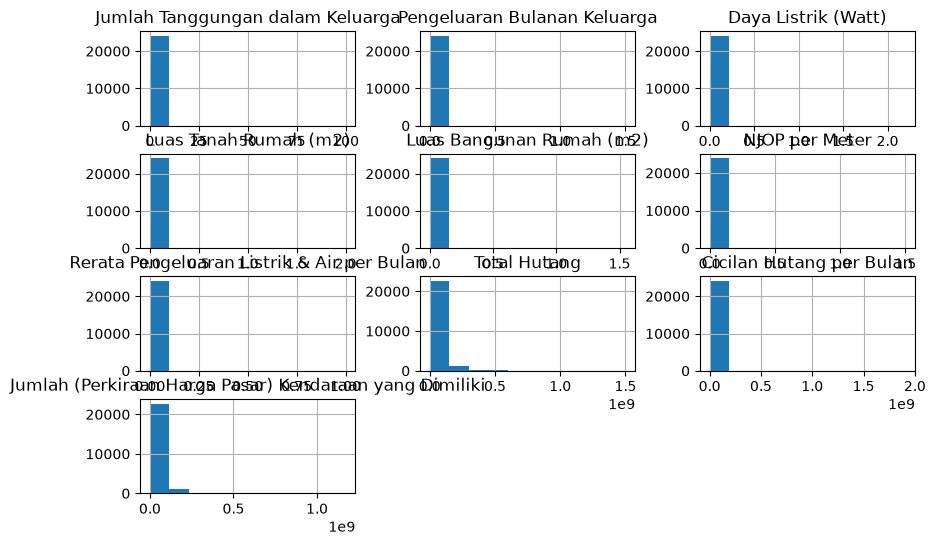

                                    mean  count
Pendapatan Keluarga                            
Rp 1.000.000 s.d. Rp 2.000.000  2.135825   5404
Rp 2.000.000 s.d. Rp 3.000.000  2.746060   4568
Rp 3.000.000 s.d. Rp 4.000.000  3.509704   3143
Rp 4.000.000 s.d. Rp 5.000.000  4.289228   2033
kurang dari Rp 1.000.000,-      2.022852   2188
lebih dari Rp 5.000.000         5.574926   6780 

                              mean  count
Pekerjaan Orang Tua/Wali                 
Buruh                     2.448573   5221
Nelayan                   2.703448    145
Pegawai Pemerintahan      5.593624   3231
Pegawai Swasta            4.457213   4090
Petani                    2.572091   2802
Tidak Bekerja             2.981637   3104
Wiraswasta                3.647631   5551 

                               mean  count
Pendidikan Orang Tua/Wali                 
D-1                        4.661972     71
D-3/D2                     4.451554    547
D1                         4.466667     30
D3/D-2             

In [4]:
print(train[TARGET].value_counts(normalize=True))
train[NUM_COLS].hist(figsize=(10, 6))
plt.show()

for col in CAT_COLS:
    print(train.groupby(col)[TARGET].agg(["mean", "count"]), "\n")

In [5]:
X_train = train[NUM_COLS + CAT_COLS]
y_train = train[TARGET]
X_val = valid[NUM_COLS + CAT_COLS]
y_val = valid[TARGET]

print("train:", X_train.shape, "| valid:", X_val.shape)

train: (24222, 23) | valid: (6076, 23)


In [6]:
num_steps = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
cat_steps = make_pipeline(SimpleImputer(strategy="most_frequent"),
                          OneHotEncoder(handle_unknown="ignore"))
preprocess = ColumnTransformer([
    ("num", num_steps, NUM_COLS),
    ("cat", cat_steps, CAT_COLS),
])

# model = LogisticRegression(C=1.0, max_iter=2000)                      # cepat, mudah dijelaskan
# model = RandomForestClassifier(n_estimators=500, random_state=SEED)
# model = ExtraTreesClassifier(n_estimators=500, random_state=SEED)
# model = HistGradientBoostingClassifier(random_state=SEED)
# model = LGBMClassifier(n_estimators=500, learning_rate=0.03, random_state=SEED, verbose=-1)
model = XGBClassifier(n_estimators=500, learning_rate=0.03, random_state=SEED)
# model = CatBoostClassifier(iterations=500, random_seed=SEED, verbose=0)
# model = SVC(C=1.0, random_state=SEED)
# model = KNeighborsClassifier(n_neighbors=15)
# model = DecisionTreeClassifier(max_depth=6, random_state=SEED)
# model = GradientBoostingClassifier(random_state=SEED)
# model = AdaBoostClassifier(n_estimators=300, random_state=SEED)
# model = BaggingClassifier(n_estimators=100, random_state=SEED)
# model = RidgeClassifier(alpha=1.0)
# model = MLPClassifier(hidden_layer_sizes=(64,), max_iter=1000, random_state=SEED)

pipe = make_pipeline(preprocess, model)
pipe.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('xgbclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](8,)","[0,1,2,...,5,6,7]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](23,)","['Jumlah Tanggungan dalam Keluarga','Pengeluaran Bulanan Keluarga', 'Daya Listrik (Watt)',...,'Bahan Lantai Rumah','Program Studi', 'Jalur Masuk']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,23
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-s

F1 macro: 0.4269
              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00      1111
         1.0       0.00      0.00      0.00        25
         2.0       0.42      0.22      0.29       462
         3.0       0.45      0.49      0.47      1018
         4.0       0.42      0.53      0.47      1323
         5.0       0.35      0.31      0.33       952
         6.0       0.32      0.23      0.27       597
         7.0       0.56      0.64      0.60       588

    accuracy                           0.53      6076
   macro avg       0.44      0.43      0.43      6076
weighted avg       0.52      0.53      0.52      6076



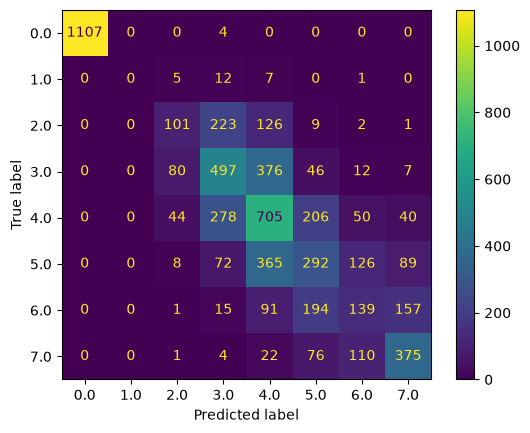

In [7]:
val_predictions = pipe.predict(X_val)
print("F1 macro:", round(f1_score(y_val, val_predictions, average="macro"), 4))
print(classification_report(y_val, val_predictions, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_val, val_predictions)
plt.show()

In [8]:
# prediksi data uji: isi TEST_CSV di cell 2, jalankan ulang semua cell
if len(test):
    test_predictions = pipe.predict(test[NUM_COLS + CAT_COLS]).astype(int)
    submission = pd.DataFrame({"id": pd.read_csv(TEST_CSV)["id"], TARGET: test_predictions})
    submission.to_csv("submission.csv", index=False)
    print(submission[TARGET].value_counts().sort_index())